# SINGKAP: Pipeline Data, Analisis, dan Model AI

**Sistem Inteligensi Nusantara Guna Kebangkitan Aset Pusaka**

Notebook ini membangun seluruh fondasi data dan kecerdasan artifisial SINGKAP dari sumber terbuka, lalu mengemas hasilnya menjadi satu berkas ZIP yang rapi untuk tahap pengembangan web.

| Bagian | Isi | Keluaran utama |
|---|---|---|
| 1 | Konfigurasi, gaya visual, utilitas HTTP | Folder output, cache |
| 2 | Referensi provinsi, domain WBTbI, unsur kebudayaan | Tabel referensi |
| 3 | Data WBTbI dari Wikipedia beserta validasi | `wbtbi.csv` |
| 4 | Visibilitas digital (artikel, bahasa Inggris, pageview, gambar) | `wbtbi_visibilitas.csv` |
| 5 | Data daerah (batas provinsi, museum, situs, arus wisata BPS) | `provinsi.csv`, titik warisan |
| 6 | Indeks Ketakterlihatan Digital (IKD) dan uji ketahanan | `ikd_item.csv`, `ikd_provinsi.csv` |
| 7 | Uji statistik dan temuan otomatis | `insights.json` |
| 8 | Visualisasi statis dan interaktif | PNG dan HTML |
| 9 | Sistem rekomendasi berkeadilan (kurva relevansi vs pemerataan) | `recsys_config.json` |
| 10 | Model Kenali Rumah Adat (computer vision) | `rumah_adat.onnx` |
| 11 | Knowledge base RAG, router sapaan, kalibrasi, evaluasi | `kb_chunks.jsonl`, `intents.json` |
| 12 | Ekspor data web, manifest, README, ZIP | `SINGKAP_output.zip` |


In [1]:
# Pustaka tambahan (sisanya sudah tersedia di Colab)
!pip -q install rapidfuzz sentence-transformers onnx onnxruntime google-genai

## 1. Konfigurasi

In [2]:
import os, re, io, json, math, time, random, shutil, hashlib, unicodedata, warnings
import datetime as dt
from pathlib import Path
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
from urllib.parse import quote

import numpy as np
import pandas as pd
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
from bs4 import BeautifulSoup
from rapidfuzz import fuzz
from scipy import stats
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display, Markdown

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_colwidth', 90)

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Wajib diisi
CONTACT_EMAIL = 'np7863838@gmail.com'   # kontak tim untuk header User-Agent Wikimedia

# Opsi eksekusi
FAST_MODE = False            # True: uji cepat dengan sampel kecil
RUN_CV = True                # latih model Kenali Rumah Adat (aktifkan GPU)
RUN_GEMINI_TEST = True       # uji jawaban RAG end-to-end bila GEMINI_API_KEY tersedia
GEMINI_MODEL = 'gemini-3.5-flash-lite'   # disesuaikan otomatis bila nama ini tidak tersedia
EMBED_MODEL = 'intfloat/multilingual-e5-small'
CV_ARCH = 'efficientnet_b0'  # alternatif lebih ringan: 'mobilenet_v3_large'
BPS_VAR_ID = None            # isi manual bila pencarian otomatis variabel BPS kurang tepat
NDCG_MIN = 0.90              # batas minimum retensi relevansi saat memilih lambda
SEED = 42

random.seed(SEED)
np.random.seed(SEED)


def get_secret(name):
    try:
        from google.colab import userdata
        return userdata.get(name) or ''
    except Exception:
        return os.environ.get(name, '')


BPS_API_KEY = get_secret('BPS_API_KEY')
GEMINI_API_KEY = get_secret('GEMINI_API_KEY')

ROOT = Path('/content') if IN_COLAB else Path('.').resolve()
OUT = ROOT / 'SINGKAP_output'
CACHE = ROOT / 'singkap_cache'
INPUT = ROOT / 'singkap_input'      # file manual opsional (lihat README)
D = {
    'raw': OUT / '01_data_mentah',
    'proc': OUT / '02_data_olahan',
    'ana': OUT / '03_analisis',
    'fig': OUT / '04_visualisasi',
    'html': OUT / '04_visualisasi' / 'interaktif',
    'cv': OUT / '05_model_cv',
    'rec': OUT / '06_rekomendasi',
    'rag': OUT / '07_rag',
    'web': OUT / '08_data_web',
    'meta': OUT / '09_manifest',
}
for p in [*D.values(), CACHE, INPUT]:
    p.mkdir(parents=True, exist_ok=True)

RUN_LOG = {'mulai': dt.datetime.now().isoformat(timespec='seconds'), 'langkah': [], 'peringatan': []}
MANIFEST = []


def log(msg):
    print(msg)
    RUN_LOG['langkah'].append(f'{dt.datetime.now():%H:%M:%S} {msg}')


def warn(msg):
    print('PERINGATAN:', msg)
    RUN_LOG['peringatan'].append(msg)


def register_source(dataset, url, license_, note='', n=None):
    MANIFEST.append({'dataset': dataset, 'url': url, 'lisensi': license_, 'catatan': note,
                     'jumlah_baris': n, 'tanggal_ambil': dt.date.today().isoformat()})


if CONTACT_EMAIL.startswith('isi-'):
    warn('CONTACT_EMAIL belum diganti. Ganti dengan email tim sebelum menjalankan scraping.')
log(f'Colab: {IN_COLAB} | FAST_MODE: {FAST_MODE} | Output: {OUT}')

Colab: True | FAST_MODE: False | Output: /content/SINGKAP_output


In [3]:
from google.colab import files
up = files.upload()
for name, content in up.items():
    (INPUT / 'bps_arus_wisata.csv').write_bytes(content)
print('Tersimpan di', INPUT / 'bps_arus_wisata.csv')

Saving bps_arus_wisata.csv to bps_arus_wisata.csv
Tersimpan di /content/singkap_input/bps_arus_wisata.csv


### Gaya visual
Palet diambil dari pewarna alam Nusantara dan dipakai ulang di web agar identitas visual konsisten.

In [4]:
PAL = {'tarum': '#1E2A4A', 'soga': '#6B4A2F', 'kunyit': '#E3A72F',
       'mengkudu': '#9E3B2E', 'kapas': '#F3EFE6', 'abu': '#8A8F98', 'daun': '#4F7A55'}
DOMAIN_COLORS = ['#1E2A4A', '#6B4A2F', '#E3A72F', '#9E3B2E', '#4F7A55']

plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 200, 'figure.facecolor': 'white',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#444444',
    'axes.titleweight': 'bold', 'axes.titlesize': 13, 'axes.titlelocation': 'left',
    'axes.labelsize': 11, 'axes.grid': True, 'grid.color': '#E9E9E9', 'axes.axisbelow': True,
    'font.size': 10.5, 'legend.frameon': False,
})

FIGS = []


def save_fig(fig, name, caption, dpi=None):
    path = D['fig'] / f'{name}.png'
    fig.savefig(path, bbox_inches='tight', dpi=dpi or plt.rcParams['savefig.dpi'])
    FIGS.append({'file': f'04_visualisasi/{path.name}', 'caption': caption})
    plt.show()
    plt.close(fig)
    return path


def fmt_pct(x, d=1):
    return f'{x * 100:.{d}f}%'.replace('.', ',')


def fmt_num(x):
    return f'{int(round(x)):,}'.replace(',', '.')


def fmt_dec(x, d=2):
    return f'{x:.{d}f}'.replace('.', ',')

### Utilitas HTTP
Semua permintaan memakai sesi dengan retry otomatis dan cache lokal, sehingga notebook aman dijalankan ulang tanpa membebani server.

In [5]:
def chunked(seq, n):
    seq = list(seq)
    for i in range(0, len(seq), n):
        yield seq[i:i + n]


SESSION = requests.Session()
SESSION.headers.update({'User-Agent': f'SINGKAP-research/1.0 (kompetisi BUDAYA GO!; {CONTACT_EMAIL})'})
_retry = Retry(total=5, backoff_factor=1.5, status_forcelist=(429, 500, 502, 503, 504),
               allowed_methods=frozenset(['GET', 'POST']), respect_retry_after_header=True)
SESSION.mount('https://', HTTPAdapter(max_retries=_retry, pool_maxsize=16))


def _cache_file(kind, key):
    folder = CACHE / kind
    folder.mkdir(parents=True, exist_ok=True)
    return folder / (hashlib.md5(key.encode('utf-8')).hexdigest() + '.json')


def http_get_json(url, params=None, kind='http', ok404=False, timeout=60, pause=0.0):
    key = url + '?' + json.dumps(params or {}, sort_keys=True, ensure_ascii=False)
    f = _cache_file(kind, key)
    if f.exists():
        return json.loads(f.read_text(encoding='utf-8'))
    r = SESSION.get(url, params=params, timeout=timeout)
    if ok404 and r.status_code == 404:
        data = None
    else:
        r.raise_for_status()
        data = r.json()
    f.write_text(json.dumps(data, ensure_ascii=False), encoding='utf-8')
    if pause:
        time.sleep(pause)
    return data


def http_post_json(url, data, kind='http', timeout=400):
    key = url + '#POST#' + json.dumps(data, sort_keys=True, ensure_ascii=False)
    f = _cache_file(kind, key)
    if f.exists():
        return json.loads(f.read_text(encoding='utf-8'))
    r = SESSION.post(url, data=data, timeout=timeout)
    r.raise_for_status()
    out = r.json()
    f.write_text(json.dumps(out, ensure_ascii=False), encoding='utf-8')
    return out


def http_get_bytes(url, timeout=60):
    r = SESSION.get(url, timeout=timeout)
    r.raise_for_status()
    return r.content

## 2. Referensi: provinsi, domain WBTbI, unsur kebudayaan, dan kepekaan budaya
Analisis daerah memakai skema **34 provinsi**. Provinsi hasil pemekaran 2022 (Papua Selatan, Papua Tengah, Papua Pegunungan, Papua Barat Daya) digabung ke provinsi induknya agar selaras dengan data historis penetapan WBTbI dan data statistik.

In [6]:
def norm_txt(s):
    s = unicodedata.normalize('NFKD', str(s)).encode('ascii', 'ignore').decode()
    s = s.lower()
    s = re.sub(r'\[[^\]]*\]', ' ', s)
    s = re.sub(r'\b(provinsi|province|prov)\b', ' ', s)
    s = re.sub(r'[^a-z0-9]+', ' ', s)
    return re.sub(r'\s+', ' ', s).strip()


PROV_ALIASES = {
    'Aceh': ['nanggroe aceh darussalam', 'nad', 'daerah istimewa aceh'],
    'Sumatera Utara': ['sumatra utara', 'north sumatra', 'north sumatera', 'sumut'],
    'Sumatera Barat': ['sumatra barat', 'west sumatra', 'west sumatera', 'sumbar'],
    'Riau': [],
    'Jambi': [],
    'Sumatera Selatan': ['sumatra selatan', 'south sumatra', 'south sumatera', 'sumsel'],
    'Bengkulu': [],
    'Lampung': [],
    'Kepulauan Bangka Belitung': ['bangka belitung', 'bangka belitung islands', 'babel', 'bangka-belitung'],
    'Kepulauan Riau': ['riau islands', 'kepri'],
    'DKI Jakarta': ['jakarta', 'daerah khusus ibukota jakarta', 'daerah khusus jakarta', 'jakarta raya',
                    'special capital region of jakarta', 'jakarta special capital region', 'dki'],
    'Jawa Barat': ['west java', 'jabar'],
    'Jawa Tengah': ['central java', 'jateng'],
    'DI Yogyakarta': ['daerah istimewa yogyakarta', 'yogyakarta', 'special region of yogyakarta', 'diy', 'jogjakarta'],
    'Jawa Timur': ['east java', 'jatim'],
    'Banten': [],
    'Bali': [],
    'Nusa Tenggara Barat': ['west nusa tenggara', 'ntb'],
    'Nusa Tenggara Timur': ['east nusa tenggara', 'ntt'],
    'Kalimantan Barat': ['west kalimantan', 'kalbar'],
    'Kalimantan Tengah': ['central kalimantan', 'kalteng'],
    'Kalimantan Selatan': ['south kalimantan', 'kalsel'],
    'Kalimantan Timur': ['east kalimantan', 'kaltim'],
    'Kalimantan Utara': ['north kalimantan', 'kaltara'],
    'Sulawesi Utara': ['north sulawesi', 'sulut'],
    'Sulawesi Tengah': ['central sulawesi', 'sulteng'],
    'Sulawesi Selatan': ['south sulawesi', 'sulsel'],
    'Sulawesi Tenggara': ['southeast sulawesi', 'south east sulawesi', 'sultra'],
    'Gorontalo': [],
    'Sulawesi Barat': ['west sulawesi', 'sulbar'],
    'Maluku': ['moluccas'],
    'Maluku Utara': ['north maluku', 'malut'],
    'Papua Barat': ['west papua', 'irian jaya barat', 'papua barat daya', 'southwest papua', 'south west papua'],
    'Papua': ['papua selatan', 'papua tengah', 'papua pegunungan', 'south papua', 'central papua',
              'highland papua', 'papua highlands', 'irian jaya'],
}
PROV34 = list(PROV_ALIASES)
_ALIAS = {}
for _prov, _al in PROV_ALIASES.items():
    for _a in [_prov] + _al:
        _ALIAS[norm_txt(_a)] = _prov


def to_prov34(name, fuzzy=False):
    if name is None or (isinstance(name, float) and math.isnan(name)):
        return None
    k = norm_txt(name)
    if k in _ALIAS:
        return _ALIAS[k]
    if fuzzy and k:
        best, score = None, 0
        for a, prov in _ALIAS.items():
            sc = fuzz.ratio(k, a)
            if sc > score:
                best, score = prov, sc
        if score >= 88:
            return best
    return None


# Koordinat ibu kota provinsi (perkiraan), dipakai bila poligon batas provinsi gagal dimuat
PROV_CAPITAL = {
    'Aceh': (5.55, 95.32), 'Sumatera Utara': (3.59, 98.67), 'Sumatera Barat': (-0.95, 100.35),
    'Riau': (0.51, 101.45), 'Jambi': (-1.61, 103.61), 'Sumatera Selatan': (-2.99, 104.76),
    'Bengkulu': (-3.80, 102.27), 'Lampung': (-5.43, 105.26), 'Kepulauan Bangka Belitung': (-2.13, 106.11),
    'Kepulauan Riau': (0.92, 104.45), 'DKI Jakarta': (-6.21, 106.85), 'Jawa Barat': (-6.91, 107.61),
    'Jawa Tengah': (-6.97, 110.42), 'DI Yogyakarta': (-7.80, 110.36), 'Jawa Timur': (-7.25, 112.75),
    'Banten': (-6.12, 106.15), 'Bali': (-8.65, 115.22), 'Nusa Tenggara Barat': (-8.58, 116.12),
    'Nusa Tenggara Timur': (-10.17, 123.61), 'Kalimantan Barat': (-0.03, 109.33),
    'Kalimantan Tengah': (-2.21, 113.92), 'Kalimantan Selatan': (-3.44, 114.83),
    'Kalimantan Timur': (-0.50, 117.15), 'Kalimantan Utara': (2.84, 117.37), 'Sulawesi Utara': (1.47, 124.84),
    'Sulawesi Tengah': (-0.90, 119.87), 'Sulawesi Selatan': (-5.15, 119.43), 'Sulawesi Tenggara': (-3.97, 122.51),
    'Gorontalo': (0.54, 123.06), 'Sulawesi Barat': (-2.68, 118.89), 'Maluku': (-3.70, 128.18),
    'Maluku Utara': (0.79, 127.38), 'Papua Barat': (-0.86, 134.06), 'Papua': (-2.53, 140.72),
}

DOMAIN_LABEL = {
    'ADAT_RITUS': 'Adat Istiadat Masyarakat, Ritus, dan Perayaan',
    'KERAJINAN': 'Kemahiran dan Kerajinan Tradisional',
    'PENGETAHUAN_ALAM': 'Pengetahuan dan Kebiasaan Perilaku Mengenai Alam dan Semesta',
    'PERTUNJUKAN': 'Seni Pertunjukan',
    'LISAN': 'Tradisi dan Ekspresi Lisan',
}
DOMAIN_SHORT = {'ADAT_RITUS': 'Adat & Ritus', 'KERAJINAN': 'Kerajinan', 'PENGETAHUAN_ALAM': 'Pengetahuan Alam',
                'PERTUNJUKAN': 'Seni Pertunjukan', 'LISAN': 'Tradisi Lisan'}
_DOMAIN_PHRASES = [
    ('PERTUNJUKAN', ['seni pertunjukan']),
    ('LISAN', ['ekspresi lisan', 'tradisi lisan']),
    ('KERAJINAN', ['kemahiran dan kerajinan', 'kerajinan tradisional']),
    ('PENGETAHUAN_ALAM', ['pengetahuan dan kebiasaan', 'mengenai alam', 'alam dan semesta']),
    ('ADAT_RITUS', ['adat istiadat', 'ritus dan perayaan', 'ritus']),
]


def to_domain(text):
    k = norm_txt(text)
    if not k or len(k) > 110:
        return None
    for code, phrases in _DOMAIN_PHRASES:
        if any(ph in k for ph in phrases):
            return code
    return None


UNSUR_KOENTJARA = {
    'LISAN': ['Bahasa', 'Kesenian'],
    'PERTUNJUKAN': ['Kesenian'],
    'ADAT_RITUS': ['Sistem religi', 'Organisasi sosial'],
    'PENGETAHUAN_ALAM': ['Sistem pengetahuan', 'Sistem mata pencaharian'],
    'KERAJINAN': ['Sistem peralatan hidup dan teknologi', 'Sistem mata pencaharian'],
}

# Penjaga Kepekaan Budaya: aturan awal, ditinjau ulang bersama pemda dan komunitas
SENSITIVE_RE = re.compile(r'\b(upacara|ritual|ritus|sakral|kematian|pemakaman|ruwatan|sesaji|sesajen|'
                          r'labuh|labuhan|pengobatan|mantra|jamasan|ngaben|kesurupan|tolak bala|tulak bala)\b', re.I)


def sensitivity(domain_code, name):
    reasons = []
    if domain_code == 'ADAT_RITUS':
        reasons.append('domain adat istiadat, ritus, dan perayaan')
    m = SENSITIVE_RE.search(str(name))
    if m:
        reasons.append(f'kata kunci "{m.group(0).lower()}"')
    return ('perlu_persetujuan' if reasons else 'terbuka'), '; '.join(reasons)


print('Provinsi:', len(PROV34), '| Domain:', len(DOMAIN_LABEL))
print('Uji alias:', to_prov34('Daerah Istimewa Yogyakarta'), '|', to_prov34('Papua Pegunungan'), '|',
      to_prov34('East Java', fuzzy=True), '|', to_prov34('Sumatra Utara'))

Provinsi: 34 | Domain: 5
Uji alias: DI Yogyakarta | Papua | Jawa Timur | Sumatera Utara


## 3. Data WBTbI
Sumber utama: halaman Wikipedia bahasa Indonesia *Daftar Warisan Budaya Takbenda Indonesia* (CC BY-SA 4.0), diambil melalui MediaWiki API. Parser mengenali baris penetapan dari **nomor registrasi 9 digit** (empat digit tahun diikuti lima digit urut), sehingga tahan terhadap perbedaan urutan kolom.

Hasilnya divalidasi terhadap angka resmi kumulatif penetapan. Bila cakupan rendah, notebook otomatis memakai berkas manual `singkap_input/wbtbi_manual.csv` (kolom: `no_registrasi, tahun, nama, domain, provinsi`).

In [7]:
WBTBI_PAGE = 'Daftar Warisan Budaya Takbenda Indonesia'
WBTBI_URL = 'https://id.wikipedia.org/wiki/' + WBTBI_PAGE.replace(' ', '_')
REG_RE = re.compile(r'^\s*(20[1-3]\d)(\d{5})\s*$')

# Angka resmi kumulatif penetapan WBTbI (lihat daftar pustaka dokumen konsep)
OFFICIAL_CUMULATIVE = {2017: 594, 2022: 1728, 2023: 1941, 2024: 2213, 2025: 2727}


def fetch_wbtbi_html():
    data = http_get_json('https://id.wikipedia.org/w/api.php',
                         {'action': 'parse', 'page': WBTBI_PAGE, 'prop': 'text|revid', 'redirects': 1,
                          'format': 'json', 'formatversion': 2}, kind='wiki_parse')
    return data['parse']['text'], data['parse'].get('revid')


def _clean(t):
    t = re.sub(r'\[\s*(sunting|edit|sunting sumber)[^\]]*\]', '', t, flags=re.I)
    t = re.sub(r'\[\d+\]', '', t)
    return re.sub(r'\s+', ' ', t).strip()


def _header_map(table):
    for tr in table.find_all('tr'):
        ths = tr.find_all('th', recursive=False)
        if len(ths) >= 2:
            hm = {}
            for i, th in enumerate(ths):
                h = re.sub(r'[^a-z ]+', ' ', th.get_text(' ').lower()).strip()
                if 'registrasi' in h or h.startswith('nomor') or h == 'no':
                    hm.setdefault('reg', i)
                elif 'tahun' in h:
                    hm.setdefault('tahun', i)
                elif 'karya' in h or 'nama' in h or 'warisan' in h:
                    hm.setdefault('nama', i)
                elif 'domain' in h or 'kategori' in h:
                    hm.setdefault('domain', i)
                elif 'provinsi' in h or 'asal' in h or 'daerah' in h:
                    hm.setdefault('prov', i)
            return hm, len(ths)
    return {}, 0


def table_grid(table):
    # Mengembangkan rowspan dan colspan sehingga setiap baris memiliki seluruh selnya
    grid, spans = [], {}
    for tr in table.find_all('tr'):
        cells = tr.find_all(['td', 'th'], recursive=False)
        row, ci, col = {}, 0, 0
        while ci < len(cells) or any(k >= col for k in spans):
            if col in spans:
                left, cell = spans[col]
                row[col] = cell
                if left <= 1:
                    del spans[col]
                else:
                    spans[col] = (left - 1, cell)
                col += 1
                continue
            if ci >= len(cells):
                col += 1
                if col > 20:
                    break
                continue
            c = cells[ci]
            ci += 1
            rs, cs = int(c.get('rowspan', 1) or 1), int(c.get('colspan', 1) or 1)
            for _ in range(cs):
                row[col] = c
                if rs > 1:
                    spans[col] = (rs - 1, c)
                col += 1
        grid.append([row[k] for k in sorted(row)])
    return grid


def parse_wbtbi(html):
    soup = BeautifulSoup(html, 'lxml')
    root = soup.select_one('.mw-parser-output') or soup
    rows, heading = [], None
    for el in root.find_all(['h2', 'h3', 'h4', 'table']):
        if el.name != 'table':
            heading = _clean(el.get_text(' ', strip=True))
            continue
        if el.find_parent('table') is not None:
            continue
        hm, ncol = _header_map(el)
        for cells in table_grid(el):
            if len(cells) < 2:
                continue
            texts = [_clean(c.get_text(' ', strip=True)) for c in cells]
            reg_i = next((i for i, t in enumerate(texts) if REG_RE.match(t)), None)
            if reg_i is None:
                continue
            m = REG_RE.match(texts[reg_i])
            use_header = bool(hm) and len(cells) == ncol and 'nama' in hm
            dom_i = hm.get('domain') if use_header else next(
                (i for i, t in enumerate(texts) if i != reg_i and to_domain(t)), None)
            prov_i = hm.get('prov') if use_header else next(
                (i for i, t in enumerate(texts) if i not in (reg_i, dom_i) and to_prov34(t) and len(t) < 45), None)
            year_i = hm.get('tahun') if use_header else next(
                (i for i, t in enumerate(texts) if re.fullmatch(r'20[1-3]\d', t)), None)
            if use_header:
                name_i = hm['nama']
            else:
                cand = [i for i, t in enumerate(texts)
                        if i not in (reg_i, dom_i, prov_i, year_i) and t and not re.fullmatch(r'[\d\s.,]+', t)]
                linked = [i for i in cand if cells[i].find('a')]
                pool = linked or cand
                name_i = max(pool, key=lambda i: len(texts[i])) if pool else None
            if name_i is None or not texts[name_i]:
                continue
            a = cells[name_i].find('a')
            link_title, redlink = None, False
            if a is not None:
                link_title = re.sub(r'\s*\((halaman belum tersedia|page does not exist)\)\s*$', '',
                                    a.get('title') or a.get_text(' ', strip=True))
                redlink = 'new' in (a.get('class') or []) or 'redlink=1' in (a.get('href') or '')
            tahun = int(texts[year_i]) if year_i is not None and re.fullmatch(r'20[1-3]\d', texts[year_i]) \
                else int(m.group(1))
            rows.append({
                'no_registrasi': m.group(1) + m.group(2),
                'tahun': tahun,
                'nama': texts[name_i],
                'wiki_link_title': link_title,
                'redlink_tabel': redlink,
                'domain_raw': texts[dom_i] if dom_i is not None and dom_i < len(texts) else None,
                'provinsi_raw': texts[prov_i] if prov_i is not None and prov_i < len(texts) else None,
                'bagian': heading,
            })
    return pd.DataFrame(rows)


def parse_wbtbi_by_header(html):
    # Cadangan bila tabel tidak memuat nomor registrasi: baca berdasarkan judul kolom
    soup = BeautifulSoup(html, 'lxml')
    root = soup.select_one('.mw-parser-output') or soup
    rows, heading, counter = [], None, Counter()
    for el in root.find_all(['h2', 'h3', 'h4', 'table']):
        if el.name != 'table':
            heading = _clean(el.get_text(' ', strip=True))
            continue
        if el.find_parent('table') is not None:
            continue
        hm, ncol = _header_map(el)
        if 'nama' not in hm or not ({'domain', 'prov', 'tahun'} & set(hm)):
            continue
        for tr in el.find_all('tr'):
            cells = tr.find_all(['td', 'th'], recursive=False)
            if len(cells) != ncol or tr.find('th') is not None and not tr.find('td'):
                continue
            texts = [_clean(c.get_text(' ', strip=True)) for c in cells]
            ytxt = texts[hm['tahun']] if 'tahun' in hm else (heading or '')
            ym = re.search(r'20[1-3]\d', ytxt)
            if not ym or not texts[hm['nama']]:
                continue
            tahun = int(ym.group(0))
            counter[tahun] += 1
            a = cells[hm['nama']].find('a')
            rows.append({
                'no_registrasi': f'{tahun}{counter[tahun]:05d}', 'tahun': tahun, 'nama': texts[hm['nama']],
                'wiki_link_title': re.sub(r'\s*\((halaman belum tersedia|page does not exist)\)\s*$', '',
                                          a.get('title') or a.get_text(' ', strip=True)) if a else None,
                'redlink_tabel': bool(a and 'new' in (a.get('class') or [])),
                'domain_raw': texts[hm['domain']] if 'domain' in hm else None,
                'provinsi_raw': texts[hm['prov']] if 'prov' in hm else None,
                'bagian': heading, 'registrasi_sintetis': True,
            })
    return pd.DataFrame(rows)


html, revid = fetch_wbtbi_html()
(D['raw'] / 'wbtbi_wikipedia.html').write_text(html, encoding='utf-8')
wb_raw = parse_wbtbi(html)
if len(wb_raw) < 100:
    alt = parse_wbtbi_by_header(html)
    if len(alt) > len(wb_raw):
        warn('Nomor registrasi tidak ditemukan pada tabel; memakai pembacaan berdasarkan judul kolom '
             '(nomor registrasi dibuat sementara dari tahun dan urutan).')
        wb_raw = alt
log(f'Baris penetapan terbaca dari Wikipedia: {len(wb_raw)} (revisi {revid})')
wb_raw.head()

Baris penetapan terbaca dari Wikipedia: 1941 (revisi 30175284)


,no_registrasi,tahun,nama,wiki_link_title,redlink_tabel,domain_raw,provinsi_raw,bagian
0,201300001,2013,Rencong,Rencong,False,Keterampilan dan kemahiran kerajinan tradisional,None,Aceh
1,201300074,2013,Tari Saman,Tari Saman,False,Seni pertunjukan,None,Aceh
2,201400078,2014,Didong,Didong,False,Tradisi dan ekspresi lisan,None,Aceh
3,201400079,2014,Kerawang Gayo,Kerawang Gayo,False,Keterampilan dan kemahiran kerajinan tradisional,None,Aceh
4,201400080,2014,Tari Seudati,Tari Seudati,False,Seni pertunjukan,None,Aceh


In [8]:
def validate_wbtbi(df):
    if df.empty:
        return 0.0, pd.DataFrame()
    per_year = df.groupby('tahun').size().sort_index()
    cum = per_year.cumsum()
    rows = []
    for y, official in OFFICIAL_CUMULATIVE.items():
        got = int(cum[cum.index <= y].iloc[-1]) if (cum.index <= y).any() else 0
        rows.append({'sampai_tahun': y, 'resmi_kumulatif': official, 'terbaca_kumulatif': got,
                     'cakupan': got / official})
    val = pd.DataFrame(rows)
    return float(val['cakupan'].iloc[-1]), val


def load_manual_wbtbi(path):
    m = pd.read_csv(path)
    m.columns = [norm_txt(c).replace(' ', '_') for c in m.columns]
    need = {'no_registrasi', 'tahun', 'nama', 'domain', 'provinsi'}
    missing = need - set(m.columns)
    if missing:
        raise ValueError(f'Kolom wajib tidak ada di {path.name}: {missing}')
    return pd.DataFrame({'no_registrasi': m['no_registrasi'].astype(str), 'tahun': m['tahun'].astype(int),
                         'nama': m['nama'].astype(str), 'wiki_link_title': None, 'redlink_tabel': False,
                         'domain_raw': m['domain'], 'provinsi_raw': m['provinsi'], 'bagian': None})


coverage, val = validate_wbtbi(wb_raw)
display(val)
manual_path = INPUT / 'wbtbi_manual.csv'
WBTBI_SOURCE = 'wikipedia'
if manual_path.exists():
    wb_raw = load_manual_wbtbi(manual_path)
    WBTBI_SOURCE = 'manual'
    coverage, val = validate_wbtbi(wb_raw)
    log(f'Memakai berkas manual {manual_path.name}: {len(wb_raw)} baris, cakupan {fmt_pct(coverage)}')
elif coverage < 0.70:
    warn(f'Cakupan data WBTbI dari Wikipedia hanya {fmt_pct(coverage)}. Siapkan {manual_path} '
         'dari situs resmi lalu jalankan ulang. Analisis tetap berjalan dengan data yang ada.')
else:
    log(f'Cakupan data WBTbI terhadap angka resmi 2025: {fmt_pct(coverage)}')
if wb_raw.empty:
    raise RuntimeError(f'Data WBTbI kosong. Struktur halaman Wikipedia berubah. Siapkan {manual_path} '
                       '(kolom: no_registrasi, tahun, nama, domain, provinsi) lalu jalankan ulang dari bagian 3.')
val.to_csv(D['ana'] / 'validasi_cakupan_wbtbi.csv', index=False)

,sampai_tahun,resmi_kumulatif,terbaca_kumulatif,cakupan
0,2017,594,594,1.000000
1,2022,1728,1728,1.000000
2,2023,1941,1941,1.000000
3,2024,2213,1941,0.877090
4,2025,2727,1941,0.711771


Cakupan data WBTbI terhadap angka resmi 2025: 71,2%


In [9]:
wb = wb_raw.copy()
wb['domain'] = wb['domain_raw'].map(to_domain)
wb['provinsi'] = [to_prov34(p) or to_prov34(b) or to_prov34(p, fuzzy=True) or to_prov34(b, fuzzy=True)
                  for p, b in zip(wb['provinsi_raw'], wb['bagian'])]
wb['provinsi'] = wb['provinsi'].fillna('Lintas provinsi / tidak terpetakan')
wb['nama'] = wb['nama'].str.replace(r'\s+', ' ', regex=True).str.strip()
wb = wb.drop_duplicates('no_registrasi').sort_values(['tahun', 'no_registrasi']).reset_index(drop=True)
wb['id'] = 'wbtbi_' + wb['no_registrasi']
sens = [sensitivity(d, n) for d, n in zip(wb['domain'], wb['nama'])]
wb['kepekaan'] = [s[0] for s in sens]
wb['alasan_kepekaan'] = [s[1] for s in sens]
wb['domain_label'] = wb['domain'].map(DOMAIN_LABEL).fillna('Tidak terklasifikasi')
wb['unsur_kebudayaan'] = wb['domain'].map(lambda d: ', '.join(UNSUR_KOENTJARA.get(d, [])))

quality = {
    'jumlah_baris': len(wb),
    'domain_terklasifikasi': float(wb['domain'].notna().mean()),
    'provinsi_terpetakan': float(wb['provinsi'].isin(PROV34).mean()),
    'baris_bertautan': float(wb['wiki_link_title'].notna().mean()),
    'cakupan_vs_resmi_2025': coverage,
    'sumber': WBTBI_SOURCE,
}
for k, v in quality.items():
    print(f'{k:>24}: {fmt_pct(v) if isinstance(v, float) else v}')
if quality['domain_terklasifikasi'] < 0.8:
    warn('Banyak baris tanpa domain. Periksa kolom domain pada sumber data.')
if quality['provinsi_terpetakan'] < 0.8:
    warn('Banyak baris tanpa provinsi. Periksa judul bagian halaman sumber.')

wb.to_csv(D['proc'] / 'wbtbi.csv', index=False)
register_source('Daftar WBTbI (Wikipedia bahasa Indonesia)', WBTBI_URL, 'CC BY-SA 4.0',
                f'revisi {revid}; sumber dipakai: {WBTBI_SOURCE}', len(wb))
display(wb['domain_label'].value_counts())

            jumlah_baris: 1925
   domain_terklasifikasi: 99,8%
     provinsi_terpetakan: 99,1%
         baris_bertautan: 99,6%
   cakupan_vs_resmi_2025: 71,2%
                  sumber: wikipedia


,count
domain_label,
Seni Pertunjukan,568
"Adat Istiadat Masyarakat, Ritus, dan Perayaan",552
Kemahiran dan Kerajinan Tradisional,473
Tradisi dan Ekspresi Lisan,240
Pengetahuan dan Kebiasaan Perilaku Mengenai Alam dan Semesta,88
Tidak terklasifikasi,4


## 4. Visibilitas digital setiap warisan
Untuk setiap WBTbI, notebook memeriksa: (1) apakah ada artikel Wikipedia bahasa Indonesia, (2) apakah ada versi bahasa Inggris, (3) jumlah kunjungan halaman 12 bulan terakhir, (4) panjang artikel, (5) keberadaan gambar utama, dan (6) keberadaan butir Wikidata.

**Penautan entitas.** Tautan dari tabel dipakai lebih dulu. Untuk warisan tanpa artikel, notebook mencari artikel dengan judul berbeda lewat pencarian Wikipedia, lalu menerima kandidat hanya bila kemiripannya tinggi. Sampel hasil pencarian diekspor untuk diverifikasi manual sehingga presisinya bisa dilaporkan.

In [10]:
WIKI_API = 'https://{lang}.wikipedia.org/w/api.php'


def wiki_query(params, lang='id', kind='wiki_query'):
    base = {'action': 'query', 'format': 'json', 'formatversion': 2, **params}
    pages, norm_map, redir_map, cont = {}, {}, {}, {}
    while True:
        data = http_get_json(WIKI_API.format(lang=lang), {**base, **cont}, kind=kind)
        q = data.get('query', {})
        for n in q.get('normalized', []):
            norm_map[n['from']] = n['to']
        for r in q.get('redirects', []):
            redir_map[r['from']] = r['to']
        for p in q.get('pages', []):
            cur = pages.setdefault(p['title'], {})
            for k, v in p.items():
                if isinstance(v, list):
                    cur.setdefault(k, []).extend(v)
                elif isinstance(v, dict):
                    cur.setdefault(k, {}).update(v)
                else:
                    cur[k] = v
        if 'continue' in data:
            cont = data['continue']
        else:
            return pages, norm_map, redir_map


def resolve_title(t, norm_map, redir_map):
    t = norm_map.get(t, t)
    for _ in range(5):
        if t not in redir_map:
            break
        t = redir_map[t]
    return t


def fetch_page_status(titles, lang='id'):
    out = {}
    titles = sorted({t for t in titles if isinstance(t, str) and t.strip()})
    for batch in tqdm(list(chunked(titles, 50)), desc=f'Status artikel ({lang})'):
        pages, nm, rd = wiki_query({'titles': '|'.join(batch), 'prop': 'info|pageprops|langlinks|pageimages',
                                    'ppprop': 'wikibase_item|disambiguation', 'lllang': 'en', 'lllimit': 'max',
                                    'piprop': 'name', 'redirects': 1}, lang=lang)
        for t in batch:
            final = resolve_title(t, nm, rd)
            p = pages.get(final, {})
            exists = bool(p) and not p.get('missing') and not p.get('invalid')
            props = p.get('pageprops', {}) if exists else {}
            ll = p.get('langlinks') or []
            out[t] = {'judul_artikel': final if exists else None,
                      'ada_artikel': exists and 'disambiguation' not in props,
                      'disambiguasi': 'disambiguation' in props,
                      'panjang_byte': int(p.get('length', 0)) if exists else 0,
                      'wikidata': props.get('wikibase_item'),
                      'judul_en': ll[0].get('title') if ll else None,
                      'ada_gambar': bool(p.get('pageimage')) if exists else False}
    return out


def core_name(name):
    n = re.split(r'\s+-\s+', str(name))[0]
    return re.sub(r'\s*\(.*?\)\s*', ' ', n).strip()


def wiki_search(q, lang='id', n=5):
    data = http_get_json(WIKI_API.format(lang=lang), {'action': 'query', 'list': 'search', 'srsearch': q,
                                                      'srlimit': n, 'srnamespace': 0, 'format': 'json',
                                                      'formatversion': 2}, kind='wiki_search', pause=0.03)
    return [(h['title'], re.sub(r'<[^>]+>', '', h.get('snippet', ''))) for h in data.get('query', {}).get('search', [])]


def best_candidate(name, prov, hits):
    core = norm_txt(core_name(name))
    prov_k = norm_txt(prov) if prov in PROV34 else ''
    best_title, best_score = None, 0
    for title, snippet in hits:
        t = norm_txt(re.sub(r'\s*\(.*?\)\s*', ' ', title))
        s_set, s_full = fuzz.token_set_ratio(core, t), fuzz.ratio(core, t)
        hint = bool(prov_k) and prov_k in norm_txt(snippet)
        if s_set >= 90 and (s_full >= 75 or hint):
            score = s_set + (5 if hint else 0)
            if score > best_score:
                best_title, best_score = title, score
    return best_title, best_score


# 1) Status artikel untuk tautan langsung dari tabel
link_status = fetch_page_status(wb['wiki_link_title'].dropna().unique())
vis = wb[['id', 'nama', 'provinsi', 'wiki_link_title']].copy()
vis['metode_tautan'] = 'tidak_ditemukan'
vis['skor_tautan'] = np.nan
vis['judul_artikel'] = None
for i, t in vis['wiki_link_title'].items():
    st = link_status.get(t)
    if st and st['ada_artikel']:
        vis.at[i, 'judul_artikel'] = st['judul_artikel']
        vis.at[i, 'metode_tautan'] = 'tautan_tabel'
        vis.at[i, 'skor_tautan'] = 100

# 2) Pencarian untuk yang belum punya artikel
todo = vis[vis['judul_artikel'].isna()]
if FAST_MODE:
    todo = todo.head(150)


def _search_one(row):
    hits = wiki_search(core_name(row.nama))
    return row.Index, best_candidate(row.nama, row.provinsi, hits)


with ThreadPoolExecutor(max_workers=6) as ex:
    results = list(tqdm(ex.map(_search_one, todo.itertuples()), total=len(todo), desc='Pencarian artikel'))
found = {i: r for i, r in results if r[0]}
found_status = fetch_page_status([t for t, _ in found.values()])
for i, (title, score) in found.items():
    st = found_status.get(title)
    if st and st['ada_artikel']:
        vis.at[i, 'judul_artikel'] = st['judul_artikel']
        vis.at[i, 'metode_tautan'] = 'pencarian_fuzzy'
        vis.at[i, 'skor_tautan'] = score

all_status = {**link_status, **found_status}
final_status = {s['judul_artikel']: s for s in all_status.values() if s['ada_artikel']}
for col in ['wikidata', 'judul_en', 'panjang_byte', 'ada_gambar']:
    vis[col] = vis['judul_artikel'].map(lambda t: final_status.get(t, {}).get(col) if t else None)
vis['ada_artikel_id'] = vis['judul_artikel'].notna()
vis['ada_artikel_en'] = vis['judul_en'].notna()
vis['ada_wikidata'] = vis['wikidata'].notna()
vis['ada_gambar'] = vis['ada_gambar'].fillna(False).astype(bool)
vis['panjang_byte'] = vis['panjang_byte'].fillna(0).astype(int)
display(vis['metode_tautan'].value_counts())

# Sampel untuk verifikasi manual presisi penautan
sample = vis[vis['metode_tautan'] == 'pencarian_fuzzy'].sample(
    n=min(40, (vis['metode_tautan'] == 'pencarian_fuzzy').sum()), random_state=SEED)
sample.assign(benar_1_atau_0='')[['id', 'nama', 'provinsi', 'judul_artikel', 'skor_tautan', 'benar_1_atau_0']] \
    .to_csv(D['ana'] / 'sampel_verifikasi_penautan.csv', index=False)
log(f'Sampel verifikasi penautan diekspor: {len(sample)} baris')

Status artikel (id):   0%|          | 0/38 [00:00<?, ?it/s]

Pencarian artikel:   0%|          | 0/510 [00:00<?, ?it/s]

Status artikel (id):   0%|          | 0/1 [00:00<?, ?it/s]

,count
metode_tautan,
tautan_tabel,1415
tidak_ditemukan,469
pencarian_fuzzy,41


Sampel verifikasi penautan diekspor: 40 baris


In [11]:
# 3) Kunjungan halaman 12 bulan penuh terakhir (Wikimedia Pageviews API)
today = dt.date.today()
PV_END = today.replace(day=1) - dt.timedelta(days=1)                    # hari terakhir bulan lalu
PV_START = (PV_END.replace(day=1) - pd.DateOffset(months=11)).date()  # awal 12 bulan
PV_WINDOW = f'{PV_START:%Y-%m} s.d. {PV_END:%Y-%m}'


def pageviews(title, lang='id'):
    t = quote(title.replace(' ', '_'), safe='')
    url = (f'https://wikimedia.org/api/rest_v1/metrics/pageviews/per-article/{lang}.wikipedia/all-access/user/'
           f'{t}/monthly/{PV_START:%Y%m%d}00/{PV_END:%Y%m%d}00')
    data = http_get_json(url, kind='pageviews', ok404=True)
    return int(sum(i.get('views', 0) for i in (data or {}).get('items', [])))


titles = vis['judul_artikel'].dropna().unique().tolist()
with ThreadPoolExecutor(max_workers=8) as ex:
    pv = dict(zip(titles, tqdm(ex.map(pageviews, titles), total=len(titles), desc='Pageviews')))
vis['pageviews_12b'] = vis['judul_artikel'].map(pv).fillna(0).astype(int)

vis.to_csv(D['proc'] / 'wbtbi_visibilitas.csv', index=False)
register_source('Status artikel Wikipedia (MediaWiki API)', 'https://id.wikipedia.org/w/api.php', 'CC BY-SA 4.0',
                'keberadaan artikel, langlinks, pageprops', len(vis))
register_source('Wikimedia Pageviews API', 'https://wikimedia.org/api/rest_v1/', 'Data terbuka Wikimedia',
                f'jendela {PV_WINDOW}', len(titles))
print(f'Jendela pageviews: {PV_WINDOW}')
print('Punya artikel ID :', fmt_pct(vis['ada_artikel_id'].mean()))
print('Punya artikel EN :', fmt_pct(vis['ada_artikel_en'].mean()))

Pageviews:   0%|          | 0/1429 [00:00<?, ?it/s]

Jendela pageviews: 2025-11 s.d. 2026-10
Punya artikel ID : 75,6%
Punya artikel EN : 12,2%


## 5. Data daerah
* **Batas provinsi**: geoBoundaries (CC BY 4.0).
* **Museum dan situs warisan**: Wikidata (CC0) dan OpenStreetMap (ODbL).
* **Arus wisata**: BPS WebAPI (kunci API gratis). Bila tidak tersedia, notebook membuat templat `singkap_input/bps_arus_wisata.csv` untuk diisi dari tabel BPS, dan IKD sementara dihitung tanpa dimensi arus wisata dengan penanda yang jelas.

In [12]:
import geopandas as gpd
from shapely.geometry import Point

GB_API = 'https://www.geoboundaries.org/api/current/gbOpen/IDN/ADM1/'
GB_FALLBACK = ('https://media.githubusercontent.com/media/wmgeolab/geoBoundaries/main/releaseData/'
               'gbOpen/IDN/ADM1/geoBoundaries-IDN-ADM1_simplified.geojson')


def load_provinces():
    urls = []
    try:
        meta = http_get_json(GB_API, kind='geoboundaries')
        urls.append(meta.get('simplifiedGeometryGeoJSON') or meta.get('gjDownloadURL'))
    except Exception as e:
        warn(f'API geoBoundaries gagal: {e}')
    urls.append(GB_FALLBACK)
    for u in [u for u in urls if u]:
        try:
            gj = http_get_json(u, kind='geoboundaries_geojson', timeout=120)
            g = gpd.GeoDataFrame.from_features(gj['features'], crs='EPSG:4326')
            name_col = next(c for c in ['shapeName', 'name', 'NAME_1'] if c in g.columns)
            g['provinsi'] = g[name_col].map(lambda s: to_prov34(s, fuzzy=True))
            unmatched = g.loc[g['provinsi'].isna(), name_col].tolist()
            if unmatched:
                warn(f'Nama provinsi geoBoundaries tidak terpetakan: {unmatched}')
            g = g.dropna(subset=['provinsi']).dissolve(by='provinsi', as_index=False)[['provinsi', 'geometry']]
            register_source('Batas provinsi geoBoundaries (ADM1)', u, 'CC BY 4.0', 'disederhanakan', len(g))
            return g
        except Exception as e:
            warn(f'Gagal memuat batas provinsi dari {u}: {e}')
    return None


prov_gdf = load_provinces()
if prov_gdf is not None:
    rep = prov_gdf.to_crs(3857).representative_point().to_crs(4326)
    CENTROID = {p: (pt.y, pt.x) for p, pt in zip(prov_gdf['provinsi'], rep)}
    missing = [p for p in PROV34 if p not in CENTROID]
    for p in missing:
        CENTROID[p] = PROV_CAPITAL[p]
    log(f'Poligon provinsi: {len(prov_gdf)} (sisanya memakai koordinat ibu kota: {missing})')
else:
    CENTROID = dict(PROV_CAPITAL)
    warn('Peta choropleth dilewati karena batas provinsi tidak tersedia.')

Poligon provinsi: 34 (sisanya memakai koordinat ibu kota: [])


In [13]:
SPARQL_URL = 'https://query.wikidata.org/sparql'


def sparql(query):
    data = http_get_json(SPARQL_URL, {'query': query, 'format': 'json'}, kind='sparql', timeout=180)
    return data['results']['bindings']


def _point(wkt):
    m = re.match(r'Point\(([-\d.eE]+) ([-\d.eE]+)\)', wkt or '')
    return (float(m.group(2)), float(m.group(1))) if m else (None, None)


Q_MUSEUM = '''
SELECT DISTINCT ?item ?itemLabel ?coord WHERE {
  ?item wdt:P31/wdt:P279* wd:Q33506 ; wdt:P17 wd:Q252 ; wdt:P625 ?coord .
  SERVICE wikibase:label { bd:serviceParam wikibase:language "id,en". }
}'''
Q_HERITAGE = '''
SELECT DISTINCT ?item ?itemLabel ?coord ?desigLabel WHERE {
  ?item wdt:P17 wd:Q252 ; wdt:P1435 ?desig ; wdt:P625 ?coord .
  SERVICE wikibase:label { bd:serviceParam wikibase:language "id,en". }
}'''

points = []
for jenis, q in [('museum', Q_MUSEUM), ('situs_warisan', Q_HERITAGE)]:
    try:
        res = sparql(q)
        for b in res:
            lat, lon = _point(b['coord']['value'])
            if lat is not None:
                points.append({'sumber': 'wikidata', 'jenis': jenis, 'nama': b.get('itemLabel', {}).get('value'),
                               'ref': b['item']['value'].rsplit('/', 1)[-1], 'lat': lat, 'lon': lon,
                               'keterangan': b.get('desigLabel', {}).get('value')})
        register_source(f'Wikidata SPARQL ({jenis})', SPARQL_URL, 'CC0', 'butir berkoordinat di Indonesia', len(res))
    except Exception as e:
        warn(f'Kueri Wikidata {jenis} gagal: {e}')

OVERPASS_URLS = ['https://overpass-api.de/api/interpreter', 'https://overpass.kumi.systems/api/interpreter']
Q_OSM = '''[out:json][timeout:300];
area["ISO3166-1"="ID"][admin_level=2]->.id;
(
  nwr["tourism"="museum"](area.id);
  nwr["historic"~"^(archaeological_site|monument|memorial|castle|ruins|fort|tomb|temple|city_gate|manor)$"](area.id);
  nwr["heritage"](area.id);
);
out center tags;'''

osm_ok = False
for u in OVERPASS_URLS:
    try:
        res = http_post_json(u, {'data': Q_OSM}, kind='overpass', timeout=420)
        for el in res.get('elements', []):
            lat = el.get('lat') or (el.get('center') or {}).get('lat')
            lon = el.get('lon') or (el.get('center') or {}).get('lon')
            tags = el.get('tags', {})
            if lat is None:
                continue
            jenis = 'museum' if tags.get('tourism') == 'museum' else 'situs_warisan'
            points.append({'sumber': 'openstreetmap', 'jenis': jenis, 'nama': tags.get('name'),
                           'ref': f"{el['type']}/{el['id']}", 'lat': lat, 'lon': lon,
                           'keterangan': tags.get('historic') or tags.get('heritage')})
        register_source('OpenStreetMap (Overpass API)', u, 'ODbL 1.0', 'museum, historic, heritage',
                        len(res.get('elements', [])))
        osm_ok = True
        break
    except Exception as e:
        warn(f'Overpass {u} gagal: {e}')

pts = pd.DataFrame(points)
if not pts.empty:
    pts = pts.drop_duplicates(subset=['sumber', 'ref'])
    pts_gdf = gpd.GeoDataFrame(pts, geometry=[Point(xy) for xy in zip(pts['lon'], pts['lat'])], crs='EPSG:4326')
    if prov_gdf is not None:
        pts_gdf = gpd.sjoin(pts_gdf, prov_gdf, how='left', predicate='within').drop(columns='index_right')
    else:
        pts_gdf['provinsi'] = None
    pts_gdf.drop(columns='geometry').to_csv(D['proc'] / 'titik_warisan.csv', index=False)
    print(pts_gdf.groupby(['sumber', 'jenis']).size())
else:
    pts_gdf = None
    warn('Tidak ada titik museum atau situs yang berhasil diambil.')

sumber         jenis        
openstreetmap  museum            735
               situs_warisan    3676
wikidata       museum            806
               situs_warisan     671
dtype: int64


In [14]:
def bps_template():
    path = INPUT / 'bps_arus_wisata.csv'
    if not path.exists():
        pd.DataFrame({'provinsi': PROV34, 'nilai': '', 'tahun': '', 'satuan': 'perjalanan wisatawan nusantara',
                      'sumber': 'bps.go.id (tabel statistik)'}).to_csv(path, index=False)
    return path


def _bps_lists(js):
    found = []
    def walk(x):
        if isinstance(x, list):
            if x and all(isinstance(i, dict) for i in x) and any('var_id' in i for i in x):
                found.extend(x)
            for i in x:
                walk(i)
        elif isinstance(x, dict):
            for v in x.values():
                walk(v)
    walk(js)
    return found


def bps_arus_wisata():
    manual = INPUT / 'bps_arus_wisata.csv'
    if manual.exists():
        m = pd.read_csv(manual)
        m['provinsi'] = m['provinsi'].map(lambda s: to_prov34(s, fuzzy=True))
        m['nilai'] = pd.to_numeric(m['nilai'], errors='coerce')
        m = m.dropna(subset=['provinsi', 'nilai'])
        if len(m) >= 20:
            register_source('Arus wisata (berkas manual dari BPS)', 'bps.go.id', 'Data resmi BPS', manual.name, len(m))
            return m.groupby('provinsi')['nilai'].sum(), 'manual'
    if not BPS_API_KEY:
        warn(f'BPS_API_KEY tidak ditemukan. Isi templat {bps_template()} lalu jalankan ulang bagian ini.')
        return None, None
    base = 'https://webapi.bps.go.id/v1/api'
    var_id = BPS_VAR_ID
    if var_id is None:
        cands = []
        for kw in ['wisatawan nusantara', 'perjalanan wisatawan']:
            try:
                js = http_get_json(f'{base}/list/model/var/lang/ind/domain/0000/keyword/{quote(kw)}/key/{BPS_API_KEY}/',
                                   kind='bps')
                cands += _bps_lists(js)
            except Exception as e:
                warn(f'Pencarian variabel BPS gagal ({kw}): {e}')
        cands = {c['var_id']: c.get('title', '') for c in cands}
        ranked = sorted(cands.items(), key=lambda kv: (('provinsi' in kv[1].lower()) + ('tujuan' in kv[1].lower())),
                        reverse=True)
        for vid, title in ranked[:10]:
            print(f'  kandidat var_id={vid}: {title}')
        if not ranked:
            warn(f'Variabel BPS tidak ditemukan. Isi BPS_VAR_ID atau templat {bps_template()}.')
            return None, None
        var_id = ranked[0][0]
    js = http_get_json(f'{base}/list/model/data/lang/ind/domain/0000/var/{var_id}/key/{BPS_API_KEY}/', kind='bps')
    dc = js.get('datacontent', {})
    vervar = js.get('vervar', [])
    turvar = js.get('turvar') or [{'val': 0}]
    tahun = js.get('tahun', [])
    turth = js.get('turtahun') or [{'val': 0}]
    best = None
    for th in sorted(tahun, key=lambda x: x['label'], reverse=True):
        vals = {}
        for vv in vervar:
            prov = to_prov34(str(vv['label']).title(), fuzzy=True)
            if not prov:
                continue
            for tv in turvar:
                for tt in turth:
                    key = f"{vv['val']}{var_id}{tv['val']}{th['val']}{tt['val']}"
                    if key in dc and dc[key] not in (None, ''):
                        vals[prov] = vals.get(prov, 0) + float(dc[key])
        if len(vals) >= 20:
            best = (pd.Series(vals), th['label'])
            break
    if best is None:
        warn(f'Data BPS var {var_id} tidak dapat diurai. Isi templat {bps_template()}.')
        return None, None
    register_source(f'BPS WebAPI (var {var_id})', 'https://webapi.bps.go.id', 'Data resmi BPS',
                    f'tahun {best[1]}', len(best[0]))
    return best[0], f'BPS var {var_id} tahun {best[1]}'


arus, ARUS_SRC = bps_arus_wisata()
A_AVAILABLE = arus is not None
log(f'Dimensi arus wisata tersedia: {A_AVAILABLE} ({ARUS_SRC})')

Dimensi arus wisata tersedia: True (manual)


## 6. Indeks Ketakterlihatan Digital (IKD)

$$\text{IKD} = K \times (1 - V) \times (1 - A)$$

| Dimensi | Tingkat | Indikator (dinormalisasi peringkat persentil 0 sampai 1) |
|---|---|---|
| **K** Kekayaan budaya | Provinsi | jumlah WBTbI, keragaman domain (entropi Shannon), jumlah museum, jumlah situs warisan |
| **V** Visibilitas digital | Warisan | artikel ID, artikel EN, butir Wikidata, gambar utama, pageviews 12 bulan, panjang artikel |
| **A** Arus wisata | Provinsi | kunjungan wisatawan (BPS) |

### Landasan metodologi

Rumus IKD adalah rancangan tim SINGKAP. Setiap tahap penyusunannya mengikuti kerangka baku penyusunan indeks komposit:

| Tahap | Keputusan dalam IKD | Rujukan |
|---|---|---|
| Kerangka indeks komposit | Kerangka teoretis, pemilihan indikator, normalisasi, pembobotan, agregasi, uji ketidakpastian dan sensitivitas | OECD dan JRC (2008), *Handbook on Constructing Composite Indicators: Methodology and User Guide* |
| Normalisasi | Peringkat persentil, tahan terhadap nilai ekstrem dan distribusi sangat miring seperti pageviews | OECD dan JRC (2008), bagian normalisasi |
| Pembobotan | Bobot setara sebagai dasar, dibandingkan dengan bobot PCA | OECD dan JRC (2008), bagian pembobotan dan agregasi |
| Agregasi perkalian | Non-kompensatoris: kekayaan tinggi tidak menutupi visibilitas tinggi, dan sebaliknya | UNDP, Indeks Pembangunan Manusia memakai rata-rata geometrik sejak 2010; OECD dan JRC (2008) tentang agregasi geometrik |
| Keragaman domain | Entropi Shannon ternormalisasi | Shannon (1948), *A Mathematical Theory of Communication* |
| Visibilitas Wikipedia sebagai indikator | Keberadaan dan kunjungan artikel mencerminkan visibilitas digital objek wisata | *Wikipedia visibility and Instagram hashtag intensity in urban tourism*, Information Technology and Tourism (2026) |
| Ketimpangan visibilitas daerah | Daerah pinggiran sulit memperoleh visibilitas meski memiliki aset warisan | *Discover Artificial Intelligence* (2026), analisis jalur pengaruh pariwisata budaya takbenda |
| Uji ketahanan | Skema agregasi alternatif, ablasi indikator, korelasi Spearman, irisan peringkat teratas | OECD dan JRC (2008), analisis ketidakpastian dan sensitivitas |
| Ketimpangan perhatian | Koefisien Gini dan kurva Lorenz kunjungan halaman | Gini (1912); Lorenz (1905) |

Bentuk perkalian memastikan warisan dari daerah berkekayaan rendah tidak mendapat skor tinggi hanya karena tidak terlihat. Pada tingkat warisan, K dan A mengikuti provinsi asal, sedangkan V dihitung per warisan. Daftar rujukan lengkap diekspor ke `03_analisis/metodologi_ikd.md`.

In [15]:
METHOD_REFS = [
    ('Indeks komposit', 'OECD dan JRC (2008). Handbook on Constructing Composite Indicators: Methodology and User Guide. OECD Publishing, Paris.'),
    ('Agregasi geometrik', 'UNDP (2010 dan seterusnya). Human Development Report, Technical Notes: Indeks Pembangunan Manusia memakai rata-rata geometrik.'),
    ('Entropi', 'Shannon, C. E. (1948). A Mathematical Theory of Communication. Bell System Technical Journal, 27, 379-423.'),
    ('Ketimpangan', 'Gini, C. (1912). Variabilita e mutabilita. Lorenz, M. O. (1905). Methods of measuring the concentration of wealth. JASA, 9(70).'),
    ('Visibilitas Wikipedia dan pariwisata', 'Wikipedia visibility and Instagram hashtag intensity in urban tourism: an AI-based multilingual analysis '
     'of tourist attractions in Seville (2026). Information Technology and Tourism. https://link.springer.com/article/10.1007/s40558-026-00419-6'),
    ('Ketimpangan visibilitas daerah', 'Analysis of the dissemination pathways for the influence of intangible cultural tourism empowered by '
     'spatio-temporal graph neural networks (2026). Discover Artificial Intelligence. https://link.springer.com/article/10.1007/s44163-026-01272-6'),
    ('Keadilan eksposur', 'Singh, A. dan Joachims, T. (2018). Fairness of Exposure in Rankings. Proceedings of KDD 2018.'),
    ('Keberagaman daftar', 'Carbonell, J. dan Goldstein, J. (1998). The Use of MMR, Diversity-Based Reranking for Reordering Documents '
     'and Producing Summaries. Proceedings of SIGIR 1998.'),
    ('NDCG', 'Jarvelin, K. dan Kekalainen, J. (2002). Cumulated gain-based evaluation of IR techniques. ACM Transactions on Information Systems, 20(4).'),
    ('RAG', 'Lewis, P. et al. (2020). Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks. NeurIPS 2020.'),
    ('Embedding', 'Wang, L. et al. (2024). Multilingual E5 Text Embeddings: A Technical Report. arXiv:2402.05672.'),
    ('Computer vision', 'Tan, M. dan Le, Q. (2019). EfficientNet: Rethinking Model Scaling for CNNs. ICML 2019. '
     'Howard, A. et al. (2019). Searching for MobileNetV3. ICCV 2019.'),
    ('Unsur kebudayaan', 'Koentjaraningrat. Pengantar Ilmu Antropologi. Jakarta: Rineka Cipta.'),
    ('Data WBTbI', 'Wikipedia bahasa Indonesia, Daftar Warisan Budaya Takbenda Indonesia (CC BY-SA 4.0); angka resmi penetapan dari '
     'Kementerian Kebudayaan melalui pemberitaan detikTravel, Metro TV News, dan Direktorat Pelindungan Kebudayaan.'),
]


def pct_rank(s, zero_is_zero=True):
    s = pd.Series(s, dtype=float)
    if s.nunique(dropna=True) <= 1:
        return pd.Series(np.where(s > 0, 1.0, 0.0), index=s.index)
    r = s.rank(method='average', pct=True)
    if zero_is_zero:
        r[s <= 0] = 0.0
    return r.fillna(0.0)


V_COMPONENTS = ['v_artikel_id', 'v_artikel_en', 'v_wikidata', 'v_gambar', 'v_pageviews', 'v_panjang']
item = wb.merge(vis.drop(columns=['nama', 'provinsi', 'wiki_link_title']), on='id', how='left')
item['v_artikel_id'] = item['ada_artikel_id'].astype(float)
item['v_artikel_en'] = item['ada_artikel_en'].astype(float)
item['v_wikidata'] = item['ada_wikidata'].astype(float)
item['v_gambar'] = item['ada_gambar'].astype(float)
item['v_pageviews'] = pct_rank(np.log1p(item['pageviews_12b']))
item['v_panjang'] = pct_rank(item['panjang_byte'])
item['V'] = item[V_COMPONENTS].mean(axis=1)

# Tingkat provinsi
def entropy_norm(counts):
    p = np.array(counts, dtype=float)
    p = p[p > 0] / p.sum() if p.sum() else p
    return float(-(p * np.log(p)).sum() / np.log(len(DOMAIN_LABEL))) if len(p) else 0.0


reg = pd.DataFrame({'provinsi': PROV34})
in_prov = item[item['provinsi'].isin(PROV34)]
reg['n_wbtbi'] = reg['provinsi'].map(in_prov.groupby('provinsi').size()).fillna(0).astype(int)
dom_counts = in_prov.pivot_table(index='provinsi', columns='domain', values='id', aggfunc='count', fill_value=0)
reg['entropi_domain'] = reg['provinsi'].map(lambda p: entropy_norm(dom_counts.loc[p]) if p in dom_counts.index else 0)
if pts_gdf is not None and 'provinsi' in pts_gdf:
    reg['n_museum'] = reg['provinsi'].map(pts_gdf[pts_gdf['jenis'] == 'museum'].groupby('provinsi').size()).fillna(0)
    reg['n_situs'] = reg['provinsi'].map(pts_gdf[pts_gdf['jenis'] == 'situs_warisan'].groupby('provinsi').size()).fillna(0)
K_COMPONENTS = [c for c in ['n_wbtbi', 'entropi_domain', 'n_museum', 'n_situs'] if c in reg]
for c in K_COMPONENTS:
    reg[f'k_{c}'] = pct_rank(reg[c])
reg['K'] = reg[[f'k_{c}' for c in K_COMPONENTS]].mean(axis=1)
reg['V'] = reg['provinsi'].map(in_prov.groupby('provinsi')['V'].mean()).fillna(0)
reg['pct_tanpa_artikel'] = reg['provinsi'].map(1 - in_prov.groupby('provinsi')['ada_artikel_id'].mean())
reg['pageviews_median'] = reg['provinsi'].map(in_prov.groupby('provinsi')['pageviews_12b'].median())
if A_AVAILABLE:
    reg['arus_wisata'] = reg['provinsi'].map(arus)
    # Peringkat persentil titik tengah agar provinsi teramai tidak otomatis bernilai A = 1 (IKD dipaksa nol)
    reg['A'] = (reg['arus_wisata'].fillna(0).rank(method='average') - 0.5) / len(reg)
else:
    reg['arus_wisata'] = np.nan
    reg['A'] = 0.0


def ikd(K, V, A):
    return K * (1 - V) * (1 - A)


reg['IKD'] = ikd(reg['K'], reg['V'], reg['A'])
reg['peringkat_ikd'] = reg['IKD'].rank(ascending=False, method='min').astype(int)

kmap, amap = reg.set_index('provinsi')['K'], reg.set_index('provinsi')['A']
item['K'] = item['provinsi'].map(kmap)
item['A'] = item['provinsi'].map(amap)
item['IKD'] = ikd(item['K'], item['V'], item['A'])
item['peringkat_ikd'] = item['IKD'].rank(ascending=False, method='min')
item['IKD_lengkap'] = A_AVAILABLE

med_K, med_V = reg['K'].median(), reg['V'].median()
def tipologi(k, v):
    if k >= med_K and v < med_V:
        return 'Kaya namun tersembunyi'
    if k >= med_K:
        return 'Kaya dan terlihat'
    if v < med_V:
        return 'Perlu pendataan lebih lanjut'
    return 'Terlihat dengan kekayaan terbatas'
reg['tipologi'] = [tipologi(k, v) for k, v in zip(reg['K'], reg['V'])]

reg.to_csv(D['ana'] / 'ikd_provinsi.csv', index=False)
item.to_csv(D['ana'] / 'ikd_item.csv', index=False)
if not A_AVAILABLE:
    warn('IKD dihitung tanpa dimensi arus wisata (A = 0). Lengkapi data BPS untuk versi final.')
display(reg.sort_values('IKD', ascending=False)[['provinsi', 'n_wbtbi', 'K', 'V', 'A', 'IKD', 'tipologi']].head(10))

,provinsi,n_wbtbi,K,V,A,IKD,tipologi
9,Kepulauan Riau,85,0.606618,0.302946,0.132353,0.366881,Kaya namun tersembunyi
8,Kepulauan Bangka Belitung,52,0.496324,0.254728,0.161765,0.310060,Perlu pendataan lebih lanjut
31,Maluku Utara,56,0.389706,0.240529,0.073529,0.274208,Perlu pendataan lebih lanjut
4,Jambi,57,0.588235,0.369744,0.338235,0.245342,Kaya namun tersembunyi
18,Nusa Tenggara Timur,35,0.599265,0.462506,0.308824,0.222629,Kaya namun tersembunyi
30,Maluku,26,0.433824,0.520063,0.102941,0.186775,Terlihat dengan kekayaan terbatas
19,Kalimantan Barat,68,0.444853,0.293200,0.426471,0.180330,Perlu pendataan lebih lanjut
29,Sulawesi Barat,22,0.294118,0.352926,0.191176,0.153932,Perlu pendataan lebih lanjut
27,Sulawesi Tenggara,27,0.474265,0.419513,0.455882,0.149798,Perlu pendataan lebih lanjut
23,Kalimantan Utara,30,0.198529,0.241398,0.014706,0.148390,Perlu pendataan lebih lanjut


### Uji ketahanan indeks
Peringkat yang baik tidak boleh berubah drastis hanya karena pilihan bobot. Tiga uji dilakukan: (1) skema agregasi alternatif, (2) bobot berbasis PCA, (3) ablasi satu per satu komponen V. Stabilitas diukur dengan korelasi Spearman dan irisan 100 warisan teratas.

In [16]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler


def pca_weights(df, cols):
    X = StandardScaler().fit_transform(df[cols].astype(float))
    w = np.abs(PCA(n_components=1, random_state=SEED).fit(X).components_[0])
    return pd.Series(w / w.sum(), index=cols)


wV = pca_weights(item, V_COMPONENTS)
wK = pca_weights(reg, [f'k_{c}' for c in K_COMPONENTS])
V_pca = (item[V_COMPONENTS] * wV).sum(axis=1)
K_pca = (reg[[f'k_{c}' for c in K_COMPONENTS]] * wK).sum(axis=1)
Vreg_pca = reg['provinsi'].map(pd.Series(V_pca.values, index=item['id']).groupby(item['provinsi'].values).mean()).fillna(0)

variants = pd.DataFrame({
    'Dasar (bobot setara, perkalian)': reg['IKD'],
    'Bobot PCA': ikd(K_pca, Vreg_pca, reg['A']),
    'Aditif': (reg['K'] + (1 - reg['V']) + (1 - reg['A'])) / 3,
})
rho_reg = variants.corr(method='spearman')

base_rank = item['IKD']
abl_rows = []
top_base = set(item.nlargest(100, 'IKD')['id'])
for c in V_COMPONENTS:
    V_alt = item[[x for x in V_COMPONENTS if x != c]].mean(axis=1)
    alt = ikd(item['K'], V_alt, item['A'])
    top_alt = set(item.assign(_a=alt).nlargest(100, '_a')['id'])
    abl_rows.append({'komponen_dihapus': c, 'spearman_vs_dasar': stats.spearmanr(base_rank, alt, nan_policy='omit')[0],
                     'irisan_top100': len(top_base & top_alt) / 100})
alt = ikd(item['K'], V_pca, item['A'])
abl_rows.append({'komponen_dihapus': '(bobot PCA)', 'spearman_vs_dasar': stats.spearmanr(base_rank, alt, nan_policy='omit')[0],
                 'irisan_top100': len(top_base & set(item.assign(_a=alt).nlargest(100, '_a')['id'])) / 100})
ablation = pd.DataFrame(abl_rows)

robust = {'bobot_pca_V': wV.round(3).to_dict(), 'bobot_pca_K': wK.round(3).to_dict(),
          'spearman_min_provinsi': float(rho_reg.values[np.triu_indices(len(rho_reg), 1)].min()),
          'spearman_min_item': float(ablation['spearman_vs_dasar'].min()),
          'irisan_top100_min': float(ablation['irisan_top100'].min()),
          'spearman_dasar_vs_tanpa_A': float(stats.spearmanr(reg['IKD'], reg['K'] * (1 - reg['V']))[0]) if A_AVAILABLE else None}
rho_reg.to_csv(D['ana'] / 'robust_spearman_provinsi.csv')
ablation.to_csv(D['ana'] / 'robust_ablasi_item.csv', index=False)
display(rho_reg.round(3))
display(ablation.round(3))
print(json.dumps(robust, indent=1))

,"Dasar (bobot setara, perkalian)",Bobot PCA,Aditif
"Dasar (bobot setara, perkalian)",1.000,0.938,0.936
Bobot PCA,0.938,1.000,0.902
Aditif,0.936,0.902,1.000


,komponen_dihapus,spearman_vs_dasar,irisan_top100
0,v_artikel_id,0.997,0.86
1,v_artikel_en,0.983,0.96
2,v_wikidata,0.991,0.96
3,v_gambar,0.986,0.96
4,v_pageviews,0.998,0.95
5,v_panjang,0.994,0.88
6,(bobot PCA),0.998,0.97


{
 "bobot_pca_V": {
  "v_artikel_id": 0.181,
  "v_artikel_en": 0.115,
  "v_wikidata": 0.166,
  "v_gambar": 0.15,
  "v_pageviews": 0.203,
  "v_panjang": 0.185
 },
 "bobot_pca_K": {
  "k_n_wbtbi": 0.27,
  "k_entropi_domain": 0.098,
  "k_n_museum": 0.32,
  "k_n_situs": 0.312
 },
 "spearman_min_provinsi": 0.9016042780748663,
 "spearman_min_item": 0.9827567079275209,
 "irisan_top100_min": 0.86,
 "spearman_dasar_vs_tanpa_A": 0.16241405653170357
}


## 7. Uji statistik dan temuan otomatis
Setiap temuan disimpan dalam `insights.json` dan sekaligus menjadi bagian knowledge base asisten SINGKAP.

In [17]:
def gini(x):
    x = np.sort(np.asarray(x, dtype=float))
    if x.sum() == 0:
        return 0.0
    n = len(x)
    return float((2 * np.arange(1, n + 1) - n - 1).dot(x) / (n * x.sum()))


def cramers_v(table):
    chi2 = stats.chi2_contingency(table)[0]
    n = table.values.sum()
    r, k = table.shape
    return float(np.sqrt(chi2 / (n * (min(r, k) - 1)))) if min(r, k) > 1 else 0.0


T = {}
T['n_item'] = len(item)
T['pct_tanpa_id'] = 1 - item['ada_artikel_id'].mean()
T['pct_tanpa_en'] = 1 - item['ada_artikel_en'].mean()
T['n_tanpa_id'] = int((~item['ada_artikel_id']).sum())
T['pct_link_pencarian'] = (item['metode_tautan'] == 'pencarian_fuzzy').mean()

with_art = item[item['ada_artikel_id']]
T['gini_pageviews'] = gini(with_art['pageviews_12b'])
top10 = with_art['pageviews_12b'].sort_values(ascending=False)
T['share_top10pct'] = top10.head(max(1, len(top10) // 10)).sum() / max(top10.sum(), 1)
T['median_pv'] = float(with_art['pageviews_12b'].median()) if len(with_art) else 0

classified = item.dropna(subset=['domain'])
dom_tab = pd.crosstab(classified['domain_label'], classified['ada_artikel_id'])
if dom_tab.shape[0] > 1 and dom_tab.shape[1] > 1:
    chi = stats.chi2_contingency(dom_tab)
    T['chi2_domain_p'] = float(chi[1])
    T['cramers_v_domain'] = cramers_v(dom_tab)
dom_vis = classified.groupby('domain_label')['ada_artikel_id'].mean().sort_values()
T['domain_paling_tersembunyi'] = dom_vis.index[0]
T['domain_paling_tersembunyi_pct'] = 1 - dom_vis.iloc[0]
T['domain_paling_terlihat'] = dom_vis.index[-1]
T['domain_paling_terlihat_pct'] = 1 - dom_vis.iloc[-1]
groups = [g['V'].values for _, g in item.dropna(subset=['domain']).groupby('domain')]
if len(groups) > 1:
    T['kruskal_domain_p'] = float(stats.kruskal(*groups)[1])

new, old = item[item['tahun'] >= 2023]['V'], item[item['tahun'] < 2023]['V']
if len(new) and len(old):
    T['mw_baru_vs_lama_p'] = float(stats.mannwhitneyu(new, old)[1])
    T['pct_tanpa_id_baru'] = 1 - item[item['tahun'] >= 2023]['ada_artikel_id'].mean()
    T['pct_tanpa_id_lama'] = 1 - item[item['tahun'] < 2023]['ada_artikel_id'].mean()

rho, p = stats.spearmanr(reg['K'], reg['V'])
T['spearman_K_V'], T['spearman_K_V_p'] = float(rho), float(p)
if A_AVAILABLE:
    rho, p = stats.spearmanr(reg['A'], reg['V'])
    T['spearman_A_V'], T['spearman_A_V_p'] = float(rho), float(p)

ranked_reg = reg.sort_values('IKD', ascending=False)
T['prov_ikd_tertinggi'] = ranked_reg['provinsi'].head(5).tolist()
T['prov_ikd_terendah'] = ranked_reg['provinsi'].tail(3).tolist()
T['n_kaya_tersembunyi'] = int((reg['tipologi'] == 'Kaya namun tersembunyi').sum())
T['prov_kaya_tersembunyi'] = reg.loc[reg['tipologi'] == 'Kaya namun tersembunyi', 'provinsi'].tolist()
T['pct_perlu_persetujuan'] = (item['kepekaan'] == 'perlu_persetujuan').mean()
T['robust'] = robust


def sig(p):
    return 'signifikan secara statistik (p < 0,05)' if p < 0.05 else 'tidak signifikan secara statistik (p >= 0,05)'


INSIGHTS = []
def add_insight(iid, judul, teks, angka=None):
    INSIGHTS.append({'id': iid, 'judul': judul, 'teks': teks, 'angka': angka or {}})


add_insight('ketakterlihatan_nasional', 'Sebagian besar warisan belum memiliki artikel',
            f"Dari {fmt_num(T['n_item'])} WBTbI yang dianalisis, {fmt_pct(T['pct_tanpa_id'])} "
            f"({fmt_num(T['n_tanpa_id'])} warisan) belum memiliki artikel Wikipedia bahasa Indonesia, dan "
            f"{fmt_pct(T['pct_tanpa_en'])} belum memiliki artikel bahasa Inggris.",
            {'pct_tanpa_id': T['pct_tanpa_id'], 'pct_tanpa_en': T['pct_tanpa_en']})
add_insight('ketimpangan_perhatian', 'Perhatian publik sangat timpang',
            f"Di antara warisan yang sudah memiliki artikel, koefisien Gini kunjungan halaman mencapai "
            f"{fmt_dec(T['gini_pageviews'])}. Sepuluh persen artikel teratas menyerap {fmt_pct(T['share_top10pct'])} "
            f"seluruh kunjungan selama {PV_WINDOW}, sedangkan median kunjungan hanya {fmt_num(T['median_pv'])} per tahun.",
            {'gini': T['gini_pageviews'], 'share_top10pct': T['share_top10pct']})
txt = (f"Domain {T['domain_paling_tersembunyi']} paling tersembunyi ({fmt_pct(T['domain_paling_tersembunyi_pct'])} "
       f"tanpa artikel), sedangkan {T['domain_paling_terlihat']} paling terlihat "
       f"({fmt_pct(T['domain_paling_terlihat_pct'])} tanpa artikel).")
if 'chi2_domain_p' in T:
    txt += f" Hubungan domain dan keberadaan artikel {sig(T['chi2_domain_p'])}, Cramér's V = {fmt_dec(T['cramers_v_domain'])}."
add_insight('domain', 'Ketakterlihatan berbeda antardomain', txt)
if 'mw_baru_vs_lama_p' in T:
    add_insight('penetapan_baru', 'Penetapan baru belum terlihat',
                f"Warisan yang ditetapkan sejak 2023 {fmt_pct(T['pct_tanpa_id_baru'])} tanpa artikel, dibandingkan "
                f"{fmt_pct(T['pct_tanpa_id_lama'])} untuk penetapan sebelum 2023. Perbedaan visibilitasnya "
                f"{sig(T['mw_baru_vs_lama_p'])}.")
add_insight('kaya_tersembunyi', 'Provinsi kaya budaya namun tersembunyi',
            f"Terdapat {T['n_kaya_tersembunyi']} provinsi dengan kekayaan budaya di atas median tetapi visibilitas di bawah median: "
            f"{', '.join(T['prov_kaya_tersembunyi']) or 'tidak ada'}. Lima provinsi dengan IKD tertinggi: "
            f"{', '.join(T['prov_ikd_tertinggi'])}.")
add_insight('kekayaan_vs_visibilitas', 'Kekayaan tidak menjamin visibilitas',
            f"Korelasi Spearman antara kekayaan budaya (K) dan visibilitas (V) provinsi adalah {fmt_dec(T['spearman_K_V'])} "
            f"dan {sig(T['spearman_K_V_p'])}.")
if A_AVAILABLE:
    add_insight('arus_vs_visibilitas', 'Arus wisata dan visibilitas digital',
                f"Korelasi Spearman antara arus wisata (A) dan visibilitas (V) provinsi adalah {fmt_dec(T['spearman_A_V'])}, "
                f"{sig(T['spearman_A_V_p'])}.")
add_insight('robust', 'Indeks stabil terhadap pilihan bobot',
            f"Korelasi Spearman terendah antarskema agregasi pada tingkat provinsi adalah {fmt_dec(robust['spearman_min_provinsi'])}, "
            f"dan pada uji ablasi tingkat warisan {fmt_dec(robust['spearman_min_item'])}, dengan irisan 100 warisan teratas "
            f"paling rendah {fmt_pct(robust['irisan_top100_min'], 0)}."
            + (f" Menghapus dimensi arus wisata menghasilkan korelasi {fmt_dec(robust['spearman_dasar_vs_tanpa_A'])} dengan versi dasar, "
               "sehingga dimensi A memberi informasi tambahan yang berarti." if A_AVAILABLE else ''))
add_insight('kepekaan', 'Porsi warisan yang perlu persetujuan',
            f"Sebanyak {fmt_pct(T['pct_perlu_persetujuan'])} warisan ditandai perlu persetujuan oleh Penjaga Kepekaan Budaya "
            f"dan tidak direkomendasikan sebagai objek wisata sebelum dikonfirmasi pemda atau komunitas.")

top100 = item.dropna(subset=['IKD']).nlargest(100, 'IKD')
top100[['id', 'nama', 'provinsi', 'domain_label', 'tahun', 'V', 'IKD', 'kepekaan']] \
    .to_csv(D['ana'] / 'top100_warisan_paling_tersembunyi.csv', index=False)
(D['ana'] / 'metodologi_ikd.md').write_text(
    '# Metodologi Indeks Ketakterlihatan Digital (IKD)\n\n'
    'Rumus: IKD = K x (1 - V) x (1 - A). Rumus ini adalah rancangan tim SINGKAP; setiap tahap penyusunannya mengikuti '
    'kerangka baku penyusunan indeks komposit (OECD dan JRC, 2008).\n\n'
    f'Komponen K: {", ".join(K_COMPONENTS)}. Komponen V: {", ".join(V_COMPONENTS)}. '
    f'Komponen A: {ARUS_SRC if A_AVAILABLE else "belum tersedia"}.\n\n'
    f'Bobot PCA V: {robust["bobot_pca_V"]}. Bobot PCA K: {robust["bobot_pca_K"]}.\n\n'
    '## Rujukan\n\n' + '\n'.join(f'- **{k}.** {v}' for k, v in METHOD_REFS), encoding='utf-8')
(D['ana'] / 'insights.json').write_text(json.dumps({'statistik': T, 'temuan': INSIGHTS}, ensure_ascii=False,
                                                    indent=1, default=float), encoding='utf-8')
display(Markdown('\n'.join(f"**{i + 1}. {x['judul']}.** {x['teks']}" for i, x in enumerate(INSIGHTS))))

**1. Sebagian besar warisan belum memiliki artikel.** Dari 1.925 WBTbI yang dianalisis, 24,4% (469 warisan) belum memiliki artikel Wikipedia bahasa Indonesia, dan 87,8% belum memiliki artikel bahasa Inggris.
**2. Perhatian publik sangat timpang.** Di antara warisan yang sudah memiliki artikel, koefisien Gini kunjungan halaman mencapai 0,78. Sepuluh persen artikel teratas menyerap 69,0% seluruh kunjungan selama 2025-11 s.d. 2026-10, sedangkan median kunjungan hanya 304 per tahun.
**3. Ketakterlihatan berbeda antardomain.** Domain Pengetahuan dan Kebiasaan Perilaku Mengenai Alam dan Semesta paling tersembunyi (34,1% tanpa artikel), sedangkan Seni Pertunjukan paling terlihat (13,0% tanpa artikel). Hubungan domain dan keberadaan artikel signifikan secara statistik (p < 0,05), Cramér's V = 0,18.
**4. Penetapan baru belum terlihat.** Warisan yang ditetapkan sejak 2023 45,9% tanpa artikel, dibandingkan 21,7% untuk penetapan sebelum 2023. Perbedaan visibilitasnya signifikan secara statistik (p < 0,05).
**5. Provinsi kaya budaya namun tersembunyi.** Terdapat 6 provinsi dengan kekayaan budaya di atas median tetapi visibilitas di bawah median: Jambi, Lampung, Kepulauan Riau, DI Yogyakarta, Bali, Nusa Tenggara Timur. Lima provinsi dengan IKD tertinggi: Kepulauan Riau, Kepulauan Bangka Belitung, Maluku Utara, Jambi, Nusa Tenggara Timur.
**6. Kekayaan tidak menjamin visibilitas.** Korelasi Spearman antara kekayaan budaya (K) dan visibilitas (V) provinsi adalah 0,26 dan tidak signifikan secara statistik (p >= 0,05).
**7. Arus wisata dan visibilitas digital.** Korelasi Spearman antara arus wisata (A) dan visibilitas (V) provinsi adalah 0,47, signifikan secara statistik (p < 0,05).
**8. Indeks stabil terhadap pilihan bobot.** Korelasi Spearman terendah antarskema agregasi pada tingkat provinsi adalah 0,90, dan pada uji ablasi tingkat warisan 0,98, dengan irisan 100 warisan teratas paling rendah 86%. Menghapus dimensi arus wisata menghasilkan korelasi 0,16 dengan versi dasar, sehingga dimensi A memberi informasi tambahan yang berarti.
**9. Porsi warisan yang perlu persetujuan.** Sebanyak 28,9% warisan ditandai perlu persetujuan oleh Penjaga Kepekaan Budaya dan tidak direkomendasikan sebagai objek wisata sebelum dikonfirmasi pemda atau komunitas.

## 8. Visualisasi
Setiap grafik disimpan sebagai PNG resolusi tinggi untuk proposal dan presentasi. Versi interaktif disimpan sebagai HTML untuk web.

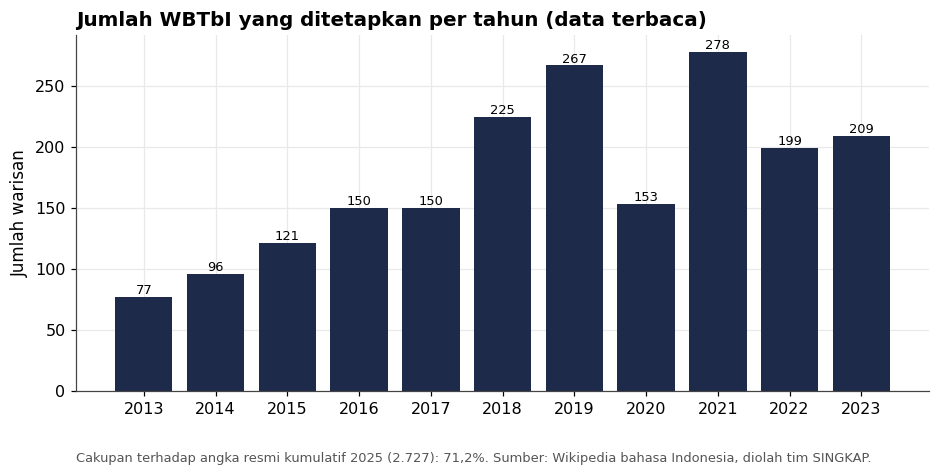

PosixPath('/content/SINGKAP_output/04_visualisasi/fig01_penetapan_per_tahun.png')

In [18]:
# 8.1 Penetapan per tahun dan validasi terhadap angka resmi
per_year = item.groupby('tahun').size()
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.bar(per_year.index.astype(str), per_year.values, color=PAL['tarum'])
for x, y in zip(per_year.index.astype(str), per_year.values):
    ax.text(x, y, fmt_num(y), ha='center', va='bottom', fontsize=8.5)
ax.set_title('Jumlah WBTbI yang ditetapkan per tahun (data terbaca)')
ax.set_ylabel('Jumlah warisan')
ax.text(0, -0.2, f"Cakupan terhadap angka resmi kumulatif 2025 (2.727): {fmt_pct(coverage)}. Sumber: Wikipedia bahasa Indonesia, diolah tim SINGKAP.",
        transform=ax.transAxes, fontsize=8.5, color='#555')
save_fig(fig, 'fig01_penetapan_per_tahun', 'Jumlah WBTbI per tahun penetapan dan cakupan data terhadap angka resmi')

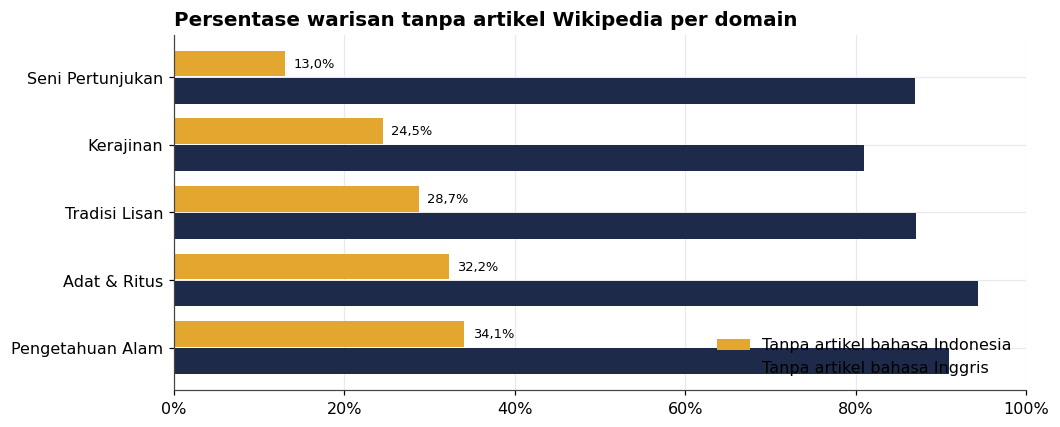

PosixPath('/content/SINGKAP_output/04_visualisasi/fig02_tanpa_artikel_per_domain.png')

In [19]:
# 8.2 Keberadaan artikel per domain
d = item.dropna(subset=['domain']).groupby('domain')[['ada_artikel_id', 'ada_artikel_en']].mean().sort_values('ada_artikel_id')
fig, ax = plt.subplots(figsize=(10, 4.2))
y = np.arange(len(d))
ax.barh(y + 0.2, 1 - d['ada_artikel_id'], height=0.38, color=PAL['kunyit'], label='Tanpa artikel bahasa Indonesia')
ax.barh(y - 0.2, 1 - d['ada_artikel_en'], height=0.38, color=PAL['tarum'], label='Tanpa artikel bahasa Inggris')
ax.set_yticks(y, [DOMAIN_SHORT[c] for c in d.index])
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: fmt_pct(v, 0)))
ax.set_xlim(0, 1)
for yi, v in zip(y, 1 - d['ada_artikel_id']):
    ax.text(v + 0.01, yi + 0.2, fmt_pct(v), va='center', fontsize=8.5)
ax.set_title('Persentase warisan tanpa artikel Wikipedia per domain')
ax.legend(loc='lower right')
save_fig(fig, 'fig02_tanpa_artikel_per_domain', 'Persentase WBTbI tanpa artikel Wikipedia per domain')

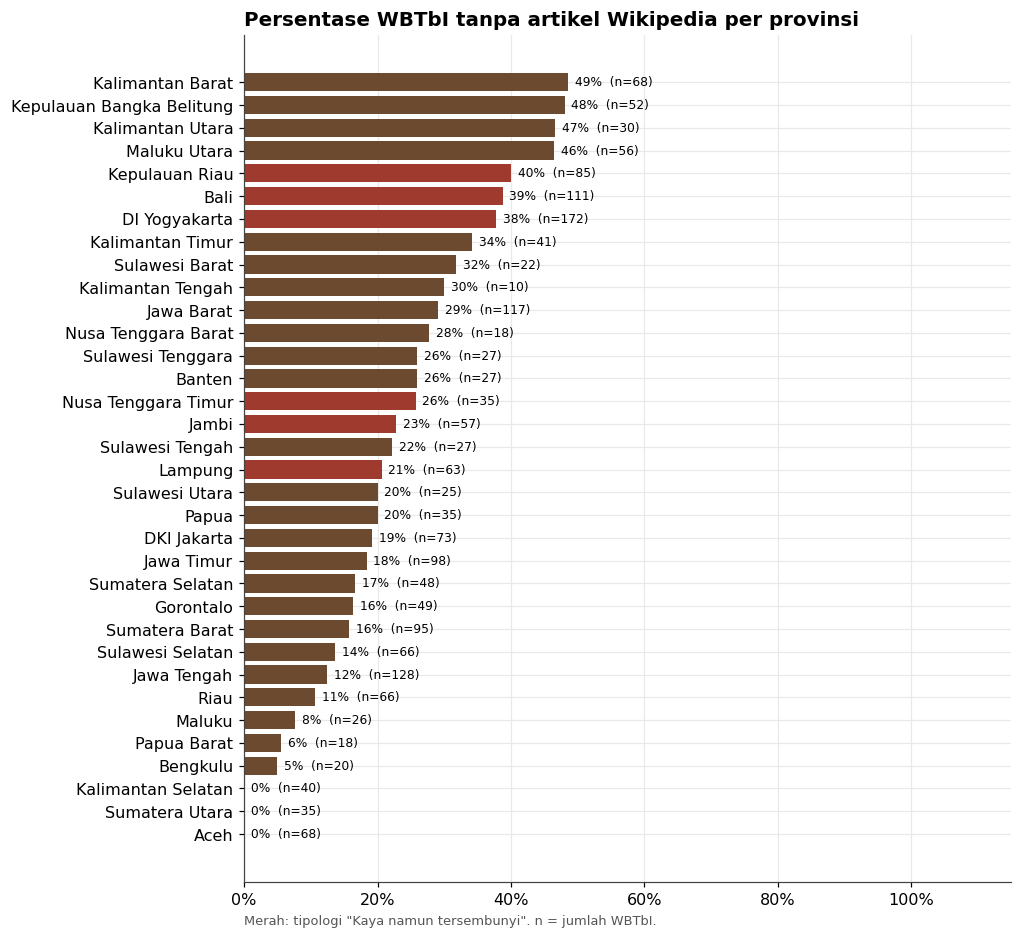

PosixPath('/content/SINGKAP_output/04_visualisasi/fig03_tanpa_artikel_per_provinsi.png')

In [20]:
# 8.3 Ketakterlihatan per provinsi
r = reg[reg['n_wbtbi'] > 0].sort_values('pct_tanpa_artikel')
fig, ax = plt.subplots(figsize=(9, 10))
colors = [PAL['mengkudu'] if t == 'Kaya namun tersembunyi' else PAL['soga'] for t in r['tipologi']]
ax.barh(r['provinsi'], r['pct_tanpa_artikel'], color=colors)
for yi, (v, n) in enumerate(zip(r['pct_tanpa_artikel'], r['n_wbtbi'])):
    ax.text(v + 0.01, yi, f'{fmt_pct(v, 0)}  (n={n})', va='center', fontsize=8)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: fmt_pct(v, 0)))
ax.set_xlim(0, 1.15)
ax.set_title('Persentase WBTbI tanpa artikel Wikipedia per provinsi')
ax.text(0, -0.05, 'Merah: tipologi "Kaya namun tersembunyi". n = jumlah WBTbI.', transform=ax.transAxes, fontsize=8.5, color='#555')
save_fig(fig, 'fig03_tanpa_artikel_per_provinsi', 'Persentase WBTbI tanpa artikel per provinsi dengan penanda tipologi')

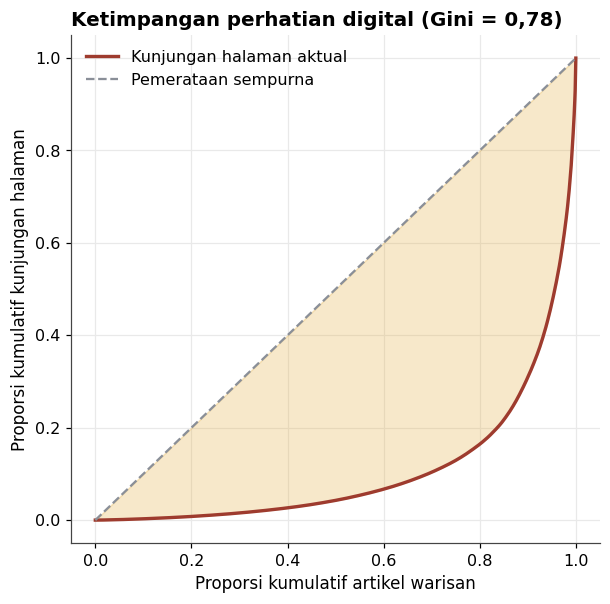

In [21]:
# 8.4 Kurva Lorenz perhatian digital
x = np.sort(with_art['pageviews_12b'].values)
if len(x) and x.sum() > 0:
    lor = np.insert(np.cumsum(x) / x.sum(), 0, 0)
    fig, ax = plt.subplots(figsize=(6.2, 6))
    ax.plot(np.linspace(0, 1, len(lor)), lor, color=PAL['mengkudu'], lw=2.2, label='Kunjungan halaman aktual')
    ax.plot([0, 1], [0, 1], color=PAL['abu'], ls='--', label='Pemerataan sempurna')
    ax.fill_between(np.linspace(0, 1, len(lor)), lor, np.linspace(0, 1, len(lor)), color=PAL['kunyit'], alpha=0.25)
    ax.set_title(f"Ketimpangan perhatian digital (Gini = {fmt_dec(T['gini_pageviews'])})")
    ax.set_xlabel('Proporsi kumulatif artikel warisan')
    ax.set_ylabel('Proporsi kumulatif kunjungan halaman')
    ax.legend(loc='upper left')
    save_fig(fig, 'fig04_lorenz_pageviews', 'Kurva Lorenz kunjungan halaman artikel WBTbI')

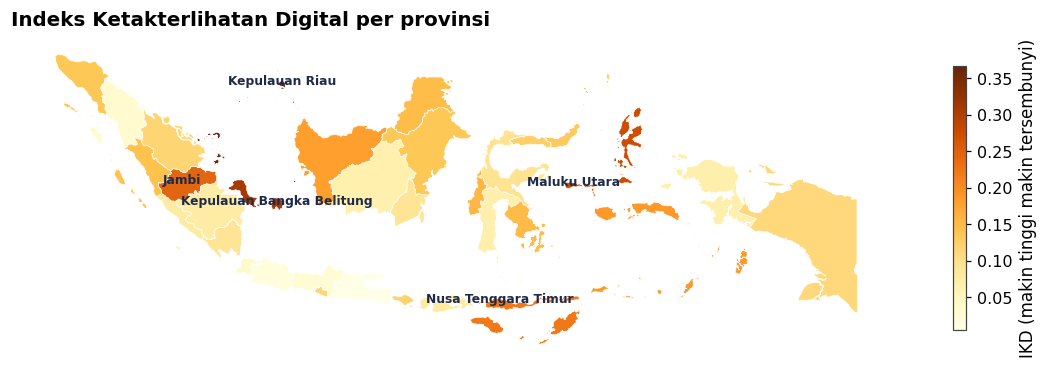

/usr/local/lib/python3.13/dist-packages/folium/raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


In [22]:
# 8.5 Peta IKD provinsi (statis dan interaktif)
if prov_gdf is not None:
    g = prov_gdf.merge(reg, on='provinsi', how='left')
    fig, ax = plt.subplots(figsize=(13, 5.2))
    g.plot(column='IKD', cmap='YlOrBr', linewidth=0.4, edgecolor='white', legend=True, ax=ax,
           legend_kwds={'label': 'IKD (makin tinggi makin tersembunyi)', 'shrink': 0.6},
           missing_kwds={'color': '#DDDDDD'})
    for _, row in g.nlargest(5, 'IKD').iterrows():
        pt = row.geometry.representative_point()
        ax.annotate(row['provinsi'], (pt.x, pt.y), fontsize=8, ha='center', color=PAL['tarum'], weight='bold')
    ax.set_axis_off()
    ax.set_title('Indeks Ketakterlihatan Digital per provinsi' + ('' if A_AVAILABLE else ' (tanpa dimensi arus wisata)'))
    save_fig(fig, 'fig05_peta_ikd_provinsi', 'Peta IKD per provinsi dengan lima provinsi tertinggi')

    import folium
    from matplotlib.colors import to_hex

    def ikd_color(v):
        return to_hex(plt.cm.YlOrBr(0.0 if v is None else float(v)))

    m = folium.Map(location=[-2.5, 118], zoom_start=5, tiles='CartoDB positron')
    gj = folium.GeoJson(
        json.loads(g[['provinsi', 'IKD', 'K', 'V', 'A', 'n_wbtbi', 'tipologi', 'geometry']].round(3).to_json()),
        style_function=lambda f: {'fillColor': ikd_color(f['properties']['IKD']), 'color': 'white',
                                  'weight': 0.6, 'fillOpacity': 0.85},
        tooltip=folium.GeoJsonTooltip(fields=['provinsi', 'IKD', 'K', 'V', 'A', 'n_wbtbi', 'tipologi'],
                                      aliases=['Provinsi', 'IKD', 'Kekayaan (K)', 'Visibilitas (V)', 'Arus (A)',
                                               'Jumlah WBTbI', 'Tipologi']))
    gj.add_to(m)
    m.save(str(D['html'] / 'peta_ikd_provinsi.html'))

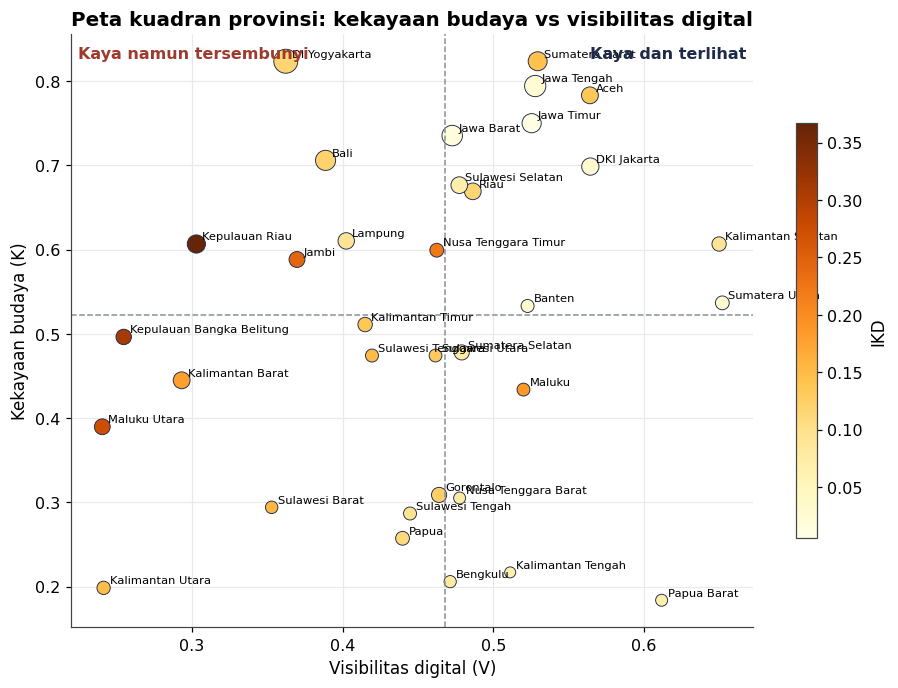

In [23]:
# 8.6 Kuadran kekayaan vs visibilitas
import plotly.express as px

fig, ax = plt.subplots(figsize=(10, 7))
sc = ax.scatter(reg['V'], reg['K'], s=40 + reg['n_wbtbi'] * 1.2, c=reg['IKD'], cmap='YlOrBr',
                edgecolor=PAL['tarum'], linewidth=0.6)
ax.axvline(med_V, color=PAL['abu'], ls='--', lw=1)
ax.axhline(med_K, color=PAL['abu'], ls='--', lw=1)
for _, rr in reg.iterrows():
    ax.annotate(rr['provinsi'], (rr['V'], rr['K']), fontsize=7.5, xytext=(4, 3), textcoords='offset points')
ax.text(0.01, 0.98, 'Kaya namun tersembunyi', transform=ax.transAxes, va='top', color=PAL['mengkudu'], weight='bold')
ax.text(0.99, 0.98, 'Kaya dan terlihat', transform=ax.transAxes, va='top', ha='right', color=PAL['tarum'], weight='bold')
ax.set_xlabel('Visibilitas digital (V)')
ax.set_ylabel('Kekayaan budaya (K)')
ax.set_title('Peta kuadran provinsi: kekayaan budaya vs visibilitas digital')
plt.colorbar(sc, ax=ax, label='IKD', shrink=0.7)
save_fig(fig, 'fig06_kuadran_k_vs_v', 'Kuadran provinsi berdasarkan kekayaan budaya dan visibilitas digital')

pfig = px.scatter(reg, x='V', y='K', size='n_wbtbi', color='IKD', hover_name='provinsi', color_continuous_scale='YlOrBr',
                  hover_data={'tipologi': True, 'A': ':.2f', 'IKD': ':.3f'},
                  labels={'V': 'Visibilitas digital (V)', 'K': 'Kekayaan budaya (K)'},
                  title='Kuadran provinsi: kekayaan budaya vs visibilitas digital')
pfig.add_vline(x=med_V, line_dash='dash', line_color='gray')
pfig.add_hline(y=med_K, line_dash='dash', line_color='gray')
pfig.update_layout(template='simple_white')
pfig.write_html(str(D['html'] / 'kuadran_provinsi.html'), include_plotlyjs='cdn')

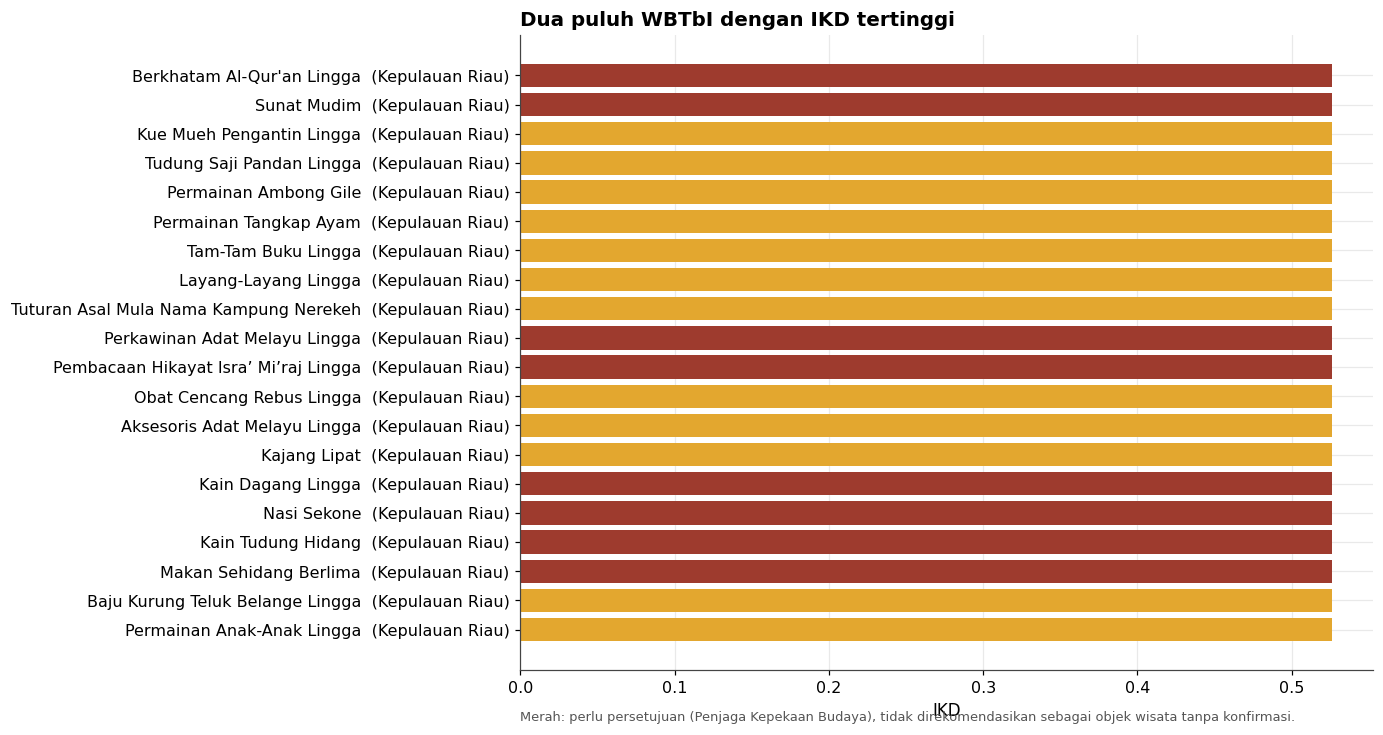

PosixPath('/content/SINGKAP_output/04_visualisasi/fig07_top20_tersembunyi.png')

In [24]:
# 8.7 Dua puluh warisan paling tersembunyi
t20 = top100.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 7.5))
cols = [PAL['mengkudu'] if k == 'perlu_persetujuan' else PAL['kunyit'] for k in t20['kepekaan']]
ax.barh([f"{n}  ({p})" for n, p in zip(t20['nama'], t20['provinsi'])], t20['IKD'], color=cols)
ax.set_title('Dua puluh WBTbI dengan IKD tertinggi')
ax.set_xlabel('IKD')
ax.text(0, -0.08, 'Merah: perlu persetujuan (Penjaga Kepekaan Budaya), tidak direkomendasikan sebagai objek wisata tanpa konfirmasi.',
        transform=ax.transAxes, fontsize=8.5, color='#555')
save_fig(fig, 'fig07_top20_tersembunyi', 'Dua puluh WBTbI dengan IKD tertinggi beserta status kepekaan')

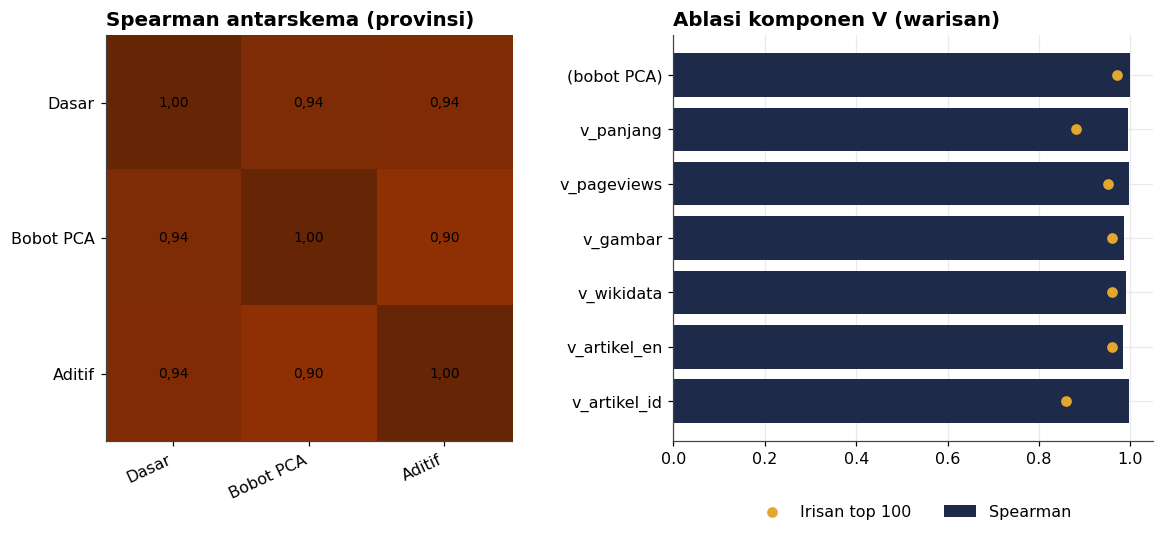

PosixPath('/content/SINGKAP_output/04_visualisasi/fig08_uji_ketahanan.png')

In [25]:
# 8.8 Uji ketahanan
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={'width_ratios': [1.1, 1]})
im = axes[0].imshow(rho_reg.values, cmap='YlOrBr', vmin=0, vmax=1)
axes[0].set_xticks(range(len(rho_reg)), [c.split(' (')[0] for c in rho_reg.columns], rotation=25, ha='right')
axes[0].set_yticks(range(len(rho_reg)), [c.split(' (')[0] for c in rho_reg.index])
for i in range(len(rho_reg)):
    for j in range(len(rho_reg)):
        axes[0].text(j, i, fmt_dec(rho_reg.values[i, j]), ha='center', va='center', fontsize=9)
axes[0].grid(False)
axes[0].set_title('Spearman antarskema (provinsi)')
axes[1].barh(ablation['komponen_dihapus'], ablation['spearman_vs_dasar'], color=PAL['tarum'], label='Spearman')
axes[1].scatter(ablation['irisan_top100'], ablation['komponen_dihapus'], color=PAL['kunyit'], zorder=3, label='Irisan top 100')
axes[1].set_xlim(0, 1.05)
axes[1].set_title('Ablasi komponen V (warisan)')
axes[1].legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2)
save_fig(fig, 'fig08_uji_ketahanan', 'Uji ketahanan IKD terhadap skema agregasi dan ablasi komponen')

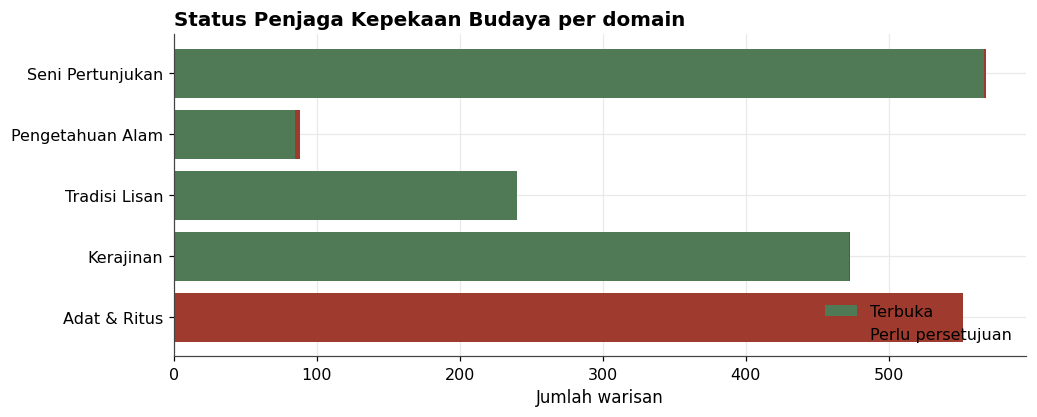

PosixPath('/content/SINGKAP_output/04_visualisasi/fig09_kepekaan_per_domain.png')

In [26]:
# 8.9 Kepekaan budaya per domain
kp = item.dropna(subset=['domain']).pivot_table(index='domain', columns='kepekaan', values='id', aggfunc='count', fill_value=0)
kp = kp.reindex(columns=['terbuka', 'perlu_persetujuan'], fill_value=0)
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.barh([DOMAIN_SHORT[c] for c in kp.index], kp['terbuka'], color=PAL['daun'], label='Terbuka')
ax.barh([DOMAIN_SHORT[c] for c in kp.index], kp['perlu_persetujuan'], left=kp['terbuka'], color=PAL['mengkudu'],
        label='Perlu persetujuan')
ax.set_title('Status Penjaga Kepekaan Budaya per domain')
ax.set_xlabel('Jumlah warisan')
ax.legend(loc='lower right')
save_fig(fig, 'fig09_kepekaan_per_domain', 'Jumlah warisan berstatus terbuka dan perlu persetujuan per domain')

## 9. Sistem rekomendasi berkeadilan
**Embedding.** Setiap warisan direpresentasikan oleh embedding teks multibahasa (`multilingual-e5-small`) dari nama, domain, provinsi, dan ringkasan artikel. Model yang sama dipakai untuk knowledge base RAG sehingga web cukup memuat satu model embedding.

**Penataan ulang.** `skor = λ × relevansi + (1 - λ) × IKD`, lalu daftar disusun serakah dengan penalti untuk warisan dari provinsi yang sama agar tidak terjadi penumpukan. Warisan berstatus *perlu persetujuan* dikeluarkan sebelum perankingan.

**Evaluasi.** Pada pengguna simulasi (kombinasi minat dan tujuan perjalanan), dihitung NDCG@10 relatif terhadap peringkat ideal berbasis relevansi (retensi relevansi), rata-rata IKD warisan yang direkomendasikan (keterungkapan), porsi eksposur lima provinsi paling terlihat, dan koefisien Gini eksposur antarprovinsi.

**Aturan pemilihan λ.** Retensi relevansi minimal `NDCG_MIN`, Gini eksposur tidak boleh naik (tidak menciptakan keramaian baru), lalu pilih konfigurasi dengan keterungkapan tertinggi. Bila tidak ada yang memenuhi, sistem jujur kembali ke relevansi murni.

In [27]:
def torch_cuda():
    try:
        import torch
        return torch.cuda.is_available()
    except Exception:
        return False


from sentence_transformers import SentenceTransformer
EMB = SentenceTransformer(EMBED_MODEL, device='cuda' if torch_cuda() else 'cpu')
EMB_DIM = EMB.get_sentence_embedding_dimension()


def embed(texts, kind='passage', bs=64):
    prefix = 'passage: ' if kind == 'passage' else 'query: '
    v = EMB.encode([prefix + t for t in texts], batch_size=bs, normalize_embeddings=True,
                   show_progress_bar=len(texts) > 300)
    return np.asarray(v, dtype='float32')


def wiki_extracts(titles, lang='id'):
    out = {}
    titles = sorted({t for t in titles if isinstance(t, str)})
    for batch in tqdm(list(chunked(titles, 20)), desc=f'Ringkasan artikel ({lang})'):
        pages, nm, rd = wiki_query({'titles': '|'.join(batch), 'prop': 'extracts', 'exintro': 1,
                                    'explaintext': 1, 'exlimit': 20, 'redirects': 1}, lang=lang, kind='wiki_extract')
        for t in batch:
            p = pages.get(resolve_title(t, nm, rd), {})
            if p.get('extract'):
                out[t] = re.sub(r'\s+', ' ', p['extract']).strip()
    return out


EXTRACTS = wiki_extracts(item['judul_artikel'].dropna().unique())
item['ringkasan'] = item['judul_artikel'].map(EXTRACTS).fillna('')
item['teks_embedding'] = [
    f"{n}. Warisan budaya takbenda dari {p}. Domain {dl}. {r[:500]}"
    for n, p, dl, r in zip(item['nama'], item['provinsi'], item['domain_label'], item['ringkasan'])]
ITEM_EMB = embed(item['teks_embedding'].tolist())
np.save(D['rec'] / 'item_embeddings.npy', ITEM_EMB.astype('float16'))
(D['rec'] / 'item_ids.json').write_text(json.dumps(item['id'].tolist()), encoding='utf-8')
log(f'Embedding warisan: {ITEM_EMB.shape} | ringkasan tersedia untuk {fmt_num((item["ringkasan"] != "").sum())} warisan')

modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/498k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/655 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

model.safetensors: downloading bytes:           |  0.00B            

... (7 outputs left out)

config.json:   0%|          | 0.00/200 [00:00<?, ?B/s]

Ringkasan artikel (id):   0%|          | 0/72 [00:00<?, ?it/s]

Batches:   0%|          | 0/31 [00:00<?, ?it/s]

Embedding warisan: (1925, 384) | ringkasan tersedia untuk 1.450 warisan


In [28]:
INTERESTS = ['tari tradisional', 'musik dan alat musik tradisional', 'kuliner khas daerah', 'kue dan jajanan tradisional',
             'minuman tradisional', 'kain tenun dan songket', 'batik dan motif kain', 'kerajinan anyaman',
             'ukiran kayu', 'permainan rakyat anak', 'cerita rakyat dan legenda', 'pantun syair dan sastra lisan',
             'arsitektur rumah adat', 'bela diri tradisional pencak silat', 'teater rakyat', 'wayang dan seni boneka',
             'pengetahuan bertani tradisional', 'perahu dan budaya maritim', 'pakaian adat', 'lagu daerah',
             'senjata tradisional', 'bahasa dan aksara daerah', 'kearifan lokal menjaga alam', 'seni ukir logam dan perhiasan']
Q_EMB = embed(INTERESTS, kind='query')

cand = item[(item['kepekaan'] == 'terbuka') & item['provinsi'].isin(PROV34) & item['IKD'].notna()].copy()
cand_pos = cand.index.to_numpy()
E = ITEM_EMB[cand_pos]
prov_idx = {p: i for i, p in enumerate(PROV34)}
cand_p = cand['provinsi'].map(prov_idx).to_numpy()
ikd_n = pct_rank(cand['IKD'], zero_is_zero=False).to_numpy()

lat = np.radians([CENTROID[p][0] for p in PROV34])
lon = np.radians([CENTROID[p][1] for p in PROV34])
dlat, dlon = lat[:, None] - lat[None, :], lon[:, None] - lon[None, :]
DIST = 2 * 6371 * np.arcsin(np.sqrt(np.sin(dlat / 2) ** 2 + np.cos(lat[:, None]) * np.cos(lat[None, :]) * np.sin(dlon / 2) ** 2))
DIST_SCALE_KM = 800.0

rng = np.random.default_rng(SEED)
N_USERS = 80 if FAST_MODE else 400
users = [(int(rng.integers(len(INTERESTS))), int(rng.integers(len(PROV34)))) for _ in range(N_USERS)]
TOPK = 10
LAMBDAS = np.round(np.linspace(1.0, 0.0, 21), 2) + 0.0
visible_top5 = set(reg.nlargest(5, 'V')['provinsi'])


def relevance(qi, dest):
    sim = E @ Q_EMB[qi]
    sim = (sim - sim.min()) / (sim.max() - sim.min() + 1e-9)
    prox = np.exp(-DIST[dest, cand_p] / DIST_SCALE_KM)
    return sim * (0.5 + 0.5 * prox)


def dcg(g):
    return float((g / np.log2(np.arange(2, len(g) + 2))).sum())


DIVERSITY_PENALTY = 0.12   # penalti untuk setiap warisan lain dari provinsi yang sama dalam satu daftar
POOL = 150


def rerank(rel, lam, penalty):
    base = lam * rel + (1 - lam) * ikd_n
    pool = np.argpartition(-base, POOL)[:POOL]
    sc, pp = base[pool].copy(), cand_p[pool]
    counts, chosen = np.zeros(len(PROV34)), []
    for _ in range(TOPK):
        j = int(np.argmax(sc - penalty * counts[pp]))
        chosen.append(pool[j])
        counts[pp[j]] += 1
        sc[j] = -np.inf
    return np.array(chosen)


def evaluate(lam, penalty, label):
    expo = np.zeros(len(PROV34))
    ndcgs, ikds = [], []
    for rel in REL:
        top = rerank(rel, lam, penalty)
        ndcgs.append(dcg(rel[top]) / dcg(np.sort(rel)[::-1][:TOPK]))
        ikds.append(cand['IKD'].to_numpy()[top].mean())
        np.add.at(expo, cand_p[top], 1 / np.log2(np.arange(2, TOPK + 2)))
    return {'metode': label, 'lambda': lam, 'penalti_provinsi': penalty, 'ndcg10': float(np.mean(ndcgs)),
            'gini_eksposur': gini(expo), 'provinsi_terjangkau': int((expo > 0).sum()),
            'rata2_ikd_rekomendasi': float(np.mean(ikds)),
            'porsi_eksposur_5_prov_paling_terlihat': float(expo[[prov_idx[p] for p in visible_top5]].sum() / expo.sum())}


REL = [relevance(qi, dest) for qi, dest in users]
base = evaluate(1.0, 0.0, 'Relevansi murni')
rows = [base] + [evaluate(float(l), DIVERSITY_PENALTY, 'SINGKAP') for l in LAMBDAS]
rec_eval = pd.DataFrame(rows)
singkap = rec_eval[rec_eval['metode'] == 'SINGKAP']
# Aturan pemilihan: retensi relevansi >= NDCG_MIN dan tidak menciptakan konsentrasi baru (Gini tidak naik),
# lalu pilih yang paling banyak menyingkap warisan tersembunyi (rata-rata IKD rekomendasi tertinggi).
ok = singkap[(singkap['ndcg10'] >= NDCG_MIN) & (singkap['gini_eksposur'] <= base['gini_eksposur'] + 0.01)]
best = ok.loc[ok['rata2_ikd_rekomendasi'].idxmax()] if len(ok) else pd.Series(base)
LAMBDA_STAR = float(best['lambda'])
PENALTY_STAR = float(best['penalti_provinsi'])
REC_SUMMARY = {
    'lambda_terpilih': LAMBDA_STAR, 'penalti_provinsi': PENALTY_STAR, 'ndcg_min': NDCG_MIN,
    'aturan_pemilihan': 'NDCG@10 >= NDCG_MIN, Gini tidak naik lebih dari 0,01, rata-rata IKD rekomendasi maksimum',
    'gini_dasar': float(base['gini_eksposur']), 'gini_terpilih': float(best['gini_eksposur']),
    'ndcg_terpilih': float(best['ndcg10']),
    'ikd_rekomendasi_dasar': float(base['rata2_ikd_rekomendasi']), 'ikd_rekomendasi_terpilih': float(best['rata2_ikd_rekomendasi']),
    'provinsi_terjangkau_dasar': int(base['provinsi_terjangkau']), 'provinsi_terjangkau_terpilih': int(best['provinsi_terjangkau']),
    'porsi_5_terlihat_dasar': float(base['porsi_eksposur_5_prov_paling_terlihat']),
    'porsi_5_terlihat_terpilih': float(best['porsi_eksposur_5_prov_paling_terlihat']),
    'ada_konfigurasi_memenuhi_syarat': bool(len(ok)),
}
rec_eval.to_csv(D['rec'] / 'evaluasi_tradeoff.csv', index=False)
display(rec_eval.round(3))
print(json.dumps(REC_SUMMARY, indent=1))

R = REC_SUMMARY
if R['ada_konfigurasi_memenuhi_syarat']:
    gini_txt = ('menurunkan' if R['gini_terpilih'] < R['gini_dasar'] - 0.005 else 'menjaga') + \
               f" Gini eksposur antarprovinsi ({fmt_dec(R['gini_dasar'])} menjadi {fmt_dec(R['gini_terpilih'])})"
    REC_TEXT = (f"Pada simulasi {N_USERS} pengguna, konfigurasi λ = {fmt_dec(LAMBDA_STAR)} dengan penalti keberagaman provinsi "
                f"menaikkan rata-rata IKD warisan yang direkomendasikan dari {fmt_dec(R['ikd_rekomendasi_dasar'], 3)} menjadi "
                f"{fmt_dec(R['ikd_rekomendasi_terpilih'], 3)}, mengubah porsi eksposur lima provinsi paling terlihat dari "
                f"{fmt_pct(R['porsi_5_terlihat_dasar'])} menjadi {fmt_pct(R['porsi_5_terlihat_terpilih'])}, dan {gini_txt}, "
                f"dengan retensi relevansi NDCG@10 sebesar {fmt_dec(R['ndcg_terpilih'])}.")
else:
    REC_TEXT = (f"Pada simulasi {N_USERS} pengguna, belum ada konfigurasi yang memenuhi syarat retensi relevansi dan larangan "
                f"konsentrasi baru, sehingga rekomendasi memakai relevansi murni. Parameter perlu disetel ulang.")
add_insight('rekomendasi_berkeadilan', 'Menyingkap warisan tersembunyi tanpa menciptakan keramaian baru', REC_TEXT)

,metode,lambda,penalti_provinsi,ndcg10,gini_eksposur,provinsi_terjangkau,rata2_ikd_rekomendasi,porsi_eksposur_5_prov_paling_terlihat
0,Relevansi murni,1.00,0.00,1.000,0.255,34,0.129,0.150
1,SINGKAP,1.00,0.12,0.963,0.234,34,0.111,0.144
2,SINGKAP,0.95,0.12,0.961,0.226,34,0.129,0.134
3,SINGKAP,0.90,0.12,0.953,0.243,34,0.153,0.122
4,SINGKAP,0.85,0.12,0.939,0.281,34,0.177,0.109
5,SINGKAP,0.80,0.12,0.923,0.336,34,0.200,0.099
6,SINGKAP,0.75,0.12,0.902,0.394,34,0.221,0.085
7,SINGKAP,0.70,0.12,0.875,0.455,34,0.243,0.073
8,SINGKAP,0.65,0.12,0.848,0.507,34,0.262,0.063
9,SINGKAP,0.60,0.12,0.821,0.557,34,0.280,0.056


{
 "lambda_terpilih": 0.9,
 "penalti_provinsi": 0.12,
 "ndcg_min": 0.9,
 "aturan_pemilihan": "NDCG@10 >= NDCG_MIN, Gini tidak naik lebih dari 0,01, rata-rata IKD rekomendasi maksimum",
 "gini_dasar": 0.2552369360488374,
 "gini_terpilih": 0.2430608369955442,
 "ndcg_terpilih": 0.9526050087214918,
 "ikd_rekomendasi_dasar": 0.12907690029914037,
 "ikd_rekomendasi_terpilih": 0.15305172496287953,
 "provinsi_terjangkau_dasar": 34,
 "provinsi_terjangkau_terpilih": 34,
 "porsi_5_terlihat_dasar": 0.14998538483419174,
 "porsi_5_terlihat_terpilih": 0.12218844641674032,
 "ada_konfigurasi_memenuhi_syarat": true
}


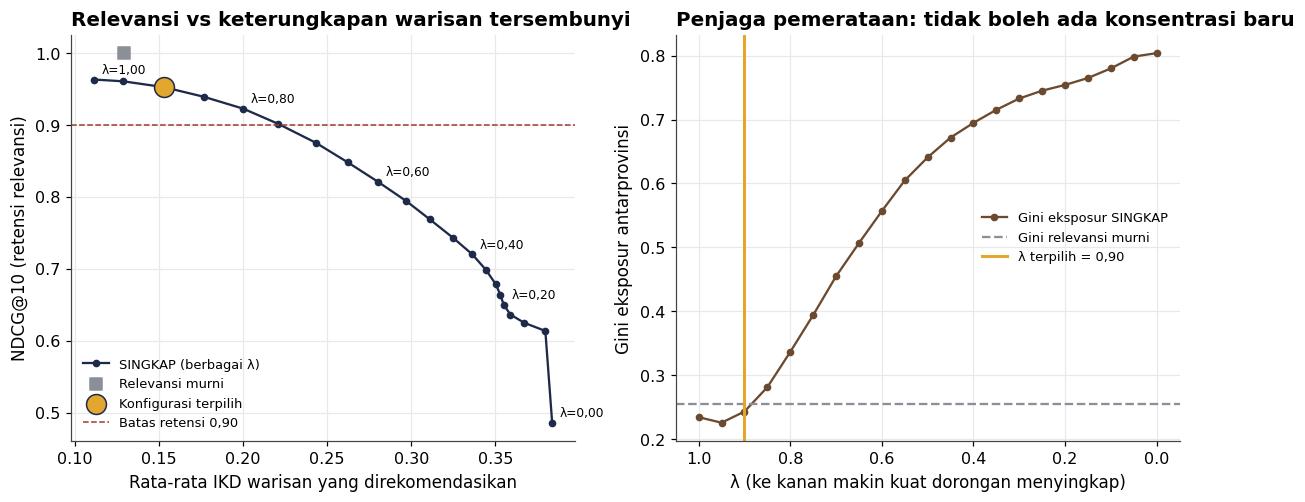

Relevansi murni                     \
                              nama provinsi       IKD   
0  Tari Baris Cina Renon dan Sanur     Bali  0.094885   
1                   Tari Sanghyang     Bali  0.009734   
2                      Tari Rejang     Bali  0.013063   
3      Tari Baris Wayang Lumintang     Bali  0.109818   
4                 Tari Taruna Jaya     Bali  0.052450   

                SINGKAP (λ = 0,90)                                 
                              nama             provinsi       IKD  
0  Tari Baris Cina Renon dan Sanur                 Bali  0.094885  
1                    Tari Beskalan           Jawa Timur  0.006328  
2                   Tari Sanghyang                 Bali  0.009734  
3                            Oglek        DI Yogyakarta  0.121209  
4                      Tari Pado'a  Nusa Tenggara Timur  0.204015

1965

In [29]:
sk = rec_eval[rec_eval['metode'] == 'SINGKAP']
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].plot(sk['rata2_ikd_rekomendasi'], sk['ndcg10'], '-o', color=PAL['tarum'], ms=4, label='SINGKAP (berbagai λ)')
for _, rr in sk.iloc[::4].iterrows():
    axes[0].annotate(f"λ={fmt_dec(rr['lambda'])}", (rr['rata2_ikd_rekomendasi'], rr['ndcg10']), fontsize=8,
                     xytext=(5, 4), textcoords='offset points')
axes[0].scatter([base['rata2_ikd_rekomendasi']], [base['ndcg10']], marker='s', s=70, color=PAL['abu'], label='Relevansi murni')
axes[0].scatter([best['rata2_ikd_rekomendasi']], [best['ndcg10']], s=170, color=PAL['kunyit'], edgecolor=PAL['tarum'],
                zorder=3, label='Konfigurasi terpilih')
axes[0].axhline(NDCG_MIN, color=PAL['mengkudu'], ls='--', lw=1, label=f'Batas retensi {fmt_dec(NDCG_MIN)}')
axes[0].set_xlabel('Rata-rata IKD warisan yang direkomendasikan')
axes[0].set_ylabel('NDCG@10 (retensi relevansi)')
axes[0].set_title('Relevansi vs keterungkapan warisan tersembunyi')
axes[0].legend(loc='lower left', fontsize=8.5)
axes[1].plot(sk['lambda'], sk['gini_eksposur'], '-o', color=PAL['soga'], ms=4, label='Gini eksposur SINGKAP')
axes[1].axhline(base['gini_eksposur'], color=PAL['abu'], ls='--', label='Gini relevansi murni')
axes[1].axvline(LAMBDA_STAR, color=PAL['kunyit'], lw=2, label=f'λ terpilih = {fmt_dec(LAMBDA_STAR)}')
axes[1].invert_xaxis()
axes[1].set_xlabel('λ (ke kanan makin kuat dorongan menyingkap)')
axes[1].set_ylabel('Gini eksposur antarprovinsi')
axes[1].set_title('Penjaga pemerataan: tidak boleh ada konsentrasi baru')
axes[1].legend(fontsize=8.5)
save_fig(fig, 'fig10_tradeoff_relevansi_pemerataan', 'Kompromi relevansi, keterungkapan warisan tersembunyi, dan pemerataan eksposur')

pfig = px.line(sk, x='rata2_ikd_rekomendasi', y='ndcg10', markers=True,
               hover_data=['lambda', 'gini_eksposur', 'provinsi_terjangkau', 'porsi_eksposur_5_prov_paling_terlihat'],
               labels={'rata2_ikd_rekomendasi': 'Rata-rata IKD rekomendasi', 'ndcg10': 'NDCG@10'},
               title='Relevansi vs keterungkapan warisan tersembunyi')
pfig.update_layout(template='simple_white')
pfig.write_html(str(D['html'] / 'tradeoff_rekomendasi.html'), include_plotlyjs='cdn')

# Contoh "Alih Jejak": minat tari tradisional dengan tujuan Bali
qi, dest = INTERESTS.index('tari tradisional'), prov_idx['Bali']
rel = relevance(qi, dest)
def top_items(lam, penalty, k=5):
    t = rerank(rel, lam, penalty)[:k]
    return cand.iloc[t][['nama', 'provinsi', 'IKD']].reset_index(drop=True)
contoh = pd.concat({'Relevansi murni': top_items(1.0, 0.0),
                    f'SINGKAP (λ = {fmt_dec(LAMBDA_STAR)})': top_items(LAMBDA_STAR, PENALTY_STAR)}, axis=1)
contoh.to_csv(D['rec'] / 'contoh_alih_jejak_bali_tari.csv')
display(contoh)

REC_CONFIG = {
    'versi': 1, 'lambda': LAMBDA_STAR, 'top_k': TOPK, 'skala_jarak_km': DIST_SCALE_KM,
    'rumus_relevansi': 'sim_minmax * (0.5 + 0.5 * exp(-jarak_km / skala_jarak_km))',
    'rumus_skor': 'lambda * relevansi + (1 - lambda) * ikd_persentil',
    'penalti_provinsi': PENALTY_STAR, 'kolam_kandidat': POOL,
    'algoritma': 'ambil POOL kandidat skor tertinggi, lalu pilih serakah TOP_K dengan skor dikurangi penalti_provinsi x jumlah warisan provinsi yang sama yang sudah terpilih',
    'filter_kandidat': "kepekaan == 'terbuka' dan provinsi terpetakan",
    'embedding_model': EMBED_MODEL, 'prefix_query': 'query: ', 'prefix_passage': 'passage: ',
    'minat_contoh': INTERESTS, 'ringkasan_evaluasi': REC_SUMMARY,
}
(D['rec'] / 'recsys_config.json').write_text(json.dumps(REC_CONFIG, ensure_ascii=False, indent=1), encoding='utf-8')

## 10. Model Kenali Rumah Adat
Data latih diambil dari Wikimedia Commons melalui API: kategori yang relevan dicari otomatis, lalu hanya berkas berlisensi terbuka (CC0, CC BY, CC BY-SA, domain publik) yang dipakai. Gambar duplikat lintas kelas dibuang untuk mencegah label ganda. Atribusi setiap gambar disimpan. Model dilatih dengan transfer learning, dievaluasi pada data uji terpisah, lalu diekspor ke ONNX agar dapat berjalan di peramban.

In [30]:
RUMAH_ADAT = [
    {'kelas': 'Rumah Gadang', 'provinsi': 'Sumatera Barat', 'kata_kunci': ['Rumah Gadang', 'Rumah gadang']},
    {'kelas': 'Tongkonan', 'provinsi': 'Sulawesi Selatan', 'kata_kunci': ['Tongkonan']},
    {'kelas': 'Joglo', 'provinsi': 'Jawa Tengah', 'kata_kunci': ['Joglo']},
    {'kelas': 'Honai', 'provinsi': 'Papua', 'kata_kunci': ['Honai']},
    {'kelas': 'Rumah Bolon', 'provinsi': 'Sumatera Utara', 'kata_kunci': ['Rumah Bolon', 'Batak Toba houses', 'Batak house']},
    {'kelas': 'Lamin', 'provinsi': 'Kalimantan Timur', 'kata_kunci': ['Lamin', 'Rumah Lamin']},
    {'kelas': 'Rumah Betang', 'provinsi': 'Kalimantan Barat', 'kata_kunci': ['Rumah Betang', 'Betang', 'Dayak longhouse']},
    {'kelas': 'Rumoh Aceh', 'provinsi': 'Aceh', 'kata_kunci': ['Rumoh Aceh', 'Rumah Aceh']},
    {'kelas': 'Rumah Limas', 'provinsi': 'Sumatera Selatan', 'kata_kunci': ['Rumah Limas']},
    {'kelas': 'Mbaru Niang', 'provinsi': 'Nusa Tenggara Timur', 'kata_kunci': ['Mbaru Niang', 'Wae Rebo']},
    {'kelas': 'Rumah Adat Sasak', 'provinsi': 'Nusa Tenggara Barat', 'kata_kunci': ['Sasak houses', 'Sade village', 'Rumah adat Sasak']},
    {'kelas': 'Omo Hada Nias', 'provinsi': 'Sumatera Utara', 'kata_kunci': ['Omo Sebua', 'Omo Hada', 'Nias traditional houses']},
]
CV_MAX = 40 if FAST_MODE else 180
CV_MIN = 25 if FAST_MODE else 45
COMMONS = 'https://commons.wikimedia.org/w/api.php'
IMG_DIR = CACHE / 'cv_images'


def commons(params, kind):
    return http_get_json(COMMONS, {'format': 'json', 'formatversion': 2, **params}, kind=kind, pause=0.02)


def find_categories(kw, n=6):
    js = commons({'action': 'query', 'list': 'search', 'srsearch': kw, 'srnamespace': 14, 'srlimit': n}, 'commons_cat')
    key = norm_txt(kw).split()[0]
    return [h['title'] for h in js.get('query', {}).get('search', []) if key in norm_txt(h['title'])]


def category_files(cat, depth=1, cap=400, seen=None):
    seen = seen if seen is not None else set()
    if cat in seen:
        return []
    seen.add(cat)
    files, subcats, cont = [], [], {}
    while len(files) < cap:
        js = commons({'action': 'query', 'list': 'categorymembers', 'cmtitle': cat, 'cmtype': 'file|subcat',
                      'cmlimit': 500, **cont}, 'commons_members')
        for mbr in js.get('query', {}).get('categorymembers', []):
            (subcats if mbr['ns'] == 14 else files).append(mbr['title'])
        if 'continue' not in js:
            break
        cont = js['continue']
    if depth > 0:
        for sc in subcats[:15]:
            files += category_files(sc, depth - 1, cap - len(files), seen)
            if len(files) >= cap:
                break
    return files[:cap]


def search_files(kw, n=150):
    js = commons({'action': 'query', 'list': 'search', 'srsearch': f'"{kw}" filetype:bitmap', 'srnamespace': 6,
                  'srlimit': min(n, 500)}, 'commons_filesearch')
    return [h['title'] for h in js.get('query', {}).get('search', [])]


FREE_RE = re.compile(r'(cc0|cc[ -]by|public domain|^pd\b|pd-)', re.I)


def image_infos(titles):
    out = []
    for batch in chunked(titles, 50):
        js = commons({'action': 'query', 'titles': '|'.join(batch), 'prop': 'imageinfo',
                      'iiprop': 'url|size|mime|sha1|extmetadata', 'iiurlwidth': 320,
                      'iiextmetadatafilter': 'LicenseShortName|Artist|LicenseUrl'}, 'commons_info')
        for p in js.get('query', {}).get('pages', []):
            ii = (p.get('imageinfo') or [{}])[0]
            meta = ii.get('extmetadata', {})
            lic = meta.get('LicenseShortName', {}).get('value', '')
            if ii.get('mime') not in ('image/jpeg', 'image/png') or ii.get('width', 0) < 300:
                continue
            if not FREE_RE.search(lic) or re.search(r'\b(nc|nd)\b', lic, re.I):
                continue
            out.append({'judul_berkas': p['title'], 'thumb': ii.get('thumburl'), 'sha1': ii.get('sha1'),
                        'lisensi': lic, 'url_lisensi': meta.get('LicenseUrl', {}).get('value', ''),
                        'pembuat': re.sub(r'<[^>]+>', '', meta.get('Artist', {}).get('value', '')).strip(),
                        'halaman': ii.get('descriptionurl')})
    return out


cv_rows = []
if RUN_CV:
    for spec in RUMAH_ADAT:
        titles = []
        for kw in spec['kata_kunci']:
            for cat in find_categories(kw):
                titles += category_files(cat, depth=1, cap=CV_MAX * 3)
        if len(set(titles)) < CV_MAX:
            for kw in spec['kata_kunci']:
                titles += search_files(kw, n=CV_MAX * 2)
        titles = list(dict.fromkeys(titles))
        infos = image_infos(titles)[:CV_MAX * 2]
        for inf in infos:
            cv_rows.append({**inf, 'kelas': spec['kelas'], 'provinsi': spec['provinsi']})
        print(f"{spec['kelas']:<18} kandidat berkas: {len(titles):>4} | berlisensi terbuka: {len(infos):>4}")

cv_meta = pd.DataFrame(cv_rows)
if len(cv_meta):
    dup = cv_meta.groupby('sha1')['kelas'].nunique()
    cv_meta = cv_meta[~cv_meta['sha1'].isin(dup[dup > 1].index)].drop_duplicates('sha1')
    cv_meta = cv_meta.groupby('kelas').head(CV_MAX).reset_index(drop=True)

Rumah Gadang       kandidat berkas:  385 | berlisensi terbuka:  359
Tongkonan          kandidat berkas:  233 | berlisensi terbuka:  156
Joglo              kandidat berkas:  180 | berlisensi terbuka:  173
Honai              kandidat berkas:   57 | berlisensi terbuka:   52
Rumah Bolon        kandidat berkas:  228 | berlisensi terbuka:  223
Lamin              kandidat berkas:  209 | berlisensi terbuka:  208
Rumah Betang       kandidat berkas:  264 | berlisensi terbuka:  256
Rumoh Aceh         kandidat berkas:  103 | berlisensi terbuka:   87
Rumah Limas        kandidat berkas:   56 | berlisensi terbuka:   56
Mbaru Niang        kandidat berkas:   71 | berlisensi terbuka:   71
Rumah Adat Sasak   kandidat berkas:   34 | berlisensi terbuka:   34
Omo Hada Nias      kandidat berkas:    9 | berlisensi terbuka:    8


Unduh gambar:   0%|          | 0/1352 [00:00<?, ?it/s]

PERINGATAN: Kelas dengan gambar terlalu sedikit dikeluarkan: {'Rumah Adat Sasak': 34, 'Omo Hada Nias': 8}


,jumlah_gambar
kelas,
Rumah Gadang,180
Lamin,180
Rumah Betang,180
Rumah Bolon,180
Joglo,173
Tongkonan,156
Rumoh Aceh,87
Mbaru Niang,71
Honai,52


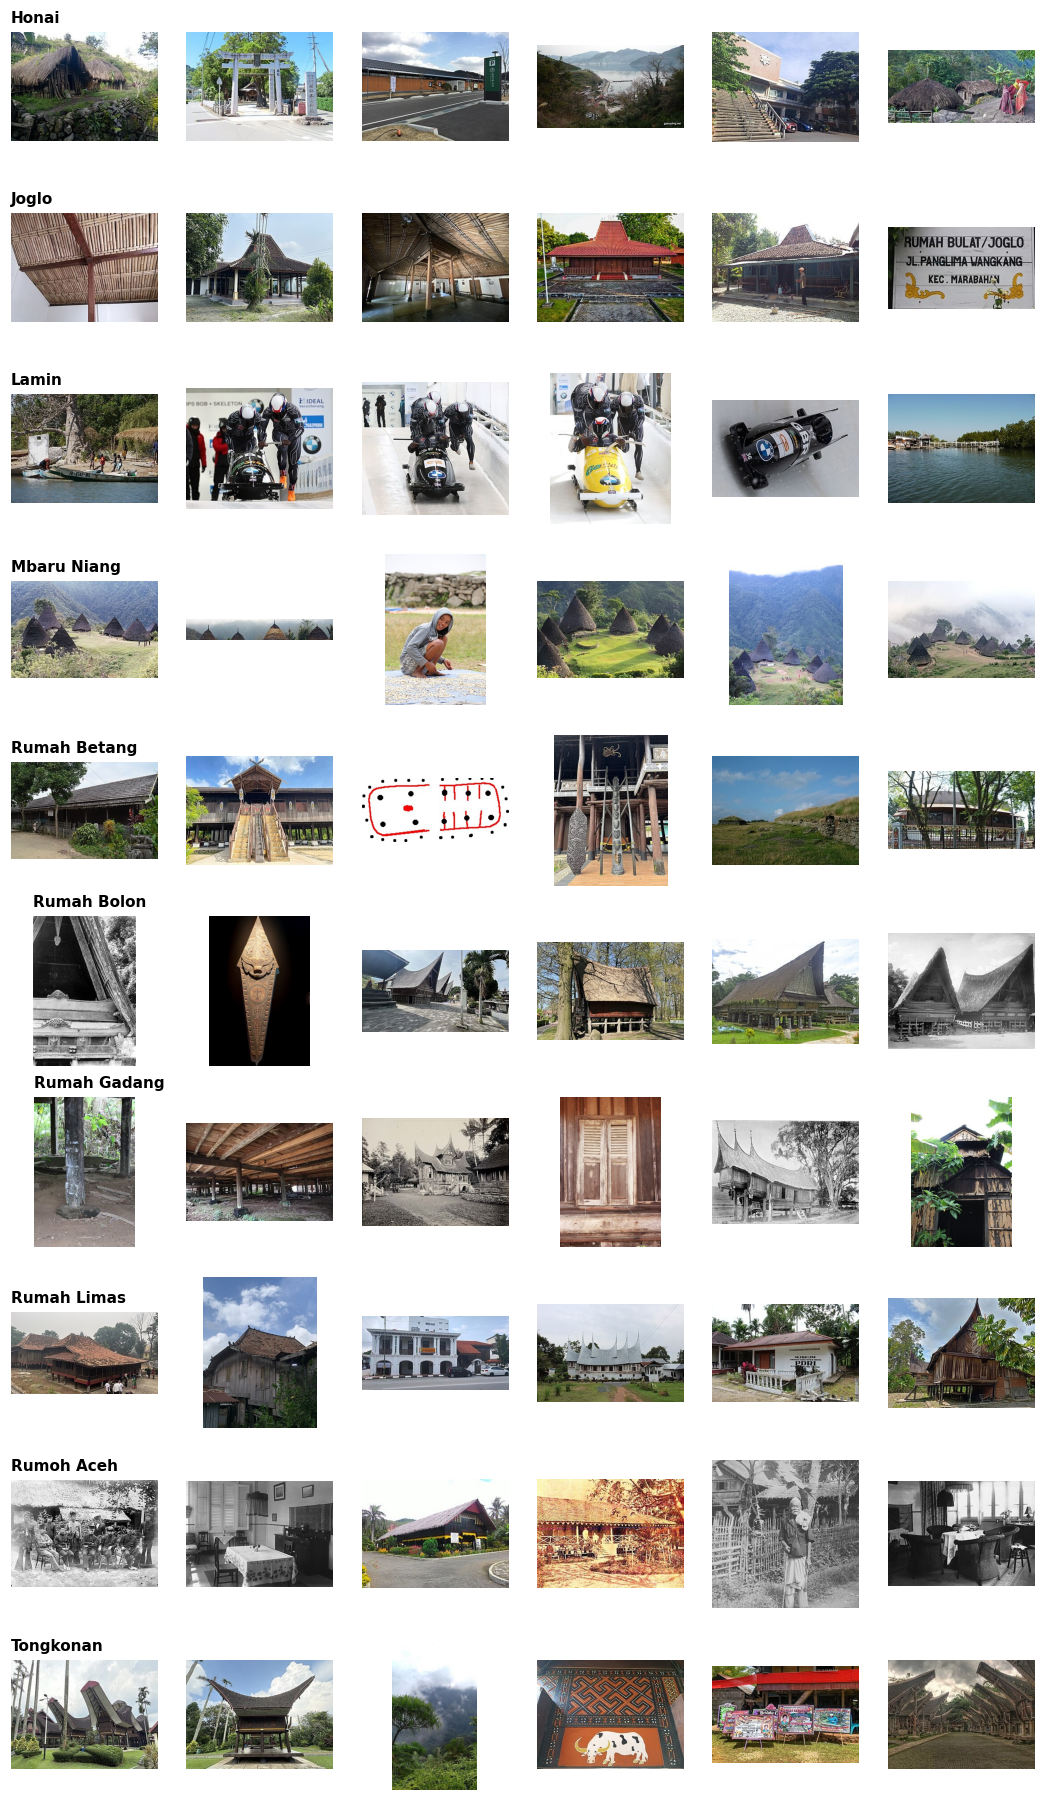

Periksa grid di atas. Judul berkas yang tidak relevan dapat ditulis ke /content/singkap_input/cv_exclude.txt


In [31]:
def download_image(row):
    folder = IMG_DIR / row['kelas'].replace(' ', '_')
    folder.mkdir(parents=True, exist_ok=True)
    path = folder / f"{row['sha1']}.jpg"
    if not path.exists():
        try:
            from PIL import Image
            img = Image.open(io.BytesIO(http_get_bytes(row['thumb']))).convert('RGB')
            img.save(path, quality=90)
        except Exception:
            return None
    return str(path)


if RUN_CV and len(cv_meta):
    with ThreadPoolExecutor(max_workers=8) as ex:
        cv_meta['path'] = list(tqdm(ex.map(download_image, cv_meta.to_dict('records')), total=len(cv_meta),
                                    desc='Unduh gambar'))
    cv_meta = cv_meta.dropna(subset=['path'])
    counts = cv_meta['kelas'].value_counts()
    keep = counts[counts >= CV_MIN].index
    dropped = counts[counts < CV_MIN]
    if len(dropped):
        warn(f'Kelas dengan gambar terlalu sedikit dikeluarkan: {dropped.to_dict()}')
    cv_meta = cv_meta[cv_meta['kelas'].isin(keep)].reset_index(drop=True)
    exclude = INPUT / 'cv_exclude.txt'
    if exclude.exists():
        bad = {l.strip() for l in exclude.read_text().splitlines() if l.strip()}
        cv_meta = cv_meta[~cv_meta['judul_berkas'].isin(bad)]
        log(f'Gambar dikecualikan secara manual: {len(bad)}')
    cv_meta.drop(columns=['path']).to_csv(D['cv'] / 'atribusi_gambar.csv', index=False)
    register_source('Wikimedia Commons (foto rumah adat)', COMMONS, 'Per berkas (lihat atribusi_gambar.csv)',
                    'hanya CC0, CC BY, CC BY-SA, domain publik', len(cv_meta))
    display(cv_meta['kelas'].value_counts().rename('jumlah_gambar').to_frame())

    from PIL import Image
    classes = sorted(cv_meta['kelas'].unique())
    fig, axes = plt.subplots(len(classes), 6, figsize=(12, 2.1 * len(classes)))
    for r_i, c in enumerate(classes):
        sub = cv_meta[cv_meta['kelas'] == c].sample(n=min(6, (cv_meta['kelas'] == c).sum()), random_state=SEED)
        for c_i in range(6):
            ax = axes[r_i, c_i] if len(classes) > 1 else axes[c_i]
            ax.axis('off')
            if c_i < len(sub):
                ax.imshow(Image.open(sub.iloc[c_i]['path']))
            if c_i == 0:
                ax.set_title(c, loc='left', fontsize=10)
    save_fig(fig, 'fig11_cv_sampel_dataset', 'Sampel acak dataset rumah adat untuk pemeriksaan kualitas manual', dpi=90)
    print('Periksa grid di atas. Judul berkas yang tidak relevan dapat ditulis ke', exclude)
CV_READY = RUN_CV and len(cv_meta) and cv_meta['kelas'].nunique() >= 4
if RUN_CV and not CV_READY:
    warn('Model rumah adat dilewati: kurang dari 4 kelas yang memenuhi syarat jumlah gambar.')

In [32]:
CV_RESULT = None
if CV_READY:
    import torch
    import torch.nn as nn
    from torch.utils.data import Dataset, DataLoader
    from torchvision import models, transforms
    from PIL import Image
    from sklearn.model_selection import train_test_split
    from sklearn.metrics import f1_score, classification_report, confusion_matrix, top_k_accuracy_score

    torch.manual_seed(SEED)
    DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
    CLASSES = sorted(cv_meta['kelas'].unique())
    C2I = {c: i for i, c in enumerate(CLASSES)}
    MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
    tf_train = transforms.Compose([transforms.RandomResizedCrop(224, scale=(0.6, 1.0)), transforms.RandomHorizontalFlip(),
                                   transforms.ColorJitter(0.2, 0.2, 0.2), transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
    tf_eval = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224), transforms.ToTensor(),
                                  transforms.Normalize(MEAN, STD)])

    class ImgDS(Dataset):
        def __init__(self, df, tf):
            self.p, self.y, self.tf = df['path'].tolist(), df['kelas'].map(C2I).tolist(), tf
        def __len__(self):
            return len(self.p)
        def __getitem__(self, i):
            return self.tf(Image.open(self.p[i]).convert('RGB')), self.y[i]

    tr_df, tmp = train_test_split(cv_meta, test_size=0.30, stratify=cv_meta['kelas'], random_state=SEED)
    va_df, te_df = train_test_split(tmp, test_size=0.50, stratify=tmp['kelas'], random_state=SEED)
    nw = 2
    dl_tr = DataLoader(ImgDS(tr_df, tf_train), batch_size=32, shuffle=True, num_workers=nw)
    dl_va = DataLoader(ImgDS(va_df, tf_eval), batch_size=64, num_workers=nw)
    dl_te = DataLoader(ImgDS(te_df, tf_eval), batch_size=64, num_workers=nw)

    def build_model(n):
        if CV_ARCH == 'mobilenet_v3_large':
            m = models.mobilenet_v3_large(weights=models.MobileNet_V3_Large_Weights.DEFAULT)
            m.classifier[3] = nn.Linear(m.classifier[3].in_features, n)
        else:
            m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
            m.classifier[1] = nn.Linear(m.classifier[1].in_features, n)
        return m

    model = build_model(len(CLASSES)).to(DEVICE)
    counts = tr_df['kelas'].map(C2I).value_counts().sort_index().values
    class_w = torch.tensor(counts.sum() / (len(counts) * counts), dtype=torch.float32, device=DEVICE)
    loss_fn = nn.CrossEntropyLoss(weight=class_w, label_smoothing=0.1)

    def run_epoch(loader, opt=None):
        model.train(opt is not None)
        tot, n, ys, ps = 0.0, 0, [], []
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            with torch.set_grad_enabled(opt is not None):
                out = model(x)
                loss = loss_fn(out, y)
                if opt is not None:
                    opt.zero_grad()
                    loss.backward()
                    opt.step()
            tot += loss.item() * len(y)
            n += len(y)
            ys.append(y.cpu())
            ps.append(out.softmax(1).detach().cpu())
        y, p = torch.cat(ys).numpy(), torch.cat(ps).numpy()
        return tot / n, (p.argmax(1) == y).mean(), f1_score(y, p.argmax(1), average='macro'), y, p

    history, best_f1, best_state = [], -1, None
    plan = [('kepala', 2 if FAST_MODE else 4, 1e-3), ('seluruh', 2 if FAST_MODE else 12, 3e-4)]
    for phase, epochs, lr in plan:
        for p_ in model.features.parameters():
            p_.requires_grad = (phase == 'seluruh')
        opt = torch.optim.AdamW([p_ for p_ in model.parameters() if p_.requires_grad], lr=lr, weight_decay=1e-4)
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
        for ep in range(epochs):
            tl, ta, tf1, *_ = run_epoch(dl_tr, opt)
            vl, va, vf1, *_ = run_epoch(dl_va)
            sched.step()
            history.append({'fase': phase, 'epoch': len(history) + 1, 'loss_latih': tl, 'loss_validasi': vl,
                            'akurasi_latih': ta, 'akurasi_validasi': va, 'f1_validasi': vf1})
            print(f"[{phase}] epoch {len(history):>2} | loss {tl:.3f}/{vl:.3f} | akurasi val {va:.3f} | F1 val {vf1:.3f}")
            if vf1 > best_f1:
                best_f1, best_state = vf1, {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    _, te_acc, te_f1, y_te, p_te = run_epoch(dl_te)
    top3 = top_k_accuracy_score(y_te, p_te, k=min(3, len(CLASSES) - 1), labels=list(range(len(CLASSES))))
    report = classification_report(y_te, p_te.argmax(1), labels=list(range(len(CLASSES))), target_names=CLASSES,
                                   output_dict=True, zero_division=0)
    CV_RESULT = {'arsitektur': CV_ARCH, 'kelas': CLASSES, 'n_latih': len(tr_df), 'n_validasi': len(va_df), 'n_uji': len(te_df),
                 'akurasi_top1_uji': float(te_acc), 'akurasi_top3_uji': float(top3), 'f1_makro_uji': float(te_f1),
                 'f1_makro_validasi_terbaik': float(best_f1)}
    pd.DataFrame(history).to_csv(D['cv'] / 'riwayat_pelatihan.csv', index=False)
    pd.DataFrame(report).T.to_csv(D['cv'] / 'laporan_klasifikasi_uji.csv')
    print(json.dumps(CV_RESULT, indent=1))

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 174MB/s]


[kepala] epoch  1 | loss 2.195/1.985 | akurasi val 0.464 | F1 val 0.438
[kepala] epoch  2 | loss 1.863/1.812 | akurasi val 0.541 | F1 val 0.515
[kepala] epoch  3 | loss 1.709/1.754 | akurasi val 0.566 | F1 val 0.541
[kepala] epoch  4 | loss 1.671/1.744 | akurasi val 0.571 | F1 val 0.546
[seluruh] epoch  5 | loss 1.509/1.399 | akurasi val 0.699 | F1 val 0.688
[seluruh] epoch  6 | loss 1.086/1.289 | akurasi val 0.740 | F1 val 0.715
[seluruh] epoch  7 | loss 0.877/1.230 | akurasi val 0.760 | F1 val 0.730
[seluruh] epoch  8 | loss 0.777/1.248 | akurasi val 0.781 | F1 val 0.753
[seluruh] epoch  9 | loss 0.742/1.184 | akurasi val 0.781 | F1 val 0.764
[seluruh] epoch 10 | loss 0.709/1.197 | akurasi val 0.776 | F1 val 0.755
[seluruh] epoch 11 | loss 0.692/1.190 | akurasi val 0.796 | F1 val 0.785
[seluruh] epoch 12 | loss 0.684/1.177 | akurasi val 0.796 | F1 val 0.771
[seluruh] epoch 13 | loss 0.678/1.179 | akurasi val 0.781 | F1 val 0.761
[seluruh] epoch 14 | loss 0.675/1.171 | akurasi val 0.7

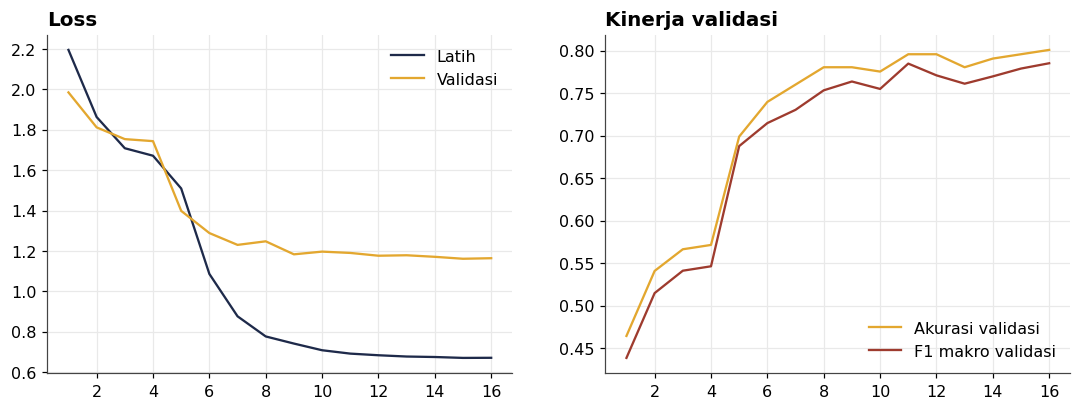

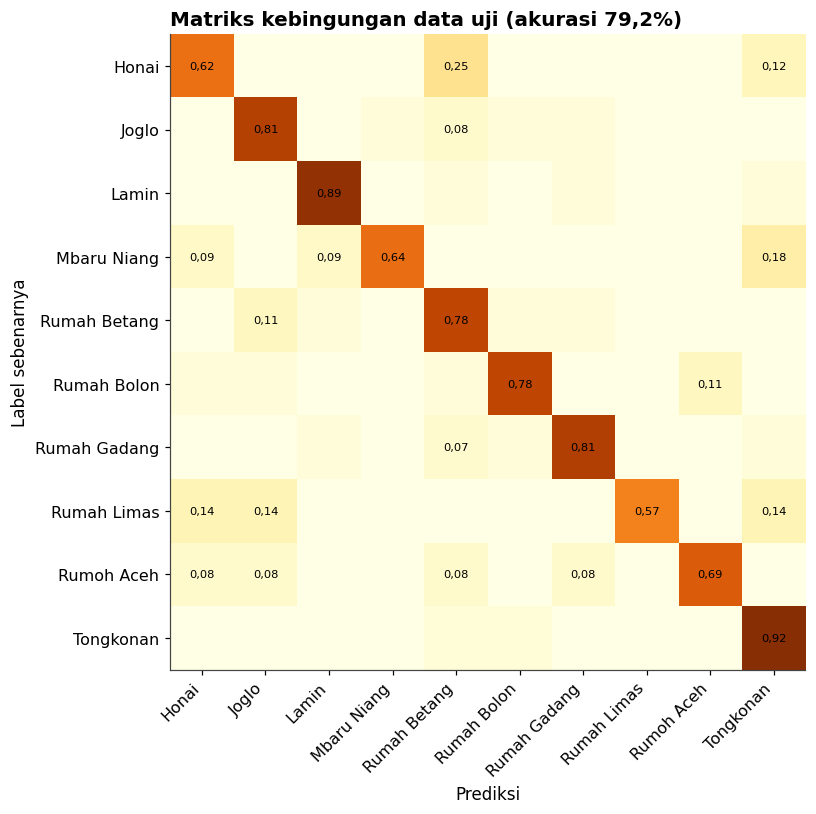

/tmp/ipykernel_484/798168616.py:37: DeprecationWarning:

You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html



ONNX 16.07 MB | selisih maksimum vs PyTorch: 7.03e-06


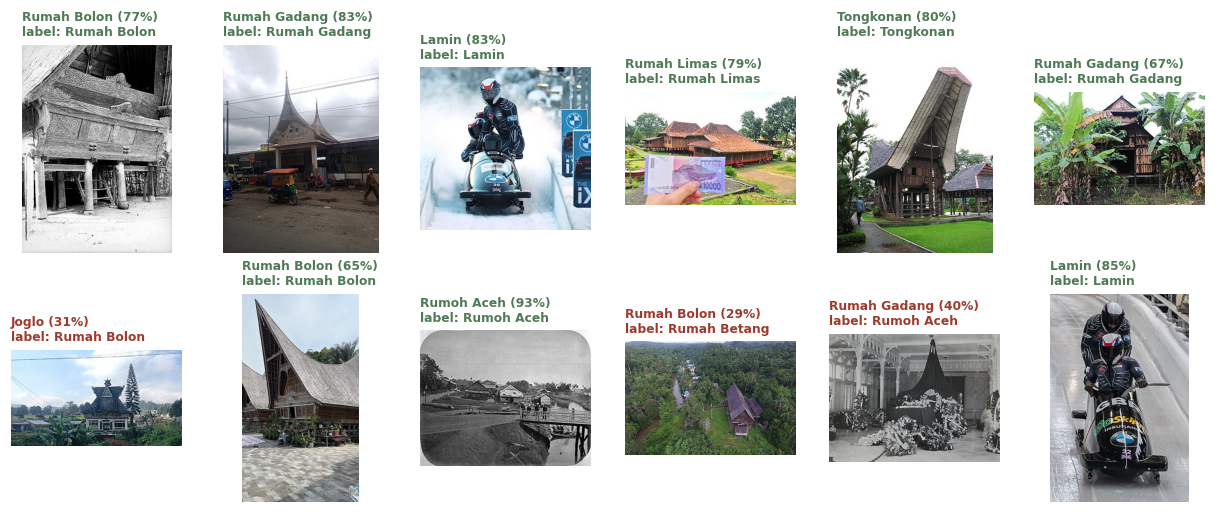

In [33]:
if CV_RESULT:
    h = pd.DataFrame(history)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(h['epoch'], h['loss_latih'], color=PAL['tarum'], label='Latih')
    axes[0].plot(h['epoch'], h['loss_validasi'], color=PAL['kunyit'], label='Validasi')
    axes[0].set_title('Loss')
    axes[0].legend()
    axes[1].plot(h['epoch'], h['akurasi_validasi'], color=PAL['kunyit'], label='Akurasi validasi')
    axes[1].plot(h['epoch'], h['f1_validasi'], color=PAL['mengkudu'], label='F1 makro validasi')
    axes[1].set_title('Kinerja validasi')
    axes[1].legend()
    save_fig(fig, 'fig12_cv_kurva_pelatihan', 'Kurva pelatihan model Kenali Rumah Adat')

    cm = confusion_matrix(y_te, p_te.argmax(1), labels=list(range(len(CLASSES))), normalize='true')
    fig, ax = plt.subplots(figsize=(8.5, 7.5))
    ax.imshow(cm, cmap='YlOrBr', vmin=0, vmax=1)
    ax.set_xticks(range(len(CLASSES)), CLASSES, rotation=45, ha='right')
    ax.set_yticks(range(len(CLASSES)), CLASSES)
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            if cm[i, j] >= 0.05:
                ax.text(j, i, fmt_dec(cm[i, j], 2), ha='center', va='center', fontsize=7.5)
    ax.grid(False)
    ax.set_xlabel('Prediksi')
    ax.set_ylabel('Label sebenarnya')
    ax.set_title(f"Matriks kebingungan data uji (akurasi {fmt_pct(CV_RESULT['akurasi_top1_uji'])})")
    save_fig(fig, 'fig13_cv_matriks_kebingungan', 'Matriks kebingungan ternormalisasi pada data uji')

    # Ekspor ONNX dan uji kesetaraan keluaran
    import onnxruntime as ort
    model_cpu = model.to('cpu').eval()
    dummy = torch.randn(1, 3, 224, 224)
    onnx_path = D['cv'] / 'rumah_adat.onnx'
    export_kw = dict(input_names=['input'], output_names=['logits'], dynamic_axes={'input': {0: 'batch'}, 'logits': {0: 'batch'}},
                     opset_version=17)
    try:
        torch.onnx.export(model_cpu, dummy, str(onnx_path), dynamo=False, **export_kw)
    except TypeError:
        torch.onnx.export(model_cpu, dummy, str(onnx_path), **export_kw)
    sess = ort.InferenceSession(str(onnx_path), providers=['CPUExecutionProvider'])
    xb = torch.stack([ImgDS(te_df.head(8), tf_eval)[i][0] for i in range(min(8, len(te_df)))])
    diff = float(np.abs(sess.run(None, {'input': xb.numpy()})[0] - model_cpu(xb).detach().numpy()).max())
    CV_RESULT['onnx_selisih_maks_vs_pytorch'] = diff
    CV_RESULT['ukuran_model_mb'] = round(onnx_path.stat().st_size / 1e6, 2)
    meta_kelas = {r['kelas']: r['provinsi'] for r in RUMAH_ADAT}
    labels = {'kelas': [{'indeks': i, 'nama': c, 'provinsi': meta_kelas.get(c)} for i, c in enumerate(CLASSES)],
              'praproses': {'resize': 256, 'center_crop': 224, 'mean': MEAN, 'std': STD, 'format': 'NCHW float32 RGB'},
              'input': 'input', 'output': 'logits (terapkan softmax)', 'metrik': CV_RESULT}
    (D['cv'] / 'labels.json').write_text(json.dumps(labels, ensure_ascii=False, indent=1), encoding='utf-8')
    (D['cv'] / 'metrics.json').write_text(json.dumps(CV_RESULT, ensure_ascii=False, indent=1), encoding='utf-8')
    print(f"ONNX {CV_RESULT['ukuran_model_mb']} MB | selisih maksimum vs PyTorch: {diff:.2e}")
    if diff > 1e-3:
        warn('Keluaran ONNX berbeda cukup jauh dari PyTorch. Periksa versi opset.')

    # Contoh prediksi
    sample_te = te_df.sample(n=min(12, len(te_df)), random_state=SEED)
    xs = torch.stack([tf_eval(Image.open(p).convert('RGB')) for p in sample_te['path']])
    probs = torch.softmax(model_cpu(xs), 1).detach().numpy()
    fig, axes = plt.subplots(2, 6, figsize=(14, 5.4))
    for ax, (_, rr), pr in zip(axes.ravel(), sample_te.iterrows(), probs):
        ax.imshow(Image.open(rr['path']))
        ax.axis('off')
        pred = CLASSES[pr.argmax()]
        ax.set_title(f"{pred} ({fmt_pct(pr.max(), 0)})\nlabel: {rr['kelas']}", fontsize=8,
                     color=PAL['daun'] if pred == rr['kelas'] else PAL['mengkudu'])
    save_fig(fig, 'fig14_cv_contoh_prediksi', 'Contoh prediksi model pada data uji (hijau benar, merah salah)', dpi=110)
    add_insight('cv', 'Model Kenali Rumah Adat',
                f"Model {CV_ARCH} untuk {len(CLASSES)} jenis rumah adat mencapai akurasi top-1 {fmt_pct(CV_RESULT['akurasi_top1_uji'])}, "
                f"akurasi top-3 {fmt_pct(CV_RESULT['akurasi_top3_uji'])}, dan F1 makro {fmt_dec(CV_RESULT['f1_makro_uji'])} pada "
                f"{CV_RESULT['n_uji']} gambar uji. Model berukuran {CV_RESULT['ukuran_model_mb']} MB dan berjalan di peramban melalui ONNX.")

## 11. Knowledge base RAG dan router percakapan

Asisten **Tanya Singkap** dirancang dengan tiga lapis agar selalu bisa merespons dengan wajar:

1. **Router intent** menangani sapaan dan percakapan ringan (halo, hai, assalamualaikum, selamat pagi, terima kasih, siapa kamu, bisa apa) tanpa perlu dokumen. Sapaan yang diikuti pertanyaan tetap diteruskan ke pencarian.
2. **Retrieval** mencari potongan pengetahuan paling relevan dengan ambang skor yang **dikalibrasi** dari data, bukan ditebak.
3. **Generasi** oleh LLM yang wajib menyertakan sumber dan menyatakan belum tahu bila konteks tidak memadai.

Isi knowledge base:

| Jenis dokumen | Isi |
|---|---|
| `tentang` | Misi SINGKAP, fitur, cara pakai, tim, etika, lisensi |
| `metodologi` | IKD, uji ketahanan, rekomendasi berkeadilan, Penjaga Kepekaan Budaya, model rumah adat |
| `konteks` | Fakta nasional bersumber (WBTbI, ketimpangan wisata, domain, unsur kebudayaan) |
| `temuan` | Seluruh temuan analisis notebook ini |
| `profil_provinsi`, `profil_domain` | Profil hasil analisis per provinsi dan per domain |
| `daftar_tersembunyi` | Daftar 100 warisan paling tersembunyi |
| `warisan` | Kartu setiap WBTbI beserta ringkasan Wikipedia |
| `ensiklopedia` | Ringkasan Wikipedia provinsi dan topik budaya umum |
| `rumah_adat` | Profil kelas model Kenali Rumah Adat |

In [34]:
SRC_WIKI_LIST = {'nama': 'Wikipedia: Daftar Warisan Budaya Takbenda Indonesia', 'url': WBTBI_URL, 'lisensi': 'CC BY-SA 4.0'}
SRC_SINGKAP = {'nama': 'Analisis tim SINGKAP (notebook ini)', 'url': 'internal', 'lisensi': 'CC BY-SA 4.0'}
KB = []


def add_doc(doc_id, jenis, judul, teks, sumber, provinsi=None, tags=None):
    KB.append({'doc_id': doc_id, 'jenis': jenis, 'judul': judul, 'teks': re.sub(r'\s+', ' ', teks).strip(),
               'sumber': sumber if isinstance(sumber, list) else [sumber], 'provinsi': provinsi, 'tags': tags or []})


# Tentang SINGKAP
STATIC = [
    ('tentang_singkap', 'tentang', 'Apa itu SINGKAP',
     'SINGKAP adalah singkatan dari Sistem Inteligensi Nusantara Guna Kebangkitan Aset Pusaka. Kata singkap berarti membuka tabir. '
     'SINGKAP adalah platform web berbasis kecerdasan artifisial dan data terbuka yang mengukur seberapa tersembunyi warisan budaya '
     'Indonesia yang telah ditetapkan, lalu mengarahkan wisatawan ke sana secara berkeadilan dan bertanggung jawab. '
     'SINGKAP dikembangkan oleh tim mahasiswa untuk Kompetisi Inovasi Budaya Indonesia BUDAYA GO! kategori Inovasi Digital.'),
    ('tentang_fitur', 'tentang', 'Fitur SINGKAP',
     'Fitur SINGKAP: Peta Singkap menampilkan Indeks Ketakterlihatan Digital per provinsi dan per warisan beserta alasan skornya. '
     'Jalur Singkap memberikan rekomendasi wisata budaya sesuai minat dan tujuan perjalanan dengan penataan ulang berkeadilan; '
     'subfitur Alih Jejak menawarkan alternatif tersembunyi saat pengguna memilih destinasi padat. Kenali Rumah Adat mengenali jenis '
     'rumah adat dari foto langsung di peramban. Tanya Singkap adalah asisten percakapan yang menjawab dengan sumber. '
     'Dasbor Prioritas Daerah membantu pemerintah daerah menentukan warisan yang perlu diangkat lebih dulu. Penjaga Kepekaan Budaya '
     'menahan warisan sakral atau rentan dari rekomendasi wisata. Klaim dan Koreksi Komunitas memberi jalur bagi pegiat budaya untuk '
     'meluruskan informasi.'),
    ('tentang_cara_pakai', 'tentang', 'Cara memakai SINGKAP',
     'Untuk mencari wisata budaya, buka Jalur Singkap, pilih minat seperti tari, kuliner, kriya, atau arsitektur, lalu pilih tujuan perjalanan. '
     'Geser pengaturan Pemerataan untuk melihat rekomendasi yang lebih beragam antardaerah. Untuk mengenali rumah adat, buka Kenali Rumah Adat '
     'dan unggah atau ambil foto bangunan; foto diproses di perangkat dan tidak dikirim ke server. Untuk melihat peta ketakterlihatan, '
     'buka Peta Singkap dan klik provinsi atau warisan untuk melihat komponen skornya. Untuk bertanya, ketik pertanyaan di Tanya Singkap.'),
    ('tentang_tim', 'tentang', 'Tim SINGKAP',
     'SINGKAP dikembangkan oleh Nazril (Sains Data, Universitas Negeri Surabaya, angkatan 2024), Nadia (Sains Data, Universitas Negeri '
     'Surabaya, angkatan 2023), dan Angel (Sistem Informasi, angkatan 2023), dengan dukungan penasihat dari bidang ilmu budaya.'),
    ('tentang_etika', 'tentang', 'Prinsip etika SINGKAP',
     'Prinsip etika SINGKAP: tidak semua warisan untuk ditonton, sehingga ritus dan upacara sakral ditahan sampai ada persetujuan; '
     'pemerataan tidak boleh menciptakan keramaian baru; setiap teks dan gambar menampilkan sumber dan lisensinya; asisten AI tidak '
     'mengarang narasi budaya dan selalu menyertakan sumber; komunitas pemilik budaya dapat meluruskan atau menahan informasi.'),
    ('tentang_data', 'tentang', 'Sumber data dan lisensi SINGKAP',
     'Seluruh data inti SINGKAP berasal dari sumber terbuka melalui API resmi: daftar WBTbI dari Wikipedia bahasa Indonesia (CC BY-SA 4.0), '
     'status dan kunjungan halaman dari Wikimedia, butir warisan dan museum dari Wikidata (CC0), objek bersejarah dari OpenStreetMap (ODbL), '
     'foto rumah adat dari Wikimedia Commons (lisensi per berkas), batas provinsi dari geoBoundaries (CC BY 4.0), dan arus wisata dari BPS. '
     'SINGKAP tidak mengambil data dari Google Maps, Instagram, atau TikTok karena ketentuan layanannya melarang pengambilan otomatis.'),
    ('metode_ikd', 'metodologi', 'Indeks Ketakterlihatan Digital (IKD)',
     'Indeks Ketakterlihatan Digital (IKD) dihitung dengan rumus IKD = K x (1 - V) x (1 - A). K adalah kekayaan budaya provinsi '
     '(jumlah WBTbI, keragaman domain, jumlah museum, jumlah situs warisan). V adalah visibilitas digital setiap warisan (artikel Wikipedia '
     'bahasa Indonesia, artikel bahasa Inggris, butir Wikidata, gambar utama, kunjungan halaman 12 bulan, panjang artikel). A adalah arus '
     'wisata provinsi dari BPS. Semua indikator dinormalisasi dengan peringkat persentil ke rentang 0 sampai 1. Nilai IKD tinggi berarti '
     'warisan kaya secara budaya, tidak terlihat secara digital, dan jarang dikunjungi. Bentuk perkalian dipilih agar warisan dari daerah '
     'berkekayaan rendah tidak mendapat skor tinggi hanya karena tidak terlihat. Ketiadaan artikel adalah indikator ketakterlihatan, '
     'bukan bukti bahwa warisan tidak dikenal masyarakat setempat.'),
    ('metode_ketahanan', 'metodologi', 'Uji ketahanan IKD',
     'IKD diuji dengan membandingkan beberapa skema agregasi (bobot setara, bobot PCA, aditif, tanpa arus wisata), ablasi setiap komponen '
     'visibilitas, dan irisan 100 warisan teratas. Stabilitas diukur dengan korelasi peringkat Spearman. Peringkat juga divalidasi bersama '
     'Dinas Kebudayaan dan Pariwisata serta budayawan di wilayah percontohan Jawa Timur.'),
    ('metode_rekomendasi', 'metodologi', 'Rekomendasi wisata berkeadilan',
     'Jalur Singkap menghitung relevansi dari kemiripan embedding minat pengguna dengan warisan, dikombinasikan dengan kedekatan geografis '
     'ke tujuan perjalanan. Skor = lambda x relevansi + (1 - lambda) x IKD. Daftar rekomendasi kemudian disusun dengan penalti untuk '
     'warisan dari provinsi yang sama agar tidak terjadi penumpukan. Lambda dipilih dengan aturan: retensi relevansi NDCG@10 tetap di atas '
     'batas minimum, koefisien Gini eksposur antarprovinsi tidak boleh naik sehingga tidak tercipta keramaian baru, lalu dipilih konfigurasi '
     'yang paling banyak mengangkat warisan tersembunyi. Warisan berstatus perlu persetujuan dikeluarkan sebelum perankingan.'),
    ('metode_kepekaan', 'metodologi', 'Penjaga Kepekaan Budaya',
     'Penjaga Kepekaan Budaya memberi status perlu persetujuan pada warisan di domain adat istiadat, ritus, dan perayaan serta warisan yang '
     'namanya mengandung kata seperti upacara, ritual, sakral, kematian, pengobatan, atau labuhan. Warisan berstatus ini tetap tampil sebagai '
     'informasi di peta, tetapi tidak direkomendasikan sebagai objek wisata sampai dikonfirmasi pemerintah daerah atau perwakilan komunitas. '
     'Komunitas dapat meminta warisan disembunyikan sepenuhnya. Daerah yang mulai ramai diberi penanda daya dukung.'),
    ('konteks_wbtbi', 'konteks', 'Jumlah penetapan Warisan Budaya Takbenda Indonesia',
     'Warisan Budaya Takbenda Indonesia (WBTbI) adalah warisan budaya takbenda yang ditetapkan pemerintah pusat. Sejak 2013 hingga 2025 '
     'terdapat 2.727 WBTbI yang ditetapkan. Pada 2025, Kementerian Kebudayaan menerima 804 usulan dari 35 provinsi dan menetapkan 514 warisan. '
     'Menteri Kebudayaan menyebut potensi warisan budaya takbenda Indonesia mencapai puluhan ribu. Kementerian menegaskan bahwa banyaknya '
     'WBTbI yang telah ditetapkan tidak boleh berhenti pada status penetapan, melainkan perlu tindak lanjut nyata sesuai UU Nomor 5 Tahun 2017 '
     'tentang Pemajuan Kebudayaan yang mencakup pelindungan, pengembangan, pemanfaatan, dan pembinaan.'),
    ('konteks_domain', 'konteks', 'Lima domain WBTbI dan unsur kebudayaan',
     'WBTbI dikelompokkan dalam lima domain: Tradisi dan Ekspresi Lisan; Seni Pertunjukan; Adat Istiadat Masyarakat, Ritus, dan Perayaan; '
     'Pengetahuan dan Kebiasaan Perilaku Mengenai Alam dan Semesta; serta Kemahiran dan Kerajinan Tradisional. Pada penetapan hingga 2022 '
     '(1.728 warisan), jumlahnya adalah 219 tradisi lisan, 503 seni pertunjukan, 491 adat istiadat, 75 pengetahuan alam, dan 440 kemahiran '
     'dan kerajinan. Koentjaraningrat merumuskan tujuh unsur kebudayaan universal: bahasa, sistem pengetahuan, organisasi sosial, sistem '
     'peralatan hidup dan teknologi, sistem mata pencaharian, sistem religi, dan kesenian. SINGKAP memetakan tradisi lisan ke bahasa dan '
     'kesenian; seni pertunjukan ke kesenian; adat istiadat ke sistem religi dan organisasi sosial; pengetahuan alam ke sistem pengetahuan '
     'dan mata pencaharian; kemahiran dan kerajinan ke sistem peralatan hidup dan teknologi serta mata pencaharian.'),
    ('konteks_ketimpangan_wisata', 'konteks', 'Ketimpangan arus wisatawan mancanegara',
     'Pada 2025, kunjungan wisatawan mancanegara ke Bali mencapai 7,05 juta atau 45,8 persen dari total 15,39 juta kunjungan wisatawan '
     'mancanegara ke Indonesia. Gubernur Bali menyampaikan devisa pariwisata Bali sebesar Rp176 triliun setara 55 persen dari devisa '
     'pariwisata nasional sebesar Rp320 triliun. Konsentrasi ini menunjukkan manfaat ekonomi pariwisata, termasuk pariwisata budaya, '
     'belum merata.'),
    ('konteks_budayago', 'konteks', 'Tentang BUDAYA GO!',
     'BUDAYA GO! adalah Kompetisi Inovasi Budaya Indonesia yang diselenggarakan Kementerian Kebudayaan melalui Direktorat Pengembangan '
     'Budaya Digital. Kategori Inovasi Digital dinilai dari keterkaitan budaya (25 persen), kelayakan teknis dan implementasi (25 persen), '
     'model bisnis dan potensi komersialisasi (20 persen), serta kejelasan dan kualitas proposal (30 persen).'),
]
SRC_CTX = {
    'konteks_wbtbi': [{'nama': 'detikTravel: 514 WBTb Ditetapkan', 'url': 'https://travel.detik.com/travel-news/d-8261926/514-warisan-budaya-takbenda-ditetapkan-ini-pesan-fadli-zon', 'lisensi': 'kutipan fakta'},
                      {'nama': 'Metro TV News', 'url': 'https://www.metrotvnews.com/read/NQAC0p00-kemenbud-tetapkan-514-warisan-budaya-tak-benda-baru-di-2025', 'lisensi': 'kutipan fakta'}],
    'konteks_domain': [{'nama': 'Direktorat Pelindungan Kebudayaan', 'url': 'https://kebudayaan.kemdikbud.go.id/dpk/sebanyak-1728-warisan-budaya-takbenda-wbtb-indonesia-ditetapkan/', 'lisensi': 'kutipan fakta'}],
    'konteks_ketimpangan_wisata': [{'nama': 'ANTARA', 'url': 'https://www.antaranews.com/berita/5587855/koster-catat-devisa-pariwisata-bali-2025-berkontribusi-55-persen', 'lisensi': 'kutipan fakta'}],
    'konteks_budayago': [{'nama': 'BUDAYA GO!', 'url': 'https://budayago.id/kategori', 'lisensi': 'kutipan fakta'}],
}
for did, jenis, judul, teks in STATIC:
    add_doc(did, jenis, judul, teks, SRC_CTX.get(did, SRC_SINGKAP))

FAQ = [
    ('Mengapa warisan tanpa artikel Wikipedia dianggap tersembunyi?',
     'Karena Wikipedia adalah salah satu sumber rujukan utama mesin pencari dan asisten AI. Ketiadaan artikel membuat warisan sulit ditemukan '
     'publik. Ini indikator ketakterlihatan digital, bukan berarti warisan tidak dikenal masyarakat setempat.'),
    ('Apakah SINGKAP menyuruh wisatawan datang ke upacara adat?',
     'Tidak. Warisan di domain adat istiadat, ritus, dan perayaan ditahan oleh Penjaga Kepekaan Budaya dan tidak direkomendasikan sebagai objek '
     'wisata sampai ada persetujuan pemerintah daerah atau komunitas.'),
    ('Bagaimana cara mengoreksi data warisan di SINGKAP?',
     'Gunakan fitur Klaim dan Koreksi Komunitas pada halaman warisan. Koreksi ditinjau sebelum ditampilkan dan tercatat dalam riwayat perubahan.'),
    ('Apakah foto yang saya unggah di Kenali Rumah Adat disimpan?',
     'Tidak. Model berjalan di peramban sehingga foto diproses di perangkat dan tidak dikirim ke server.'),
    ('Apa arti pengaturan Pemerataan di Jalur Singkap?',
     'Pengaturan Pemerataan adalah nilai lambda. Makin besar dorongan pemerataan, makin banyak rekomendasi dari daerah yang selama ini kurang terlihat.'),
    ('Apa bedanya WBTb dan WBTbI?',
     'WBTb adalah warisan budaya takbenda secara umum, misalnya tarian, upacara, kuliner, bahasa, dan kerajinan. WBTbI adalah warisan budaya '
     'takbenda yang telah resmi ditetapkan sebagai Warisan Budaya Takbenda Indonesia oleh pemerintah pusat.'),
]
add_doc('metode_landasan', 'metodologi', 'Landasan dan rujukan metodologi SINGKAP',
        'Rumus IKD adalah rancangan tim SINGKAP yang setiap tahap penyusunannya mengikuti kerangka baku indeks komposit OECD dan JRC (2008): '
        'normalisasi peringkat persentil, bobot setara dibandingkan bobot PCA, agregasi perkalian yang non-kompensatoris seperti rata-rata '
        'geometrik pada Indeks Pembangunan Manusia UNDP, serta uji sensitivitas. Rujukan: ' + ' '.join(f'{k}: {v}' for k, v in METHOD_REFS),
        SRC_SINGKAP)
for i, (q, a) in enumerate(FAQ):
    add_doc(f'faq_{i:02d}', 'tentang', q, f'Pertanyaan: {q} Jawaban: {a}', SRC_SINGKAP)

# Temuan analisis
for ins in INSIGHTS:
    add_doc(f"temuan_{ins['id']}", 'temuan', ins['judul'], f"Temuan analisis SINGKAP: {ins['judul']}. {ins['teks']}", SRC_SINGKAP)
add_doc('temuan_ringkasan', 'temuan', 'Ringkasan temuan utama SINGKAP',
        'Ringkasan temuan utama analisis SINGKAP: ' + ' '.join(f"({i + 1}) {x['teks']}" for i, x in enumerate(INSIGHTS)), SRC_SINGKAP)
print('Dokumen statis dan temuan:', len(KB))

Dokumen statis dan temuan: 33


In [35]:
# Profil provinsi dan domain
pts_count = (pts_gdf.groupby(['provinsi', 'jenis']).size().unstack(fill_value=0)
             if pts_gdf is not None and 'provinsi' in pts_gdf else pd.DataFrame())
for _, rr in reg.iterrows():
    p = rr['provinsi']
    sub = item[item['provinsi'] == p]
    if sub.empty:
        add_doc(f'prov_{norm_txt(p).replace(" ", "_")}', 'profil_provinsi', f'Profil SINGKAP Provinsi {p}',
                f'Profil SINGKAP Provinsi {p}: belum ada WBTbI yang terpetakan ke provinsi ini dalam data SINGKAP.', SRC_SINGKAP, p)
        continue
    dom = sub['domain_label'].value_counts()
    open_hidden = sub[sub['kepekaan'] == 'terbuka'].nlargest(5, 'IKD')['nama'].tolist()
    sensitive = sub[sub['kepekaan'] == 'perlu_persetujuan'].nlargest(3, 'IKD')['nama'].tolist()
    visible = sub.nlargest(3, 'pageviews_12b')['nama'].tolist()
    mus = int(pts_count.loc[p, 'museum']) if p in pts_count.index and 'museum' in pts_count else 0
    sit = int(pts_count.loc[p, 'situs_warisan']) if p in pts_count.index and 'situs_warisan' in pts_count else 0
    teks = (f"Profil SINGKAP Provinsi {p}. Jumlah WBTbI dalam data SINGKAP: {len(sub)}. Komposisi domain: "
            + '; '.join(f'{k} {v}' for k, v in dom.items())
            + f". Persentase warisan tanpa artikel Wikipedia bahasa Indonesia: {fmt_pct(rr['pct_tanpa_artikel'])}. "
            f"Nilai kekayaan budaya (K) {fmt_dec(rr['K'])}, visibilitas digital (V) {fmt_dec(rr['V'])}, "
            + (f"arus wisata (A) {fmt_dec(rr['A'])}, " if A_AVAILABLE else 'arus wisata belum tersedia, ')
            + f"IKD {fmt_dec(rr['IKD'], 3)} dengan peringkat {int(rr['peringkat_ikd'])} dari 34 provinsi. Tipologi: {rr['tipologi']}. "
            f"Museum terpetakan: {mus}. Situs warisan terpetakan: {sit}. "
            f"Warisan paling tersembunyi yang terbuka untuk dikunjungi: {', '.join(open_hidden) or 'belum ada'}. "
            f"Warisan yang perlu persetujuan komunitas sebelum dipromosikan: {', '.join(sensitive) or 'tidak ada'}. "
            f"Warisan yang paling sering dibaca di Wikipedia: {', '.join(visible)}.")
    add_doc(f'prov_{norm_txt(p).replace(" ", "_")}', 'profil_provinsi', f'Profil SINGKAP Provinsi {p}', teks, SRC_SINGKAP, p)

for code_, label in DOMAIN_LABEL.items():
    sub = item[item['domain'] == code_]
    if sub.empty:
        continue
    teks = (f"Profil domain {label} dalam SINGKAP. Jumlah WBTbI: {len(sub)}. Unsur kebudayaan terkait: {', '.join(UNSUR_KOENTJARA[code_])}. "
            f"Tanpa artikel Wikipedia bahasa Indonesia: {fmt_pct(1 - sub['ada_artikel_id'].mean())}. "
            f"Tanpa artikel bahasa Inggris: {fmt_pct(1 - sub['ada_artikel_en'].mean())}. "
            f"Provinsi dengan jumlah terbanyak: {', '.join(sub['provinsi'].value_counts().head(3).index)}. "
            f"Contoh warisan paling tersembunyi: {', '.join(sub.nlargest(5, 'IKD')['nama'])}. "
            f"Status perlu persetujuan: {fmt_pct((sub['kepekaan'] == 'perlu_persetujuan').mean())}.")
    add_doc(f'domain_{code_.lower()}', 'profil_domain', f'Profil domain {label}', teks, SRC_SINGKAP)

for k, part in enumerate(chunked(top100.to_dict('records'), 20)):
    teks = (f"Daftar warisan paling tersembunyi menurut IKD, peringkat {k * 20 + 1} sampai {k * 20 + len(part)}: "
            + '; '.join(f"{k * 20 + j + 1}. {r['nama']} ({r['provinsi']}, {DOMAIN_SHORT.get(r.get('domain') or '', r['domain_label'])}"
                        + (', perlu persetujuan' if r['kepekaan'] == 'perlu_persetujuan' else '') + ')'
                        for j, r in enumerate(part)))
    add_doc(f'top100_{k}', 'daftar_tersembunyi', f'Warisan paling tersembunyi {k * 20 + 1} sampai {k * 20 + len(part)}', teks, SRC_SINGKAP)

add_doc('metode_rekomendasi_hasil', 'temuan', 'Hasil evaluasi rekomendasi berkeadilan', f'Hasil evaluasi Jalur Singkap: {REC_TEXT}', SRC_SINGKAP)

# Kartu setiap warisan
N_RANKED = int(item['IKD'].notna().sum())
for _, r in item.iterrows():
    status = ('memiliki artikel Wikipedia bahasa Indonesia' + (' dan bahasa Inggris' if r['ada_artikel_en'] else ', belum ada versi bahasa Inggris')
              if r['ada_artikel_id'] else 'belum memiliki artikel Wikipedia')
    rank_txt = (f"IKD {fmt_dec(r['IKD'], 3)}, peringkat {int(r['peringkat_ikd'])} dari {N_RANKED} (makin kecil peringkat makin tersembunyi)"
                if pd.notna(r['IKD']) else 'IKD tidak dihitung karena provinsi tidak terpetakan')
    kep = ('perlu persetujuan pemerintah daerah atau komunitas sebelum dipromosikan sebagai objek wisata'
           if r['kepekaan'] == 'perlu_persetujuan' else 'terbuka untuk direkomendasikan')
    teks = (f"{r['nama']} adalah Warisan Budaya Takbenda Indonesia dari {r['provinsi']}, ditetapkan tahun {r['tahun']} dengan nomor "
            f"registrasi {r['no_registrasi']}. Domain: {r['domain_label']}. Unsur kebudayaan: {r['unsur_kebudayaan'] or 'belum terklasifikasi'}. "
            f"Status digital: {status}; kunjungan halaman 12 bulan terakhir {fmt_num(r['pageviews_12b'])}. {rank_txt}. "
            f"Status kepekaan: {kep}. {r['ringkasan'][:900]}")
    src = [SRC_WIKI_LIST]
    if r['ada_artikel_id']:
        src.append({'nama': f"Wikipedia: {r['judul_artikel']}",
                    'url': 'https://id.wikipedia.org/wiki/' + str(r['judul_artikel']).replace(' ', '_'), 'lisensi': 'CC BY-SA 4.0'})
    add_doc(r['id'], 'warisan', r['nama'], teks, src, r['provinsi'], [r['domain'] or 'lainnya', r['kepekaan']])
print('Total dokumen sejauh ini:', len(KB))

Total dokumen sejauh ini: 2003


In [36]:
# Ensiklopedia: provinsi, topik budaya umum, kelas rumah adat
TOPICS = ['Warisan budaya takbenda', 'Kebudayaan Indonesia', 'Pariwisata di Indonesia', 'Koentjaraningrat', 'Rumah adat',
          'Batik', 'Wayang', 'Gamelan', 'Keris', 'Angklung', 'Pencak silat', 'Noken', 'Saman (tarian)', 'Pantun', 'Kebaya',
          'Reog', 'Tari Bali', 'Jamu', 'Tenun', 'Songket', 'Kolintang', 'Sasando', 'Gudeg', 'Rendang', 'Tari Piring',
          'Kuda lumping', 'Ondel-ondel', 'Sigale-gale', 'Pinisi', 'Subak', 'Lompat batu', 'Pacu jalur', 'Karapan sapi',
          'Tari Kecak', 'Tari Jaipong', 'Tari Pendet', 'Ulos', 'Tapis (kain)', 'Tenun ikat', 'Rumah Gadang', 'Tongkonan',
          'Joglo', 'Honai', 'Rumah Bolon', 'Lamin', 'Rumah Betang', 'Rumoh Aceh', 'Rumah Limas', 'Mbaru Niang', 'Omo Hada',
          'Dusun Sade', 'Museum di Indonesia', 'Desa wisata']
ency_titles = PROV34 + TOPICS
ENCY = wiki_extracts(ency_titles)
missing_ency = [t for t in ency_titles if t not in ENCY]
if missing_ency:
    print('Topik tanpa ringkasan (dilewati):', missing_ency[:15], '...' if len(missing_ency) > 15 else '')
for t, txt in ENCY.items():
    add_doc(f"ency_{norm_txt(t).replace(' ', '_')}", 'ensiklopedia', t, f'{t}. {txt[:2500]}',
            {'nama': f'Wikipedia: {t}', 'url': 'https://id.wikipedia.org/wiki/' + t.replace(' ', '_'), 'lisensi': 'CC BY-SA 4.0'},
            t if t in PROV34 else None)

if CV_RESULT:
    for c in CV_RESULT['kelas']:
        prov = next(r['provinsi'] for r in RUMAH_ADAT if r['kelas'] == c)
        n_img = int((cv_meta['kelas'] == c).sum())
        f1c = report.get(c, {}).get('f1-score')
        add_doc(f"rumahadat_{norm_txt(c).replace(' ', '_')}", 'rumah_adat', f'Rumah adat {c}',
                f"{c} adalah salah satu kelas yang dikenali fitur Kenali Rumah Adat SINGKAP, berasal dari {prov}. Model dilatih dengan "
                f"{n_img} foto berlisensi terbuka dari Wikimedia Commons" + (f" dan memiliki F1 {fmt_dec(f1c)} pada data uji" if f1c is not None else '')
                + f". {ENCY.get(c, '')[:1200]}",
                [{'nama': 'Wikimedia Commons', 'url': 'https://commons.wikimedia.org', 'lisensi': 'per berkas'}], prov)
register_source('Ringkasan Wikipedia untuk knowledge base', 'https://id.wikipedia.org', 'CC BY-SA 4.0',
                'ringkasan pembuka artikel', len(ENCY) + len(EXTRACTS))

# Pemotongan menjadi chunk
def chunk_text(text, size=170, overlap=40):
    w = text.split()
    if len(w) <= size + 30:
        return [text]
    return [' '.join(w[i:i + size]) for i in range(0, len(w) - overlap, size - overlap)]


CHUNKS = []
for d in KB:
    for j, part in enumerate(chunk_text(d['teks'])):
        body = part if j == 0 else f"{d['judul']}. {part}"
        CHUNKS.append({'chunk_id': f"{d['doc_id']}#{j}", 'doc_id': d['doc_id'], 'jenis': d['jenis'], 'judul': d['judul'],
                       'teks': body, 'provinsi': d['provinsi'], 'sumber': d['sumber']})
CHUNK_EMB = embed([f"{c['judul']}. {c['teks']}" for c in CHUNKS])
kb_stats = pd.Series(Counter(c['jenis'] for c in CHUNKS)).rename('jumlah_chunk').to_frame()
display(kb_stats)
log(f'Knowledge base: {len(KB)} dokumen, {len(CHUNKS)} chunk, dimensi {CHUNK_EMB.shape[1]}')

Ringkasan artikel (id):   0%|          | 0/5 [00:00<?, ?it/s]

Topik tanpa ringkasan (dilewati): ['Saman (tarian)', 'Sigale-gale', 'Lompat batu', 'Tapis (kain)', 'Honai', 'Rumoh Aceh', 'Dusun Sade', 'Museum di Indonesia'] 


Batches:   0%|          | 0/34 [00:00<?, ?it/s]

,jumlah_chunk
tentang,12
metodologi,7
konteks,4
temuan,15
profil_provinsi,34
profil_domain,5
daftar_tersembunyi,5
warisan,1957
ensiklopedia,108
rumah_adat,10


Knowledge base: 2092 dokumen, 2157 chunk, dimensi 384


### Router intent untuk sapaan dan percakapan ringan

In [37]:
INTENTS = [
    {'intent': 'salam_islam', 'pola': [r'^(as+alamu\s*al[ae]i?kum|asalamualaikum|assalamualaikum|asw|aslm)\b'],
     'contoh': ['assalamualaikum', 'assalamualaikum wr wb', 'asalamualaikum kak'],
     'maks_kata': 8, 'jawaban': ['Waalaikumsalam warahmatullahi wabarakatuh. Saya Singkap, siap membantu menjelajahi warisan budaya Nusantara. Mau mulai dari mana?']},
    {'intent': 'sapaan', 'pola': [r'^(h+a+l+o+|h+a+l+l+o+|h+a+i+|h+e+y+|h+i+|h+e+l+o+|hello|p+|permisi|punten|spada|halo\w*|hai\w*|hi\w*|oi|woi)'
                                 r'(\s+(kak|kakak|min|mimin|admin|bang|mas|mbak|sis|gan|singkap|bot|semua|guys|sobat|teman|bro))*$'],
     'contoh': ['halo', 'hai', 'hi', 'haloo kak', 'hai singkap', 'p', 'permisi', 'hello', 'hey min'], 'maks_kata': 6,
     'jawaban': ['Halo! Saya Singkap, asisten untuk menjelajahi warisan budaya Nusantara yang belum banyak dikenal. Kamu bisa tanya tentang suatu warisan, minta rekomendasi wisata budaya, atau cari tahu provinsi mana yang paling tersembunyi.',
                 'Hai! Senang bertemu. Saya bisa bantu cari warisan budaya tersembunyi, menjelaskan cara kerja Indeks Ketakterlihatan Digital, atau menyusun ide perjalanan budaya. Mau coba yang mana?']},
    {'intent': 'salam_waktu', 'pola': [r'^(selamat\s+)?(pagi|siang|sore|malam)(\s+(kak|min|semua|singkap|bro|sis))*$'],
     'contoh': ['selamat pagi', 'pagi kak', 'selamat malam min', 'sore'], 'maks_kata': 4,
     'jawaban': ['Selamat datang di SINGKAP! Ada warisan budaya yang ingin kamu singkap hari ini?']},
    {'intent': 'terima_kasih', 'pola': [r'\b(terima\s*kasih|terimakasih|makasih|makasi|trims|thanks|thank\s*you|thx|tq|tengkyu|matur\s*nuwun|hatur\s*nuhun)\b'],
     'contoh': ['terima kasih', 'makasih ya', 'thanks', 'tq kak', 'matur nuwun'], 'maks_kata': 4,
     'jawaban': ['Sama-sama! Kalau ada warisan lain yang ingin kamu ketahui, tanyakan saja.']},
    {'intent': 'pamit', 'pola': [r'\b(dadah|bye|sampai\s+jumpa|see\s+you|pamit|good\s*bye)\b'],
     'contoh': ['dadah', 'bye', 'sampai jumpa', 'pamit dulu ya'], 'maks_kata': 4,
     'jawaban': ['Sampai jumpa! Semoga perjalanan budayamu menyenangkan.']},
    {'intent': 'identitas', 'pola': [r'\b(siapa\s+(kamu|anda|ini|namamu)|kamu\s+(siapa|itu\s+apa)|apa\s+itu\s+singkap|singkap\s+itu\s+apa|'
                                    r'ini\s+(aplikasi|web|website|situs)\s+apa|kamu\s+ai\b)'],
     'contoh': ['siapa kamu', 'kamu siapa', 'apa itu singkap', 'ini web apa'], 'maks_kata': 7,
     'jawaban': ['Saya Singkap, asisten dari platform SINGKAP (Sistem Inteligensi Nusantara Guna Kebangkitan Aset Pusaka). Saya membantu menemukan warisan budaya Indonesia yang sudah ditetapkan tetapi belum banyak dikenal, dan setiap jawaban saya sertai sumbernya.']},
    {'intent': 'kemampuan', 'pola': [r'\b(bisa\s+apa|bisa\s+bantu\s+apa|bantu\s+apa|fitur(nya)?\s+apa|cara\s+(pakai|menggunakan|make)|'
                                    r'apa\s+saja\s+yang\s+bisa|gimana\s+cara\s+pakai|help|bantuan)\b'],
     'contoh': ['bisa apa', 'kamu bisa bantu apa', 'fiturnya apa saja', 'cara pakai', 'help'], 'maks_kata': 8,
     'jawaban': ['Saya bisa: menjelaskan warisan budaya takbenda Indonesia beserta sumbernya; menunjukkan provinsi dan warisan yang paling tersembunyi menurut IKD; membantu ide perjalanan budaya lewat Jalur Singkap; dan menjelaskan cara kerja fitur seperti Kenali Rumah Adat dan Penjaga Kepekaan Budaya.']},
    {'intent': 'pujian', 'pola': [r'^(keren|mantap|mantul|bagus|hebat|wow|wah|asik|asyik|nice|good)(\s+\w+){0,3}$'],
     'contoh': ['keren', 'mantap banget', 'wah bagus', 'nice'], 'maks_kata': 4,
     'jawaban': ['Terima kasih! Masih banyak warisan yang menunggu untuk disingkap. Mau lanjut menjelajah?']},
]
QUICK_REPLIES = ['Apa itu IKD?', 'Warisan tersembunyi di Jawa Timur', 'Rekomendasi wisata budaya', 'Provinsi paling tersembunyi']
ACTION_RE = re.compile(r'\b(rekomendasi\w*|saran(kan)?|liburan|jalan\s*-?\s*jalan|itinerary|rute|destinasi|mau\s+ke|wisata\s+ke)\b')
GREETING_PREFIX = re.compile(r'^(h+a+l+o+|h+a+i+|hai|hi|hello|hey|permisi|assalamu\w*|selamat\s+(pagi|siang|sore|malam))\b[\s,!.]*'
                             r'(kak|min|admin|singkap|semua)?[\s,!.]*')
for it in INTENTS:
    it['_re'] = [re.compile(p) for p in it['pola']]
_TOPIC_WORDS = ['warisan', 'budaya', 'wbtb', 'wbtbi', 'ikd', 'singkap', 'adat', 'tari', 'tarian', 'tradisi', 'tradisional',
                'upacara', 'ritual', 'kuliner', 'makanan', 'minuman', 'kue', 'rumah', 'wisata', 'museum', 'candi', 'situs',
                'kerajinan', 'tenun', 'batik', 'songket', 'ulos', 'wayang', 'gamelan', 'musik', 'lagu', 'cerita', 'legenda',
                'pantun', 'syair', 'bahasa', 'aksara', 'provinsi', 'daerah', 'suku', 'etnis', 'tersembunyi', 'rekomendasi',
                'liburan', 'pusaka', 'kesenian', 'silat', 'permainan', 'pakaian', 'senjata', 'keris', 'koentjaraningrat',
                'indeks', 'ketakterlihatan', 'visibilitas', 'kekayaan', 'kepekaan', 'jalur', 'peta', 'dasbor', 'pemerataan']
TOPIC_RE = re.compile(r'\b(' + '|'.join(sorted(set(_TOPIC_WORDS) | {norm_txt(a) for a in _ALIAS}, key=len, reverse=True)) + r')\b')


def norm_chat(s):
    s = unicodedata.normalize('NFKC', str(s)).lower()
    s = re.sub(r'[^\w\s]', ' ', s)
    return re.sub(r'\s+', ' ', s).strip()


INTENT_EX = [(it['intent'], ex) for it in INTENTS for ex in it['contoh']]
INTENT_EX_EMB = embed([e for _, e in INTENT_EX], kind='query')


def detect_intent(msg, tau_intent=0.93):
    t = norm_chat(msg)
    if not t:
        return 'kosong', 1.0
    for it in INTENTS:
        if any(r.search(t) for r in it['_re']) and len(t.split()) <= it['maks_kata']:
            return it['intent'], 1.0
    if len(t.split()) <= 3:
        sims = INTENT_EX_EMB @ embed([t], kind='query')[0]
        j = int(sims.argmax())
        if sims[j] >= tau_intent:
            return INTENT_EX[j][0], float(sims[j])
    return None, 0.0


def retrieve(query, k=6, provinsi=None):
    q = embed([query], kind='query')[0]
    sims = CHUNK_EMB @ q
    if provinsi:
        sims = sims + 0.02 * np.array([c['provinsi'] == provinsi for c in CHUNKS])
    top = np.argsort(-sims)[:k]
    return [(CHUNKS[i], float(sims[i])) for i in top]

{
 "ambang_tau": 0.844653844833374,
 "hit_at_1": 0.952054794520548,
 "hit_at_5": 0.9965753424657534,
 "tpr_pada_tau": 0.9965753424657534,
 "fpr_pada_tau": 0.0,
 "n_pertanyaan_positif": 292,
 "n_pertanyaan_negatif": 30
}


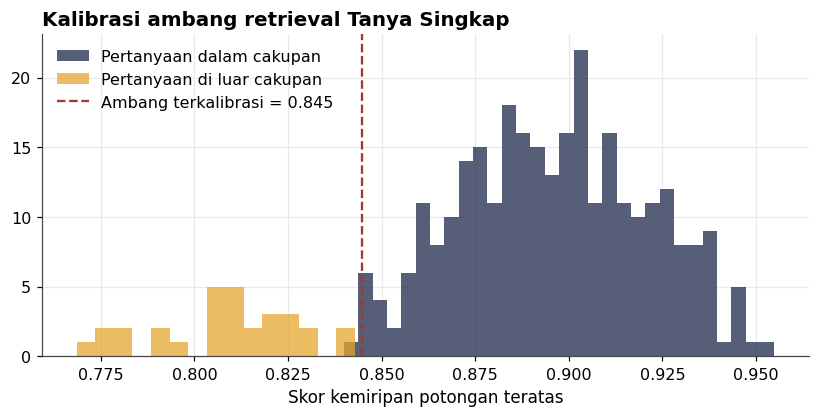

In [38]:
# Kalibrasi ambang retrieval
from sklearn.metrics import roc_curve

rng_q = np.random.default_rng(SEED)
pos_q = []
item_docs = [d for d in KB if d['jenis'] == 'warisan']
for di in rng_q.choice(len(item_docs), size=min(250, len(item_docs)), replace=False):
    d = item_docs[di]
    tmpl = rng_q.choice(['Apa itu {n}?', '{n} berasal dari mana?', 'Ceritakan tentang {n}', 'Apakah {n} termasuk warisan budaya takbenda?'])
    pos_q.append((tmpl.format(n=d['judul']), d['judul']))
for p in PROV34:
    pos_q.append((f'Warisan apa yang paling tersembunyi di {p}?', f'Profil SINGKAP Provinsi {p}'))
pos_q += [('Apa itu IKD?', 'Indeks Ketakterlihatan Digital (IKD)'), ('Bagaimana rumus indeks ketakterlihatan?', 'Indeks Ketakterlihatan Digital (IKD)'),
          ('Berapa jumlah WBTbI yang sudah ditetapkan?', 'Jumlah penetapan Warisan Budaya Takbenda Indonesia'),
          ('Kenapa upacara adat tidak direkomendasikan?', 'Penjaga Kepekaan Budaya'),
          ('Berapa persen wisman yang ke Bali?', 'Ketimpangan arus wisatawan mancanegara'),
          ('Apa saja unsur kebudayaan menurut Koentjaraningrat?', 'Lima domain WBTbI dan unsur kebudayaan'),
          ('Siapa saja tim pembuat SINGKAP?', 'Tim SINGKAP'), ('Data SINGKAP diambil dari mana?', 'Sumber data dan lisensi SINGKAP')]
NEG_Q = ['Siapa presiden Amerika Serikat sekarang?', 'Berapa harga bitcoin hari ini?', 'Cara install Python di Windows',
         'Skor pertandingan sepak bola tadi malam', 'Resep kue brownies cokelat lumer', 'Bagaimana cara membuat website dengan React?',
         'Kapan iPhone terbaru rilis?', 'Jelaskan teori relativitas Einstein', 'Cuaca Jakarta besok', 'Berapa 25 dikali 48?',
         'Rekomendasi laptop gaming murah', 'Siapa pemenang Piala Dunia 2022?', 'Cara diet cepat turun 5 kilo', 'Terjemahkan hello ke bahasa Jepang',
         'Apa itu machine learning?', 'Bagaimana cara investasi saham?', 'Lirik lagu terbaru yang viral', 'Jadwal kereta Surabaya Malang',
         'Cara mengurus SIM online', 'Film horor terbaik tahun ini', 'Bagaimana cara kerja mesin mobil?', 'Kenapa langit berwarna biru?',
         'Tips lolos wawancara kerja', 'Apa ibu kota Australia?', 'Cara memperbaiki wifi lemot', 'Harga emas per gram hari ini',
         'Bagaimana cara menulis skripsi?', 'Penyebab gempa bumi', 'Apa itu blockchain?', 'Daftar planet tata surya']
pos_scores = [retrieve(q, k=1)[0][1] for q, _ in pos_q]
neg_scores = [retrieve(q, k=1)[0][1] for q in NEG_Q]
y_true = np.r_[np.ones(len(pos_scores)), np.zeros(len(neg_scores))]
fpr, tpr, thr = roc_curve(y_true, np.r_[pos_scores, neg_scores])
TAU = float(thr[np.argmax(tpr - fpr)])
hits1 = np.mean([retrieve(q, k=1)[0][0]['judul'] == tgt for q, tgt in pos_q])
hits5 = np.mean([any(c['judul'] == tgt for c, _ in retrieve(q, k=5)) for q, tgt in pos_q])
RAG_EVAL = {'ambang_tau': TAU, 'hit_at_1': float(hits1), 'hit_at_5': float(hits5),
            'tpr_pada_tau': float(tpr[np.argmax(tpr - fpr)]), 'fpr_pada_tau': float(fpr[np.argmax(tpr - fpr)]),
            'n_pertanyaan_positif': len(pos_q), 'n_pertanyaan_negatif': len(NEG_Q)}
print(json.dumps(RAG_EVAL, indent=1))

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.hist(pos_scores, bins=30, alpha=0.75, color=PAL['tarum'], label='Pertanyaan dalam cakupan')
ax.hist(neg_scores, bins=15, alpha=0.75, color=PAL['kunyit'], label='Pertanyaan di luar cakupan')
ax.axvline(TAU, color=PAL['mengkudu'], ls='--', label=f'Ambang terkalibrasi = {TAU:.3f}')
ax.set_title('Kalibrasi ambang retrieval Tanya Singkap')
ax.set_xlabel('Skor kemiripan potongan teratas')
ax.legend()
save_fig(fig, 'fig15_kalibrasi_rag', 'Distribusi skor retrieval untuk pertanyaan dalam dan di luar cakupan beserta ambang')
add_insight('rag', 'Asisten yang tahu batas pengetahuannya',
            f"Pada uji {len(pos_q)} pertanyaan dalam cakupan, dokumen yang tepat ditemukan di posisi pertama untuk {fmt_pct(hits1)} pertanyaan "
            f"dan di lima teratas untuk {fmt_pct(hits5)}. Ambang terkalibrasi memisahkan pertanyaan di luar cakupan dengan tingkat salah terima "
            f"{fmt_pct(RAG_EVAL['fpr_pada_tau'])}.")

In [39]:
# Router lengkap dan uji
def route(msg):
    t = norm_chat(msg)
    intent, sc = detect_intent(msg)
    if intent == 'kosong':
        return {'jenis': 'intent', 'intent': 'kosong', 'jawaban': 'Silakan ketik pertanyaanmu tentang warisan budaya Nusantara.'}
    if intent:
        it = next(x for x in INTENTS if x['intent'] == intent)
        return {'jenis': 'intent', 'intent': intent, 'jawaban': random.choice(it['jawaban']), 'saran': QUICK_REPLIES}
    sapa = bool(GREETING_PREFIX.match(t))
    query = GREETING_PREFIX.sub('', t).strip() or t
    hits = retrieve(query, k=6)
    aksi = 'buka_jalur_singkap' if ACTION_RE.search(t) else None
    on_topic = bool(TOPIC_RE.search(norm_txt(query)))
    if hits[0][1] < TAU and not on_topic:
        return {'jenis': 'tidak_tahu', 'sapa': sapa, 'aksi': aksi, 'skor': hits[0][1],
                'jawaban': 'Maaf, saya belum punya informasi yang cukup untuk menjawab itu. Saya fokus pada warisan budaya Indonesia, '
                           'misalnya: apa itu suatu warisan, warisan tersembunyi di suatu provinsi, atau cara kerja SINGKAP.',
                'saran': QUICK_REPLIES}
    return {'jenis': 'rag', 'sapa': sapa, 'aksi': aksi, 'skor': hits[0][1], 'konteks': hits,
            'di_bawah_ambang': hits[0][1] < TAU}


ROUTER_TESTS = [('halo', 'intent'), ('hai', 'intent'), ('haloo kak', 'intent'), ('p', 'intent'), ('hi singkap', 'intent'),
                ('Assalamualaikum', 'intent'), ('selamat malam min', 'intent'), ('makasih ya', 'intent'), ('terima kasih banyak', 'intent'),
                ('siapa kamu?', 'intent'), ('kamu bisa apa', 'intent'), ('keren banget', 'intent'), ('dadah', 'intent'),
                ('halo, apa itu IKD?', 'rag'), ('hai kak, warisan tersembunyi di Jawa Timur apa saja?', 'rag'),
                ('Apa itu indeks ketakterlihatan digital?', 'rag'), ('rekomendasi wisata budaya di Sumatera Barat', 'rag'),
                ('Berapa jumlah WBTbI?', 'rag'), ('harga bitcoin hari ini', 'tidak_tahu'), ('cara install python', 'tidak_tahu'),
                ('siapa pemenang piala dunia 2022', 'tidak_tahu')]
res = []
for m, expected in ROUTER_TESTS:
    out = route(m)
    res.append({'pesan': m, 'harapan': expected, 'hasil': out['jenis'], 'intent': out.get('intent'), 'aksi': out.get('aksi'),
                'skor': round(out.get('skor', 1.0), 3), 'benar': out['jenis'] == expected})
router_eval = pd.DataFrame(res)
RAG_EVAL['akurasi_router'] = float(router_eval['benar'].mean())
router_eval.to_csv(D['rag'] / 'uji_router.csv', index=False)
display(router_eval)
print('Akurasi router:', fmt_pct(RAG_EVAL['akurasi_router']))

,pesan,harapan,hasil,intent,aksi,skor,benar
0,halo,intent,intent,sapaan,None,1.000,True
1,hai,intent,intent,sapaan,None,1.000,True
2,haloo kak,intent,intent,sapaan,None,1.000,True
3,p,intent,intent,sapaan,None,1.000,True
4,hi singkap,intent,intent,sapaan,None,1.000,True
5,Assalamualaikum,intent,intent,salam_islam,None,1.000,True
6,selamat malam min,intent,intent,salam_waktu,None,1.000,True
7,makasih ya,intent,intent,terima_kasih,None,1.000,True
8,terima kasih banyak,intent,intent,terima_kasih,None,1.000,True
9,siapa kamu?,intent,intent,identitas,None,1.000,True


Akurasi router: 100,0%


In [40]:
SYSTEM_PROMPT = '''Kamu adalah Singkap, asisten dari platform SINGKAP (Sistem Inteligensi Nusantara Guna Kebangkitan Aset Pusaka).
Tugasmu membantu orang mengenal warisan budaya takbenda Indonesia, terutama yang belum banyak dikenal, dan menjelaskan cara kerja SINGKAP.

Aturan:
1. Sapaan dan basa-basi (halo, hai, terima kasih, apa kabar) dijawab ramah dan singkat tanpa perlu sumber, lalu tawarkan bantuan.
2. Untuk pertanyaan faktual, jawab HANYA berdasarkan KONTEKS yang diberikan. Cantumkan sumber dengan format [1], [2] sesuai nomor konteks.
3. Bila konteks tidak memuat jawabannya, katakan dengan jujur bahwa kamu belum punya informasinya. Jangan mengarang fakta budaya, angka, atau sejarah.
4. Warisan berstatus "perlu persetujuan" tidak boleh disarankan sebagai objek wisata. Jelaskan bahwa warisan tersebut memerlukan persetujuan komunitas atau pemerintah daerah.
5. Saat merekomendasikan wisata, utamakan warisan yang tersembunyi (IKD tinggi) namun tetap relevan dengan minat pengguna, dan sarankan membuka fitur Jalur Singkap.
6. Gunakan bahasa yang sama dengan pengguna. Jawab ringkas, jelas, dan hangat. Hindari daftar yang terlalu panjang.
7. Jangan membahas topik di luar budaya, pariwisata budaya, dan SINGKAP secara panjang; arahkan kembali dengan sopan.'''


def build_prompt(query, hits):
    ctx = '\n'.join(f"[{i + 1}] {c['judul']}: {c['teks']} (sumber: {c['sumber'][0]['nama']})" for i, (c, _) in enumerate(hits))
    return f'KONTEKS:\n{ctx}\n\nPERTANYAAN PENGGUNA: {query}'


GEMINI_OK = False
if RUN_GEMINI_TEST and GEMINI_API_KEY:
    try:
        from google import genai
        from google.genai import types
        client = genai.Client(api_key=GEMINI_API_KEY)
        names = [m.name.replace('models/', '') for m in client.models.list()]
        if GEMINI_MODEL not in names:
            lite = sorted([n for n in names if 'flash-lite' in n and 'preview' not in n], reverse=True) or \
                   sorted([n for n in names if 'flash' in n], reverse=True)
            warn(f'Model {GEMINI_MODEL} tidak tersedia. Memakai {lite[0] if lite else names[0]}.')
            GEMINI_MODEL = lite[0] if lite else names[0]

        def ask(msg):
            r = route(msg)
            if r['jenis'] != 'rag':
                return r['jawaban']
            resp = client.models.generate_content(
                model=GEMINI_MODEL, contents=build_prompt(GREETING_PREFIX.sub('', norm_chat(msg)) or msg, r['konteks']),
                config=types.GenerateContentConfig(system_instruction=SYSTEM_PROMPT, temperature=0.2, max_output_tokens=500))
            return resp.text

        demo = []
        for m in ['halo', 'Apa itu IKD dan bagaimana menghitungnya?', 'hai kak, warisan apa yang paling tersembunyi di Jawa Timur?',
                  f"Ceritakan tentang {top100.iloc[0]['nama']}", 'Rekomendasikan wisata tari tradisional di luar Bali',
                  'Berapa harga bitcoin?', 'terima kasih']:
            a = ask(m)
            demo.append({'pertanyaan': m, 'jawaban': a})
            display(Markdown(f'**Pengguna:** {m}\n\n**Singkap:** {a}\n\n---'))
        pd.DataFrame(demo).to_csv(D['rag'] / 'contoh_jawaban_gemini.csv', index=False)
        GEMINI_OK = True
        RAG_EVAL['model_gemini_uji'] = GEMINI_MODEL
    except Exception as e:
        warn(f'Uji Gemini gagal: {e}')
else:
    print('Uji Gemini dilewati (GEMINI_API_KEY belum diset di Secrets).')

**Pengguna:** halo

**Singkap:** Halo! Saya Singkap, asisten untuk menjelajahi warisan budaya Nusantara yang belum banyak dikenal. Kamu bisa tanya tentang suatu warisan, minta rekomendasi wisata budaya, atau cari tahu provinsi mana yang paling tersembunyi.

---

**Pengguna:** Apa itu IKD dan bagaimana menghitungnya?

**Singkap:** Halo! Senang bisa membantu Anda mengenal warisan budaya nusantara dan platform SINGKAP. 

Indeks Ketakterlihatan Digital (IKD) dihitung dengan rumus $\text{IKD} = K \times (1 - V) \times (1 - A)$ [1]. 

Berikut adalah penjelasan komponennya:
* **$K$ (Kekayaan budaya provinsi):** Jumlah WBTbI, keragaman domain, jumlah museum, dan jumlah situs warisan [1].
* **$V$ (Visibilitas digital):** Mencakup artikel Wikipedia bahasa Indonesia, artikel bahasa Inggris, butir Wikidata, gambar utama, kunjungan halaman 12 bulan, dan panjang artikel [1].
* **$A$ (Arus wisata provinsi):** Data dari BPS [1].

Semua indikator dinormalisasi dengan peringkat persentil ke rentang 0 sampai 1 [1]. Bentuk perkalian dipilih agar warisan dari daerah berkekayaan rendah tidak mendapat skor tinggi hanya karena tidak terlihat [1]. Nilai IKD yang tinggi menunjukkan bahwa warisan tersebut kaya secara budaya, tetapi belum banyak terlihat secara digital dan jarang dikunjungi [1].

Ada lagi yang ingin Anda ketahui tentang warisan budaya atau fitur SINGKAP?

---

**Pengguna:** hai kak, warisan apa yang paling tersembunyi di Jawa Timur?

**Singkap:** Warisan budaya takbenda yang paling tersembunyi dan terbuka untuk dikunjungi di Jawa Timur meliputi Mocoan Lontar Yusup Banyuwangi, Ajaran Samin Surosentiko Bojonegoro, Brojo Geni Tremas Pacitan, Ta' Butaan Jember, serta Tenun Ikat Bandar Kidul [1]. 

Jika Anda berencana berkunjung, silakan buka fitur **Jalur Singkap** untuk menjelajahi warisan-warisan tersembunyi tersebut!

---

**Pengguna:** Ceritakan tentang Berkhatam Al-Qur'an Lingga

**Singkap:** Halo! Senang bisa membantu Anda mengenal lebih dekat warisan budaya Indonesia. 

Berkhatam Al-Qur'an Lingga adalah Warisan Budaya Takbenda Indonesia yang berasal dari Provinsi Kepulauan Riau dan ditetapkan pada tahun 2019 dengan nomor registrasi 201900846 [1]. Tradisi ini termasuk dalam domain Adat Istiadat Masyarakat, Ritus, dan Perayaan, serta mencakup unsur kebudayaan sistem religi dan organisasi sosial [1]. 

Warisan budaya ini memiliki Indeks Kekayaan Budaya (IKD) sebesar 0,526 dan berada di peringkat 1 dari 1908 warisan, yang menjadikannya sangat tersembunyi [1]. Perlu diketahui bahwa Berkhatam Al-Qur'an Lingga memiliki status kepekaan "perlu persetujuan", sehingga memerlukan persetujuan dari pemerintah daerah atau komunitas sebelum dapat dipromosikan sebagai objek wisata [1]. 

Ada hal lain seputar warisan budaya atau fitur SINGKAP yang ingin kamu ketahui?

---

**Pengguna:** Rekomendasikan wisata tari tradisional di luar Bali

**Singkap:** Halo! Tentu, saya bisa bantu merekomendasikan wisata tari tradisional yang menarik di luar Bali. 

Saya rekomendasikan **Tari Balumpa** yang berasal dari Wakatobi, Sulawesi Tenggara [2]. Tarian pergaulan yang dibawakan oleh penari wanita ini ditampilkan untuk menyambut tamu terhormat dengan gerakan yang lembut, anggun, serta mencerminkan keramahan masyarakat setempat [2]. 

Karena tarian ini merupakan warisan budaya tersembunyi yang terbuka untuk direkomendasikan, kamu bisa memasukkannya ke dalam rencana perjalananmu dan membuka fitur **Jalur Singkap** untuk mengeksplorasinya lebih jauh [2]! Ada lagi yang ingin kamu ketahui?

---

**Pengguna:** Berapa harga bitcoin?

**Singkap:** Maaf, saya belum punya informasi yang cukup untuk menjawab itu. Saya fokus pada warisan budaya Indonesia, misalnya: apa itu suatu warisan, warisan tersembunyi di suatu provinsi, atau cara kerja SINGKAP.

---

**Pengguna:** terima kasih

**Singkap:** Sama-sama! Kalau ada warisan lain yang ingin kamu ketahui, tanyakan saja.

---

In [41]:
# Ekspor knowledge base
def jsonl(path, rows):
    with open(path, 'w', encoding='utf-8') as f:
        for r in rows:
            f.write(json.dumps(r, ensure_ascii=False) + '\n')


jsonl(D['rag'] / 'kb_documents.jsonl', KB)
jsonl(D['rag'] / 'kb_chunks.jsonl', CHUNKS)
np.save(D['rag'] / 'kb_embeddings.npy', CHUNK_EMB.astype('float32'))
pd.DataFrame({'id': [c['chunk_id'] for c in CHUNKS], 'content': [f"{c['judul']}. {c['teks']}" for c in CHUNKS],
              'metadata': [json.dumps({k: c[k] for k in ['doc_id', 'jenis', 'judul', 'provinsi', 'sumber']}, ensure_ascii=False) for c in CHUNKS],
              'embedding': ['[' + ','.join(f'{x:.6f}' for x in v) + ']' for v in CHUNK_EMB]}
             ).to_csv(D['rag'] / 'kb_pgvector_import.csv', index=False)
(D['rag'] / 'intents.json').write_text(json.dumps(
    {'intents': [{k: v for k, v in it.items() if k != '_re'} for it in INTENTS], 'quick_replies': QUICK_REPLIES,
     'pola_aksi_rekomendasi': ACTION_RE.pattern, 'pola_sapaan_awal': GREETING_PREFIX.pattern, 'pola_topik': TOPIC_RE.pattern}, ensure_ascii=False, indent=1), encoding='utf-8')
(D['rag'] / 'system_prompt.md').write_text(SYSTEM_PROMPT, encoding='utf-8')
parity_q = ['Apa itu IKD?', 'warisan tersembunyi di Jawa Timur', 'tari tradisional']
parity = {q: embed([q], kind='query')[0][:8].round(5).tolist() for q in parity_q}
RAG_CONFIG = {
    'embedding_model': EMBED_MODEL, 'embedding_web_transformers_js': 'Xenova/multilingual-e5-small',
    'prefix_query': 'query: ', 'prefix_passage': 'passage: ', 'normalisasi': 'L2', 'dimensi': int(CHUNK_EMB.shape[1]),
    'top_k': 6, 'ambang_tau': TAU, 'urutan_router': ['intent (regex lalu embedding contoh)', 'retrieval', 'ambang tau atau pola topik', 'LLM dengan sitasi'],
    'llm': GEMINI_MODEL, 'temperature': 0.2, 'evaluasi': RAG_EVAL,
    'uji_kesetaraan_embedding': {'catatan': 'Delapan nilai pertama embedding query di notebook. Hasil di web harus mendekati nilai ini.',
                                 'nilai': parity},
}
(D['rag'] / 'rag_config.json').write_text(json.dumps(RAG_CONFIG, ensure_ascii=False, indent=1), encoding='utf-8')
(D['rag'] / 'router_spec.md').write_text('''# Spesifikasi router Tanya Singkap

1. Normalisasi pesan: huruf kecil, hapus tanda baca, rapikan spasi.
2. Deteksi intent: cocokkan pola regex `intents.json` dengan batas jumlah kata `maks_kata` per intent. Bila tidak cocok dan pesan maksimal 3 kata,
   bandingkan embedding pesan dengan embedding contoh intent (ambang 0,93).
3. Bila intent ditemukan: kirim salah satu jawaban intent dan quick replies. Tidak perlu memanggil LLM.
4. Bila pesan diawali sapaan lalu berisi pertanyaan: hapus sapaan (`pola_sapaan_awal`), lanjutkan ke retrieval,
   dan minta LLM membuka jawaban dengan sapaan singkat.
5. Retrieval: embedding `query: <pesan>`, ambil top_k chunk dari pgvector (cosine).
6. Bila skor tertinggi < ambang_tau DAN pesan tidak cocok `pola_topik`: tampilkan jawaban "belum tahu" beserta quick replies.
   Bila skor di bawah ambang tetapi pesan bertopik budaya, tetap teruskan ke LLM; aturan sistem memastikan LLM menyatakan
   belum tahu bila konteks tidak memadai.
7. Bila pesan cocok `pola_aksi_rekomendasi`: tampilkan tombol menuju Jalur Singkap di samping jawaban.
8. Generasi: system prompt dari `system_prompt.md`, konteks bernomor [1]..[k], temperature 0,2.
   Tampilkan daftar sumber (nama, URL, lisensi) di bawah jawaban.
''', encoding='utf-8')
log(f"RAG diekspor: {len(CHUNKS)} chunk | tau {TAU:.3f} | hit@5 {fmt_pct(RAG_EVAL['hit_at_5'])}")

RAG diekspor: 2157 chunk | tau 0.845 | hit@5 99,7%


## 12. Ekspor data web, manifest, README, dan ZIP

In [42]:
# Data siap pakai untuk web
WEB_ITEM_COLS = ['id', 'nama', 'provinsi', 'domain', 'domain_label', 'unsur_kebudayaan', 'tahun', 'no_registrasi',
                 'judul_artikel', 'judul_en', 'pageviews_12b', 'V', 'IKD', 'peringkat_ikd', 'kepekaan', 'alasan_kepekaan']
web_items = item[WEB_ITEM_COLS].copy()
web_items['url_wikipedia'] = web_items['judul_artikel'].map(
    lambda t: 'https://id.wikipedia.org/wiki/' + t.replace(' ', '_') if isinstance(t, str) else None)
web_items['ringkasan'] = item['ringkasan'].str.slice(0, 320)
web_items[['V', 'IKD']] = web_items[['V', 'IKD']].round(4)
web_items = web_items.replace({np.nan: None})
(D['web'] / 'warisan.json').write_text(json.dumps(web_items.to_dict('records'), ensure_ascii=False), encoding='utf-8')

web_prov = reg.copy()
web_prov['lat'] = web_prov['provinsi'].map(lambda p: CENTROID[p][0])
web_prov['lon'] = web_prov['provinsi'].map(lambda p: CENTROID[p][1])
web_prov = web_prov.round(4).replace({np.nan: None})
(D['web'] / 'provinsi.json').write_text(json.dumps(web_prov.to_dict('records'), ensure_ascii=False), encoding='utf-8')
if prov_gdf is not None:
    gg = prov_gdf.merge(reg[['provinsi', 'K', 'V', 'A', 'IKD', 'peringkat_ikd', 'tipologi', 'n_wbtbi', 'pct_tanpa_artikel']],
                        on='provinsi', how='left')
    gg['geometry'] = gg.geometry.simplify(0.01, preserve_topology=True)
    (D['web'] / 'provinsi.geojson').write_text(gg.round(4).to_json(), encoding='utf-8')
if pts_gdf is not None:
    keep = pts_gdf[['sumber', 'jenis', 'nama', 'ref', 'keterangan', 'provinsi', 'geometry']].copy()
    (D['web'] / 'titik_warisan.geojson').write_text(keep.to_json(), encoding='utf-8')

INSIGHTS_FINAL = {'statistik': T, 'temuan': INSIGHTS, 'rekomendasi': REC_SUMMARY, 'cv': CV_RESULT, 'rag': RAG_EVAL}
for path in [D['ana'] / 'insights.json', D['web'] / 'insights.json']:
    path.write_text(json.dumps(INSIGHTS_FINAL, ensure_ascii=False, indent=1, default=float), encoding='utf-8')
(D['ana'] / 'insights.md').write_text('# Temuan utama SINGKAP\n\n' + '\n\n'.join(
    f"**{i + 1}. {x['judul']}.** {x['teks']}" for i, x in enumerate(INSIGHTS)), encoding='utf-8')

HEADLINE = {
    'jumlah_wbtbi_dianalisis': int(T['n_item']), 'persen_tanpa_artikel_id': T['pct_tanpa_id'],
    'persen_tanpa_artikel_en': T['pct_tanpa_en'], 'gini_perhatian_digital': T['gini_pageviews'],
    'provinsi_ikd_tertinggi': T['prov_ikd_tertinggi'], 'lambda_rekomendasi': LAMBDA_STAR,
    'akurasi_cv_top1': CV_RESULT['akurasi_top1_uji'] if CV_RESULT else None,
    'rag_hit_at_5': RAG_EVAL['hit_at_5'], 'dimensi_arus_wisata_tersedia': A_AVAILABLE,
    'jendela_pageviews': PV_WINDOW, 'tanggal_analisis': dt.date.today().isoformat(),
}
(D['web'] / 'ringkasan_proyek.json').write_text(json.dumps(HEADLINE, ensure_ascii=False, indent=1, default=float), encoding='utf-8')
for f in ['recsys_config.json']:
    shutil.copy(D['rec'] / f, D['web'] / f)
if CV_RESULT:
    shutil.copy(D['cv'] / 'labels.json', D['web'] / 'rumah_adat_labels.json')

pd.DataFrame(FIGS).to_csv(D['fig'] / 'daftar_visualisasi.csv', index=False)
pd.DataFrame(MANIFEST).to_csv(D['meta'] / 'data_manifest.csv', index=False)
pd.DataFrame(MANIFEST)

,dataset,url,lisensi,catatan,jumlah_baris,tanggal_ambil
0,Daftar WBTbI (Wikipedia bahasa Indonesia),https://id.wikipedia.org/wiki/Daftar_Warisan_Budaya_Takbenda_Indonesia,CC BY-SA 4.0,revisi 30175284; sumber dipakai: wikipedia,1925,2026-11-19
1,Status artikel Wikipedia (MediaWiki API),https://id.wikipedia.org/w/api.php,CC BY-SA 4.0,"keberadaan artikel, langlinks, pageprops",1925,2026-11-19
2,Wikimedia Pageviews API,https://wikimedia.org/api/rest_v1/,Data terbuka Wikimedia,jendela 2025-11 s.d. 2026-10,1429,2026-11-19
3,Batas provinsi geoBoundaries (ADM1),https://github.com/wmgeolab/geoBoundaries/raw/9469f09/releaseData/gbOpen/IDN/ADM1/geoB...,CC BY 4.0,disederhanakan,34,2026-11-19
4,Wikidata SPARQL (museum),https://query.wikidata.org/sparql,CC0,butir berkoordinat di Indonesia,840,2026-11-19
5,Wikidata SPARQL (situs_warisan),https://query.wikidata.org/sparql,CC0,butir berkoordinat di Indonesia,687,2026-11-19
6,OpenStreetMap (Overpass API),https://overpass-api.de/api/interpreter,ODbL 1.0,"museum, historic, heritage",4412,2026-11-19
7,Arus wisata (berkas manual dari BPS),bps.go.id,Data resmi BPS,bps_arus_wisata.csv,34,2026-11-19
8,Wikimedia Commons (foto rumah adat),https://commons.wikimedia.org/w/api.php,Per berkas (lihat atribusi_gambar.csv),"hanya CC0, CC BY, CC BY-SA, domain publik",1310,2026-11-19
9,Ringkasan Wikipedia untuk knowledge base,https://id.wikipedia.org,CC BY-SA 4.0,ringkasan pembuka artikel,1502,2026-11-19


In [43]:
RUN_LOG['selesai'] = dt.datetime.now().isoformat(timespec='seconds')
RUN_LOG['konfigurasi'] = {'FAST_MODE': FAST_MODE, 'RUN_CV': RUN_CV, 'EMBED_MODEL': EMBED_MODEL, 'CV_ARCH': CV_ARCH,
                          'GEMINI_MODEL': GEMINI_MODEL, 'NDCG_MIN': NDCG_MIN, 'SEED': SEED, 'sumber_wbtbi': WBTBI_SOURCE}
RUN_LOG['kualitas_data'] = quality
(D['meta'] / 'run_log.json').write_text(json.dumps(RUN_LOG, ensure_ascii=False, indent=1, default=str), encoding='utf-8')


def tree(path, prefix=''):
    lines = []
    entries = sorted(path.iterdir(), key=lambda p: (p.is_file(), p.name))
    for i, p in enumerate(entries):
        last = i == len(entries) - 1
        size = f'  ({p.stat().st_size / 1e6:.1f} MB)' if p.is_file() and p.stat().st_size > 1e6 else ''
        lines.append(f"{prefix}{'└── ' if last else '├── '}{p.name}{size}")
        if p.is_dir():
            lines += tree(p, prefix + ('    ' if last else '│   '))
    return lines


warn_txt = '\n'.join(f'- {w}' for w in RUN_LOG['peringatan']) or '- Tidak ada.'
readme = f'''# SINGKAP_output

Keluaran notebook **SINGKAP: Pipeline Data, Analisis, dan Model AI**, dibuat {RUN_LOG['selesai']}.

## Ringkasan hasil

- WBTbI dianalisis: {fmt_num(T['n_item'])} (cakupan terhadap angka resmi 2025: {fmt_pct(coverage)}, sumber: {WBTBI_SOURCE})
- Tanpa artikel Wikipedia bahasa Indonesia: {fmt_pct(T['pct_tanpa_id'])}; bahasa Inggris: {fmt_pct(T['pct_tanpa_en'])}
- Gini perhatian digital (pageviews {PV_WINDOW}): {fmt_dec(T['gini_pageviews'])}
- Lima provinsi IKD tertinggi: {', '.join(T['prov_ikd_tertinggi'])}
- Dimensi arus wisata (A): {'tersedia (' + str(ARUS_SRC) + ')' if A_AVAILABLE else 'BELUM tersedia, IKD sementara memakai K dan V'}
- Rekomendasi berkeadilan: lambda {fmt_dec(LAMBDA_STAR)}, Gini eksposur {fmt_dec(REC_SUMMARY['gini_dasar'])} menjadi {fmt_dec(REC_SUMMARY['gini_terpilih'])}, NDCG@10 {fmt_dec(REC_SUMMARY['ndcg_terpilih'])}
- Model rumah adat: {('akurasi top-1 ' + fmt_pct(CV_RESULT['akurasi_top1_uji']) + ', F1 makro ' + fmt_dec(CV_RESULT['f1_makro_uji']) + ', ' + str(len(CV_RESULT['kelas'])) + ' kelas') if CV_RESULT else 'tidak dilatih'}
- RAG: {len(CHUNKS)} chunk, hit@1 {fmt_pct(RAG_EVAL['hit_at_1'])}, hit@5 {fmt_pct(RAG_EVAL['hit_at_5'])}, akurasi router {fmt_pct(RAG_EVAL['akurasi_router'])}

## Struktur folder

```
SINGKAP_output
''' + '\n'.join(tree(OUT)) + f'''
```

## Panduan pemakaian untuk web

| Kebutuhan web | Berkas |
|---|---|
| Peta Singkap (choropleth) | `08_data_web/provinsi.geojson`, `08_data_web/provinsi.json` |
| Titik museum dan situs | `08_data_web/titik_warisan.geojson` |
| Kartu warisan dan pencarian | `08_data_web/warisan.json` |
| Jalur Singkap | `06_rekomendasi/item_embeddings.npy` (float16, urutan = `item_ids.json`), `08_data_web/recsys_config.json` |
| Kenali Rumah Adat | `05_model_cv/rumah_adat.onnx`, `08_data_web/rumah_adat_labels.json`, atribusi di `05_model_cv/atribusi_gambar.csv` |
| Tanya Singkap | `07_rag/kb_pgvector_import.csv` (impor ke Supabase pgvector), `07_rag/intents.json`, `07_rag/system_prompt.md`, `07_rag/rag_config.json`, `07_rag/router_spec.md` |
| Angka beranda | `08_data_web/ringkasan_proyek.json`, `08_data_web/insights.json` |
| Proposal | `03_analisis/insights.md`, `04_visualisasi/*.png`, `09_manifest/data_manifest.csv` |

## Peringatan selama eksekusi

{warn_txt}

## Langkah verifikasi manual yang disarankan

1. Isi kolom `benar_1_atau_0` pada `03_analisis/sampel_verifikasi_penautan.csv` untuk menghitung presisi penautan entitas.
2. Periksa grid `04_visualisasi/fig11_cv_sampel_dataset.png`; tulis judul berkas yang tidak relevan ke `singkap_input/cv_exclude.txt`, lalu latih ulang.
3. Bila dimensi arus wisata belum tersedia, isi `singkap_input/bps_arus_wisata.csv` dari tabel BPS lalu jalankan ulang.
4. Cek silang sampel `02_data_olahan/wbtbi.csv` dengan situs resmi Kementerian Kebudayaan.

## Landasan metodologi

Rumus IKD adalah rancangan tim SINGKAP dengan tahapan mengikuti OECD dan JRC (2008), Handbook on Constructing Composite Indicators.
Rujukan lengkap untuk IKD, rekomendasi berkeadilan, RAG, dan model computer vision ada di `03_analisis/metodologi_ikd.md`.

## Lisensi dan atribusi

Lihat `09_manifest/data_manifest.csv`. Teks turunan Wikipedia berlisensi CC BY-SA 4.0, data Wikidata CC0, data OpenStreetMap ODbL
(wajib atribusi "© OpenStreetMap contributors"), batas provinsi geoBoundaries CC BY 4.0, foto Commons sesuai lisensi per berkas.
'''
(OUT / 'README.md').write_text(readme, encoding='utf-8')
print('\n'.join(tree(OUT)))

├── 01_data_mentah
│   └── wbtbi_wikipedia.html  (1.1 MB)
├── 02_data_olahan
│   ├── titik_warisan.csv
│   ├── wbtbi.csv
│   └── wbtbi_visibilitas.csv
├── 03_analisis
│   ├── ikd_item.csv
│   ├── ikd_provinsi.csv
│   ├── insights.json
│   ├── insights.md
│   ├── metodologi_ikd.md
│   ├── robust_ablasi_item.csv
│   ├── robust_spearman_provinsi.csv
│   ├── sampel_verifikasi_penautan.csv
│   ├── top100_warisan_paling_tersembunyi.csv
│   └── validasi_cakupan_wbtbi.csv
├── 04_visualisasi
│   ├── interaktif
│   │   ├── kuadran_provinsi.html
│   │   ├── peta_ikd_provinsi.html  (3.1 MB)
│   │   └── tradeoff_rekomendasi.html
│   ├── daftar_visualisasi.csv
│   ├── fig01_penetapan_per_tahun.png
│   ├── fig02_tanpa_artikel_per_domain.png
│   ├── fig03_tanpa_artikel_per_provinsi.png
│   ├── fig04_lorenz_pageviews.png
│   ├── fig05_peta_ikd_provinsi.png
│   ├── fig06_kuadran_k_vs_v.png
│   ├── fig07_top20_tersembunyi.png
│   ├── fig08_uji_ketahanan.png
│   ├── fig09_kepekaan_per_domain.png
│   ├── f

In [44]:
zip_path = shutil.make_archive(str(ROOT / 'SINGKAP_output'), 'zip', root_dir=ROOT, base_dir='SINGKAP_output')
size_mb = Path(zip_path).stat().st_size / 1e6
log(f'ZIP siap: {zip_path} ({size_mb:.1f} MB)')
if IN_COLAB:
    from google.colab import files
    files.download(zip_path)

ZIP siap: /content/SINGKAP_output.zip (29.8 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Ringkasan temuan

In [45]:
display(Markdown('\n\n'.join(f"**{i + 1}. {x['judul']}.** {x['teks']}" for i, x in enumerate(INSIGHTS))))
if RUN_LOG['peringatan']:
    display(Markdown('**Peringatan yang perlu ditindaklanjuti:**\n\n' + '\n'.join(f'- {w}' for w in RUN_LOG['peringatan'])))

**1. Sebagian besar warisan belum memiliki artikel.** Dari 1.925 WBTbI yang dianalisis, 24,4% (469 warisan) belum memiliki artikel Wikipedia bahasa Indonesia, dan 87,8% belum memiliki artikel bahasa Inggris.

**2. Perhatian publik sangat timpang.** Di antara warisan yang sudah memiliki artikel, koefisien Gini kunjungan halaman mencapai 0,78. Sepuluh persen artikel teratas menyerap 69,0% seluruh kunjungan selama 2025-11 s.d. 2026-10, sedangkan median kunjungan hanya 304 per tahun.

**3. Ketakterlihatan berbeda antardomain.** Domain Pengetahuan dan Kebiasaan Perilaku Mengenai Alam dan Semesta paling tersembunyi (34,1% tanpa artikel), sedangkan Seni Pertunjukan paling terlihat (13,0% tanpa artikel). Hubungan domain dan keberadaan artikel signifikan secara statistik (p < 0,05), Cramér's V = 0,18.

**4. Penetapan baru belum terlihat.** Warisan yang ditetapkan sejak 2023 45,9% tanpa artikel, dibandingkan 21,7% untuk penetapan sebelum 2023. Perbedaan visibilitasnya signifikan secara statistik (p < 0,05).

**5. Provinsi kaya budaya namun tersembunyi.** Terdapat 6 provinsi dengan kekayaan budaya di atas median tetapi visibilitas di bawah median: Jambi, Lampung, Kepulauan Riau, DI Yogyakarta, Bali, Nusa Tenggara Timur. Lima provinsi dengan IKD tertinggi: Kepulauan Riau, Kepulauan Bangka Belitung, Maluku Utara, Jambi, Nusa Tenggara Timur.

**6. Kekayaan tidak menjamin visibilitas.** Korelasi Spearman antara kekayaan budaya (K) dan visibilitas (V) provinsi adalah 0,26 dan tidak signifikan secara statistik (p >= 0,05).

**7. Arus wisata dan visibilitas digital.** Korelasi Spearman antara arus wisata (A) dan visibilitas (V) provinsi adalah 0,47, signifikan secara statistik (p < 0,05).

**8. Indeks stabil terhadap pilihan bobot.** Korelasi Spearman terendah antarskema agregasi pada tingkat provinsi adalah 0,90, dan pada uji ablasi tingkat warisan 0,98, dengan irisan 100 warisan teratas paling rendah 86%. Menghapus dimensi arus wisata menghasilkan korelasi 0,16 dengan versi dasar, sehingga dimensi A memberi informasi tambahan yang berarti.

**9. Porsi warisan yang perlu persetujuan.** Sebanyak 28,9% warisan ditandai perlu persetujuan oleh Penjaga Kepekaan Budaya dan tidak direkomendasikan sebagai objek wisata sebelum dikonfirmasi pemda atau komunitas.

**10. Menyingkap warisan tersembunyi tanpa menciptakan keramaian baru.** Pada simulasi 400 pengguna, konfigurasi λ = 0,90 dengan penalti keberagaman provinsi menaikkan rata-rata IKD warisan yang direkomendasikan dari 0,129 menjadi 0,153, mengubah porsi eksposur lima provinsi paling terlihat dari 15,0% menjadi 12,2%, dan menurunkan Gini eksposur antarprovinsi (0,26 menjadi 0,24), dengan retensi relevansi NDCG@10 sebesar 0,95.

**11. Model Kenali Rumah Adat.** Model efficientnet_b0 untuk 10 jenis rumah adat mencapai akurasi top-1 79,2%, akurasi top-3 91,9%, dan F1 makro 0,77 pada 197 gambar uji. Model berukuran 16.07 MB dan berjalan di peramban melalui ONNX.

**12. Asisten yang tahu batas pengetahuannya.** Pada uji 292 pertanyaan dalam cakupan, dokumen yang tepat ditemukan di posisi pertama untuk 95,2% pertanyaan dan di lima teratas untuk 99,7%. Ambang terkalibrasi memisahkan pertanyaan di luar cakupan dengan tingkat salah terima 0,0%.

**Peringatan yang perlu ditindaklanjuti:**

- Kelas dengan gambar terlalu sedikit dikeluarkan: {'Rumah Adat Sasak': 34, 'Omo Hada Nias': 8}